# Time-Series Diagnostics and Classical Forecasting

Before developing a global machine-learning forecasting model, this notebook
examines the temporal structure of representative retail demand series.

The objectives are to:

- characterize trend and weekly seasonality;
- measure temporal dependence through lagged correlations and ACF/PACF;
- understand the implications of stationarity and differencing;
- evaluate classical forecasting approaches such as ETS and ARIMA/SARIMA;
- identify temporal signals that should later be exposed to the global
  forecasting model through lag and rolling-window features.

The classical models explored here are not intended to become the final
production architecture across all 1,782 series. They provide interpretable
reference models and help justify the temporal feature engineering used by
the subsequent global forecasting approach.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Locate the repository root independently of the notebook's launch directory.
current_path = Path.cwd()

for path in [current_path, *current_path.parents]:
    if (path / "pyproject.toml").exists():
        PROJECT_ROOT = path
        break
else:
    raise RuntimeError("Project root not found.")

print("Project root:", PROJECT_ROOT)

Project root: /Users/zaamine/Desktop/Amine/Training/Kaggle/Corporacion Favorita/retail-demand-forecasting-platform-aws


In [2]:
import json
import subprocess
import time

GLUE_DATABASE = "retail_demand_forecasting_raw"
CURATED_DATABASE = "retail_demand_forecasting_curated"

ATHENA_OUTPUT = (
    "s3://retail-demand-forecasting-platform-aws-zaamine/"
    "artifacts/athena-query-results/notebook/"
)


def run_athena_query(query):
    """Run an Athena query and return the result as a pandas DataFrame."""

    start_result = subprocess.run(
        [
            "aws",
            "athena",
            "start-query-execution",
            "--query-string",
            query,
            "--result-configuration",
            f"OutputLocation={ATHENA_OUTPUT}",
            "--output",
            "json",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    query_execution_id = json.loads(start_result.stdout)["QueryExecutionId"]

    while True:
        status_result = subprocess.run(
            [
                "aws",
                "athena",
                "get-query-execution",
                "--query-execution-id",
                query_execution_id,
                "--query",
                "QueryExecution.Status.State",
                "--output",
                "text",
            ],
            capture_output=True,
            text=True,
            check=True,
        )

        status = status_result.stdout.strip()

        if status in {"SUCCEEDED", "FAILED", "CANCELLED"}:
            break

        time.sleep(1)

    if status != "SUCCEEDED":
        raise RuntimeError(
            f"Athena query ended with status: {status}"
        )

    result = subprocess.run(
        [
            "aws",
            "athena",
            "get-query-results",
            "--query-execution-id",
            query_execution_id,
            "--output",
            "json",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    payload = json.loads(result.stdout)
    rows = payload["ResultSet"]["Rows"]

    columns = [
        item.get("VarCharValue")
        for item in rows[0]["Data"]
    ]

    data = [
        [
            item.get("VarCharValue")
            for item in row["Data"]
        ]
        for row in rows[1:]
    ]

    return pd.DataFrame(data, columns=columns)

## Development / Validation / Final-Holdout Protocol

This notebook simulates a production forecasting engagement with a strict
temporal information boundary.

All target-based model development uses observations available through:

$$
T_{dev} = \text{2017-08-01}
$$

The following 14 labeled days are reserved for final temporal evaluation:

$$
\text{2017-08-02} \rightarrow \text{2017-08-15}
$$

The curated AWS analytical layer may contain the complete historical dataset
for structural data-quality purposes. The separation is enforced at the
modeling-query level: demand values after the development cutoff are excluded
from cross-series profiling, representative-series selection, temporal
diagnostics, classical-model fitting, and rolling model validation.

This mirrors a production workflow in which data engineering validates the
analytical layer independently of the temporal snapshot used for model
development.

In [3]:
FORECAST_HORIZON = 14

DEVELOPMENT_END_DATE = pd.Timestamp("2017-08-01")
DEVELOPMENT_END_DATE_SQL = DEVELOPMENT_END_DATE.strftime("%Y-%m-%d")

FINAL_HOLDOUT_ORIGIN = DEVELOPMENT_END_DATE
FINAL_HOLDOUT_START_DATE = FINAL_HOLDOUT_ORIGIN + pd.Timedelta(days=1)
FINAL_HOLDOUT_END_DATE = FINAL_HOLDOUT_ORIGIN + pd.Timedelta(
    days=FORECAST_HORIZON
)

print("Development cutoff:", DEVELOPMENT_END_DATE.date())
print(
    "Final temporal holdout:",
    FINAL_HOLDOUT_START_DATE.date(),
    "to",
    FINAL_HOLDOUT_END_DATE.date(),
)

Development cutoff: 2017-08-01
Final temporal holdout: 2017-08-02 to 2017-08-15


## 1. Cross-Series Demand Profiling

Before analyzing individual time series, the first step is to understand how
demand behavior varies across the full population of 1,782 store-family series
using only the development window available through 2017-08-01.

Analyzing an arbitrarily chosen series could lead to conclusions that are not
representative of the broader forecasting problem. We therefore summarize each
series using a small set of interpretable characteristics:

- **mean sales** to measure demand scale;
- **standard deviation** to measure absolute variability;
- **coefficient of variation (`CV`)** to measure variability relative to the
  average demand level;
- **zero share** to measure demand sparsity and identify intermittent behavior.

The resulting profile table contains one row per store-family series and will
be used to characterize the dataset before selecting representative examples
for deeper time-series diagnostics.

In [4]:
# Summarize demand scale, variability, and sparsity for every store-family series
# using only target observations available in the development window.
series_profiles = run_athena_query(
    f"""
    SELECT
        store_nbr,
        family,
        COUNT(*) AS observations,
        AVG(sales) AS mean_sales,
        STDDEV_POP(sales) AS std_sales,
        MAX(sales) AS max_sales,
        AVG(
            CASE
                WHEN sales = 0 THEN 1.0
                ELSE 0.0
            END
        ) AS zero_share
    FROM retail_demand_forecasting_curated.stg_sales
    WHERE date <= DATE '{DEVELOPMENT_END_DATE_SQL}'
    GROUP BY
        store_nbr,
        family
    ORDER BY mean_sales DESC
    """
)

# Normalize Athena outputs before numerical analysis.
series_profiles["store_nbr"] = series_profiles["store_nbr"].astype("string")

numeric_columns = [
    "observations",
    "mean_sales",
    "std_sales",
    "max_sales",
    "zero_share",
]

series_profiles[numeric_columns] = (
    series_profiles[numeric_columns]
    .apply(pd.to_numeric)
)

print(series_profiles.shape)
display(series_profiles.head(10))

(1782, 7)


,store_nbr,family,observations,mean_sales,std_sales,max_sales,zero_share
0,44,GROCERY I,1670,9732.900622,3586.465873,46271.0,0.002994
1,45,GROCERY I,1670,9699.040294,3978.578664,76090.0,0.002994
2,47,GROCERY I,1670,9206.473946,3221.882806,23024.0,0.002994
3,46,GROCERY I,1670,8511.020958,3616.587365,25238.0,0.002994
4,44,BEVERAGES,1670,7959.409581,3895.454604,25413.0,0.002994
5,3,GROCERY I,1670,7702.698785,2250.180928,21858.0,0.002994
6,48,GROCERY I,1670,7613.441983,3461.162375,22255.0,0.002994
7,45,BEVERAGES,1670,6735.665868,3819.917014,22170.0,0.002994
8,3,BEVERAGES,1670,6731.499401,3133.522857,19154.0,0.002994
9,49,GROCERY I,1670,6576.177246,2582.723025,21190.0,0.002994


## 2. Cross-Series Distribution Diagnostics

The next step is to examine how demand scale, relative variability, and
sparsity are distributed across the 1,782 series.

This serves two purposes:

1. quantify the heterogeneity of the forecasting problem;
2. avoid defining representative profiles using arbitrary absolute thresholds.

Quantiles are therefore used to describe the population, and rank-based
correlations are examined to determine whether demand scale, variability, and
sparsity tend to move together.

These diagnostics will determine which distinct time-series behaviors actually
exist in the dataset.

In [5]:
# Measure variability relative to the average demand level of each series.
# The coefficient of variation is undefined for series with zero mean demand.
series_profiles["cv"] = np.where(
    series_profiles["mean_sales"] > 0,
    series_profiles["std_sales"] / series_profiles["mean_sales"],
    np.nan,
)


# Summarize the distribution of demand scale, relative variability,
# and sparsity across all 1,782 store-family series.
profile_distribution = (
    series_profiles[
        [
            "mean_sales",
            "cv",
            "zero_share",
        ]
    ]
    .quantile(
        [
            0.00,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            1.00,
        ]
    )
    .T
)

display(profile_distribution)

,0.00,0.10,0.25,0.50,0.75,0.90,0.95,1.00
mean_sales,0.000000,0.316347,2.842066,19.781500,220.839072,963.145338,1941.379192,9732.900622
cv,0.162937,0.335022,0.495446,1.028593,1.476447,3.091197,4.492307,28.898882
zero_share,0.002994,0.002994,0.002994,0.308982,0.508234,0.894311,0.961078,1.000000


In [6]:
# Quantify how common sparse or degenerate demand patterns are.
profile_counts = pd.Series(
    {
        "total_series": len(series_profiles),
        "zero_mean_series": (series_profiles["mean_sales"] == 0).sum(),
        "at_least_25pct_zero": (series_profiles["zero_share"] >= 0.25).sum(),
        "at_least_50pct_zero": (series_profiles["zero_share"] >= 0.50).sum(),
        "at_least_90pct_zero": (series_profiles["zero_share"] >= 0.90).sum(),
    }
)

display(profile_counts.to_frame("series_count"))

,series_count
total_series,1782
zero_mean_series,53
at_least_25pct_zero,917
at_least_50pct_zero,449
at_least_90pct_zero,174


### Derive thresholds from empirical cross-series distributions

In [7]:
# Derive empirical thresholds from the cross-series distributions rather than
# imposing arbitrary absolute cutoffs.
positive_profiles = series_profiles.loc[
    series_profiles["mean_sales"] > 0
].copy()

thresholds = {
    "high_volume": positive_profiles["mean_sales"].quantile(0.90),
    "low_variability": positive_profiles["cv"].quantile(0.25),
    "high_variability": positive_profiles["cv"].quantile(0.75),
    "high_sparsity": positive_profiles["zero_share"].quantile(0.90),
}

pd.Series(thresholds)

high_volume         994.233293
low_variability       0.495446
high_variability      1.476447
high_sparsity         0.811018
dtype: float64

In [8]:
# Identify candidate archetypes using empirical cross-series thresholds.
candidate_masks = {
    "high_volume_stable": (
        (positive_profiles["mean_sales"] >= thresholds["high_volume"])
        & (positive_profiles["cv"] <= thresholds["low_variability"])
    ),
    "high_volume_volatile": (
        (positive_profiles["mean_sales"] >= thresholds["high_volume"])
        & (positive_profiles["cv"] >= thresholds["high_variability"])
    ),
    "sparse_intermittent": (
        positive_profiles["zero_share"] >= thresholds["high_sparsity"]
    ),
}

candidate_counts = pd.Series(
    {
        profile: mask.sum()
        for profile, mask in candidate_masks.items()
    },
    name="candidate_series",
)

display(candidate_counts.to_frame())

,candidate_series
high_volume_stable,109
high_volume_volatile,0
sparse_intermittent,173


In [9]:
# Express each profile dimension as a percentile rank so that demand scale,
# relative variability, and sparsity become directly comparable.
for column in ["mean_sales", "cv", "zero_share"]:
    positive_profiles[f"{column}_pct"] = (
        positive_profiles[column].rank(pct=True)
    )


# Measure distance from the empirical center of the series population.
positive_profiles["distance_to_typical"] = np.sqrt(
    (positive_profiles["mean_sales_pct"] - 0.50) ** 2
    + (positive_profiles["cv_pct"] - 0.50) ** 2
    + (positive_profiles["zero_share_pct"] - 0.50) ** 2
)

typical_candidates = (
    positive_profiles
    .sort_values("distance_to_typical")
    .head(10)
)

display(
    typical_candidates[
        [
            "store_nbr",
            "family",
            "mean_sales",
            "cv",
            "zero_share",
            "distance_to_typical",
        ]
    ].style.hide(axis="index")
)

store_nbr,family,mean_sales,cv,zero_share,distance_to_typical
40,HOME AND KITCHEN I,21.186826,1.035775,0.310180,0.031672
37,HOME AND KITCHEN I,21.026347,1.049465,0.310180,0.035421
5,HOME AND KITCHEN I,17.764072,1.016095,0.310180,0.038888
33,HOME AND KITCHEN I,29.498802,1.048288,0.310180,0.039093
14,"LIQUOR,WINE,BEER",25.294012,1.081760,0.131138,0.047892
54,"LIQUOR,WINE,BEER",23.770659,1.068911,0.112575,0.048374
8,HOME AND KITCHEN I,29.636527,0.951929,0.310180,0.052274
15,"LIQUOR,WINE,BEER",24.653293,0.992432,0.111377,0.053769
9,HOME AND KITCHEN II,19.370060,0.941605,0.310180,0.054780
38,HOME AND KITCHEN I,22.558683,1.088446,0.310180,0.055108


In [10]:
# Identify highly variable series that remain sufficiently active.
# This separates genuine day-to-day volatility from variability driven
# primarily by long sequences of zero demand.
active_volatile_mask = (
    (positive_profiles["cv"] >= positive_profiles["cv"].quantile(0.75))
    & (
        positive_profiles["zero_share"]
        <= positive_profiles["zero_share"].quantile(0.50)
    )
)

active_volatile_candidates = positive_profiles.loc[
    active_volatile_mask
].copy()

print("Active volatile candidates:", len(active_volatile_candidates))

Active volatile candidates: 35


In [11]:
# Measure monotonic relationships between the main series characteristics.
# Spearman correlation is appropriate here because the distributions are
# strongly skewed and the relationships need not be linear.
profile_correlations = positive_profiles[
    ["mean_sales", "cv", "zero_share"]
].corr(method="spearman")

display(profile_correlations)

,mean_sales,cv,zero_share
mean_sales,1.000000,-0.741207,-0.743854
cv,-0.741207,1.000000,0.874721
zero_share,-0.743854,0.874721,1.000000


### Diagnostic Takeaway

The series population is highly heterogeneous.

Demand scale is strongly negatively associated with both relative variability
and sparsity, while `CV` and `zero_share` are strongly positively associated.
This means that highly sparse series also tend to exhibit high relative
variability.

As a result, selecting a series based only on a high `CV` would risk confusing
genuine demand volatility with intermittency. Representative profiles must
therefore consider demand scale, variability, and sparsity jointly.

## 3. Representative-Series Selection

The previous diagnostics show that no single store-family series can represent
the full forecasting problem. A small diagnostic set is therefore selected to
cover materially different demand behaviors.

The objective is not to choose the easiest or most visually interesting
series. The selection must be explicit, reproducible, and based on the
empirical distribution of all active series.

Four archetypes are considered:

- **high-volume stable**: high average demand with low relative variability;
- **typical**: a series close to the center of the overall active-series
  population;
- **active volatile**: highly variable demand that remains present on most
  days, separating genuine volatility from sparsity;
- **sparse intermittent**: demand dominated by zero-sales periods with
  occasional positive observations.

Series with zero mean demand are excluded because they contain no temporal
demand dynamics to analyze.

Thresholds are defined from empirical quantiles rather than arbitrary absolute
cutoffs. Candidate series are then identified for each archetype, and a real
observed series near the center of each candidate group is selected as its
representative.

In [12]:
# Store all empirical thresholds used to define the representative archetypes.
selection_thresholds = {
    "high_volume_p90": positive_profiles["mean_sales"].quantile(0.90),
    "low_variability_p25": positive_profiles["cv"].quantile(0.25),
    "high_variability_p75": positive_profiles["cv"].quantile(0.75),
    "median_sparsity_p50": positive_profiles["zero_share"].quantile(0.50),
    "high_sparsity_p90": positive_profiles["zero_share"].quantile(0.90),
}

display(pd.Series(selection_thresholds, name="threshold").to_frame())

,threshold
high_volume_p90,994.233293
low_variability_p25,0.495446
high_variability_p75,1.476447
median_sparsity_p50,0.244311
high_sparsity_p90,0.811018


In [13]:
# Define the final archetypes using empirical cross-series thresholds.
archetype_masks = {
    "high_volume_stable": (
        (positive_profiles["mean_sales"] >= selection_thresholds["high_volume_p90"])
        & (
            positive_profiles["cv"]
            <= selection_thresholds["low_variability_p25"]
        )
    ),
    "active_volatile": (
        (
            positive_profiles["cv"]
            >= selection_thresholds["high_variability_p75"]
        )
        & (
            positive_profiles["zero_share"]
            <= selection_thresholds["median_sparsity_p50"]
        )
    ),
    "sparse_intermittent": (
        positive_profiles["zero_share"]
        >= selection_thresholds["high_sparsity_p90"]
    ),
}

In [14]:
PROFILE_DIMENSIONS = [
    "mean_sales_pct",
    "cv_pct",
    "zero_share_pct",
]


def select_group_representative(data, mask, archetype):
    """Select the observed series closest to an archetype's empirical center."""
    candidates = data.loc[mask].copy()

    if candidates.empty:
        raise ValueError(f"No candidates found for archetype: {archetype}")

    # Define the archetype center in the common percentile-rank space.
    group_center = candidates[PROFILE_DIMENSIONS].mean()

    # Select the real series closest to that center.
    candidates["distance_to_group_center"] = np.sqrt(
        (
            (candidates[PROFILE_DIMENSIONS] - group_center) ** 2
        ).sum(axis=1)
    )

    representative = (
        candidates
        .sort_values("distance_to_group_center")
        .head(1)
        .copy()
    )

    representative["archetype"] = archetype
    representative["candidate_count"] = len(candidates)

    return representative

In [15]:
# Select representatives for the three behavior-specific archetypes.
representatives = [
    select_group_representative(
        positive_profiles,
        archetype_masks["high_volume_stable"],
        "high_volume_stable",
    ),
    select_group_representative(
        positive_profiles,
        archetype_masks["active_volatile"],
        "active_volatile",
    ),
    select_group_representative(
        positive_profiles,
        archetype_masks["sparse_intermittent"],
        "sparse_intermittent",
    ),
]


# The typical series is selected against the center of the full active population.
typical_representative = (
    positive_profiles
    .sort_values("distance_to_typical")
    .head(1)
    .copy()
)

typical_representative["archetype"] = "typical"
typical_representative["candidate_count"] = len(positive_profiles)

representatives.append(typical_representative)

In [16]:
selected_series = pd.concat(
    representatives,
    ignore_index=True,
)

selected_columns = [
    "archetype",
    "store_nbr",
    "family",
    "mean_sales",
    "cv",
    "zero_share",
    "candidate_count",
]

display(
    selected_series[selected_columns]
    .sort_values("archetype")
    .style.hide(axis="index")
)

archetype,store_nbr,family,mean_sales,cv,zero_share,candidate_count
active_volatile,40,FROZEN FOODS,70.545508,1.924204,0.003593,35
high_volume_stable,27,GROCERY I,3176.340719,0.348276,0.002994,109
sparse_intermittent,52,BEAUTY,0.500000,4.269794,0.937725,173
typical,40,HOME AND KITCHEN I,21.186826,1.035775,0.310180,1729


### Selected Diagnostic Series

The development-only selection procedure yields four contrasting demand behaviors:

- **Store 27 — GROCERY I** represents high-volume stable demand;
- **Store 40 — HOME AND KITCHEN I** represents a typical active-series profile;
- **Store 40 — FROZEN FOODS** represents active but highly volatile demand;
- **Store 52 — BEAUTY** is the initial sparse candidate and will be refined below.

The selected series differ strongly in scale, relative variability, and the
frequency of zero-sales observations. They therefore provide complementary
views of trend, seasonality, autocorrelation, and the behavior of classical
forecasting methods.

These series are diagnostic examples rather than a substitute for evaluation
across the complete 1,782-series population.

## 4. Trend and Seasonality

Having selected representative demand behaviors, the next step is to examine
the internal temporal structure of each series.

We begin with two fundamental components of time-series behavior:

- **trend**, which captures persistent changes in the underlying demand level;
- **seasonality**, which captures patterns that repeat at regular intervals.

Understanding these structures is important for two reasons. First, they
determine which classical forecasting methods are appropriate. Second, they
help identify which temporal signals should later be exposed explicitly to the
global machine-learning model.

The analysis starts visually and conceptually before introducing statistical
diagnostics such as autocorrelation and stationarity.

### 4.1 Preparing the Diagnostic Series

The four representative series are retrieved at daily granularity using only
the development history available through 2017-08-01. The final 14-day temporal
holdout is excluded from all target-based diagnostics and model-development
decisions in this notebook.

Classical time-series operations such as lags, autocorrelation, and seasonal
models assume a regular time grid: one time step should always represent the
same elapsed duration.

From 2013-01-01 through 2017-08-01, the Favorita development window spans
1,674 calendar days but contains 1,670 observed dates because four Christmas
dates in 2013–2016 are absent.

Without regularization, two consecutive rows can therefore occasionally
represent dates that are two days apart. This would make operations such as
`lag_1`, `lag_7`, ACF, or weekly seasonal models ambiguous because a row lag
would no longer always correspond to the same number of calendar days.

Each selected series is therefore reindexed onto a complete daily development
calendar, with one row per calendar day. The four absent dates are introduced
explicitly with missing (`NaN`) sales values.

Missing observations are not automatically replaced with zero because an
unobserved value is not equivalent to observed zero demand. No demand
imputation is performed at this stage.

In [17]:
# Build the Athena filter directly from the reproducibly selected series.
series_conditions = []

for row in selected_series.itertuples(index=False):
    escaped_family = row.family.replace("'", "''")

    series_conditions.append(
        f"(store_nbr = {int(row.store_nbr)} "
        f"AND family = '{escaped_family}')"
    )

series_filter = " OR ".join(series_conditions)


# Retrieve only the selected diagnostic series within the development window.
diagnostic_series = run_athena_query(
    f"""
    SELECT
        date,
        store_nbr,
        family,
        sales,
        onpromotion
    FROM retail_demand_forecasting_curated.stg_sales
    WHERE ({series_filter})
      AND date <= DATE '{DEVELOPMENT_END_DATE_SQL}'
    ORDER BY
        store_nbr,
        family,
        date
    """
)

In [18]:
# Normalize Athena outputs before time-series analysis.
diagnostic_series["date"] = pd.to_datetime(diagnostic_series["date"])
diagnostic_series["store_nbr"] = diagnostic_series["store_nbr"].astype("string")
diagnostic_series["sales"] = pd.to_numeric(diagnostic_series["sales"])
diagnostic_series["onpromotion"] = pd.to_numeric(
    diagnostic_series["onpromotion"]
)


# Attach the archetype label selected during cross-series profiling.
diagnostic_series = diagnostic_series.merge(
    selected_series[
        [
            "store_nbr",
            "family",
            "archetype",
        ]
    ],
    on=["store_nbr", "family"],
    how="left",
    validate="many_to_one",
)


assert diagnostic_series["date"].max() <= DEVELOPMENT_END_DATE

print("Shape:", diagnostic_series.shape)
print(
    diagnostic_series.groupby("archetype")
    .size()
    .rename("observations")
)

display(diagnostic_series.head())

Shape: (6680, 6)
archetype
active_volatile        1670
high_volume_stable     1670
sparse_intermittent    1670
typical                1670
Name: observations, dtype: int64


,date,store_nbr,family,sales,onpromotion,archetype
0,2013-01-01,27,GROCERY I,0.0,0,high_volume_stable
1,2013-01-02,27,GROCERY I,2545.0,0,high_volume_stable
2,2013-01-03,27,GROCERY I,1467.0,0,high_volume_stable
3,2013-01-04,27,GROCERY I,1698.0,0,high_volume_stable
4,2013-01-05,27,GROCERY I,2158.0,0,high_volume_stable


In [19]:
# Build the complete daily development calendar shared by the selected series.
assert diagnostic_series["date"].max() == DEVELOPMENT_END_DATE

calendar = pd.date_range(
    diagnostic_series["date"].min(),
    DEVELOPMENT_END_DATE,
    freq="D",
)

regularized_series = []

for selected in selected_series.itertuples(index=False):
    series = diagnostic_series.loc[
        (diagnostic_series["store_nbr"] == str(selected.store_nbr))
        & (diagnostic_series["family"] == selected.family)
    ].copy()

    # Reindex onto a complete daily grid without imputing missing demand.
    series = (
        series
        .set_index("date")
        .reindex(calendar)
        .rename_axis("date")
        .reset_index()
    )

    series["store_nbr"] = str(selected.store_nbr)
    series["family"] = selected.family
    series["archetype"] = selected.archetype

    regularized_series.append(series)


regularized_series = pd.concat(
    regularized_series,
    ignore_index=True,
)

In [20]:
# Verify that every diagnostic series now uses the same complete daily calendar.
calendar_checks = (
    regularized_series
    .groupby("archetype")
    .agg(
        calendar_days=("date", "size"),
        observed_sales=("sales", "count"),
        missing_sales=("sales", lambda values: values.isna().sum()),
    )
)

display(calendar_checks)

,calendar_days,observed_sales,missing_sales
archetype,,,
active_volatile,1674,1670,4
high_volume_stable,1674,1670,4
sparse_intermittent,1674,1670,4
typical,1674,1670,4


### 4.2 Long-Term Demand Evolution

The first diagnostic examines the complete development history of each
representative series through 2017-08-01.

Daily observations reveal the raw demand dynamics, while a trailing 28-day
moving average is added as a descriptive smoother to make persistent changes
in the local demand level easier to identify.

The 28-day window corresponds to four weekly cycles. It is used here only as a
diagnostic trend proxy and should not yet be interpreted as a finalized
feature-engineering choice for the production model.

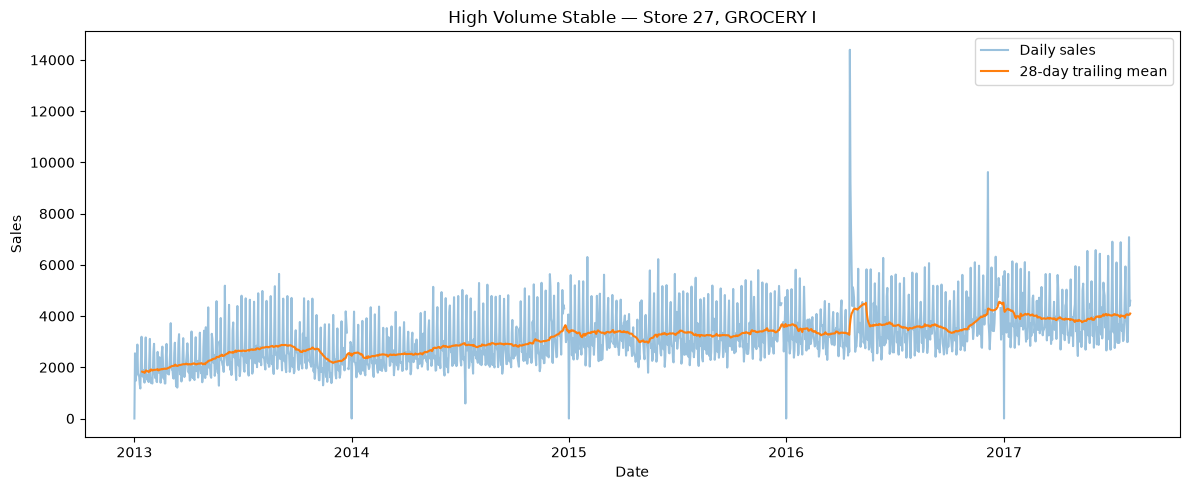

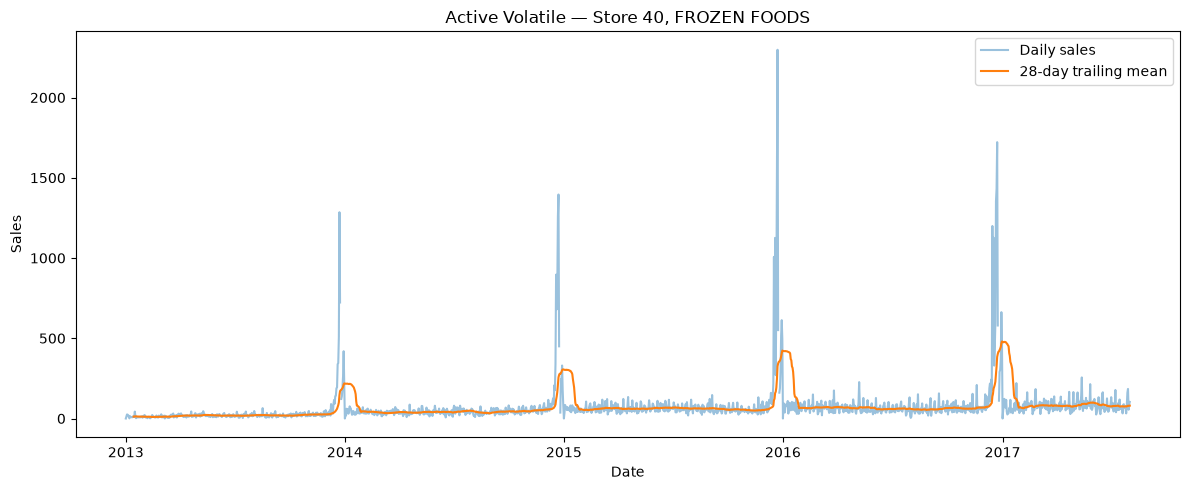

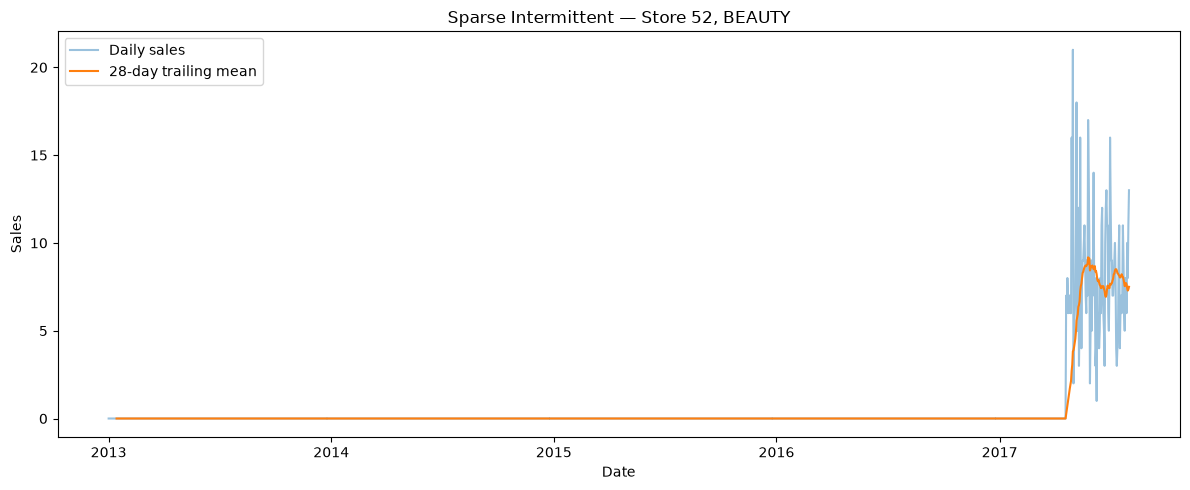

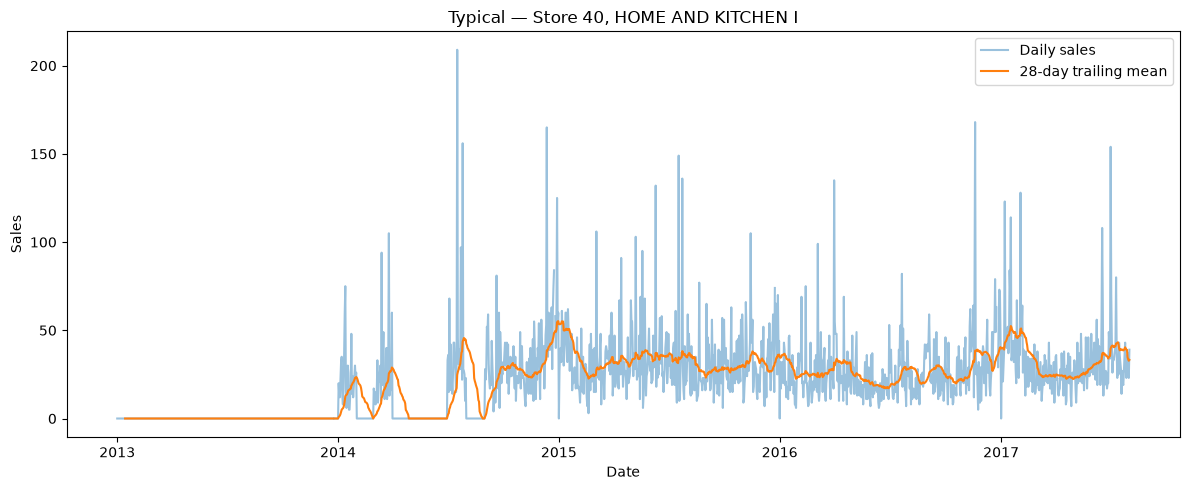

In [21]:
# Store the time-series diagnostic figures in the project documentation.
DIAGNOSTICS_FIGURES_DIR = (
    PROJECT_ROOT
    / "docs"
    / "assets"
    / "time_series_diagnostics"
)

DIAGNOSTICS_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


for archetype in selected_series["archetype"]:
    series = (
        regularized_series.loc[
            regularized_series["archetype"] == archetype
        ]
        .sort_values("date")
        .copy()
    )

    # Use a trailing four-week smoother to expose persistent level changes.
    series["rolling_mean_28"] = (
        series["sales"]
        .rolling(
            window=28,
            min_periods=14,
        )
        .mean()
    )

    store_nbr = series["store_nbr"].iloc[0]
    family = series["family"].iloc[0]

    plt.figure(figsize=(12, 5))

    plt.plot(
        series["date"],
        series["sales"],
        label="Daily sales",
        alpha=0.45,
    )

    plt.plot(
        series["date"],
        series["rolling_mean_28"],
        label="28-day trailing mean",
    )

    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.title(
        f"{archetype.replace('_', ' ').title()} — "
        f"Store {store_nbr}, {family}"
    )
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_development_history.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

### Initial Visual Diagnosis

The development-history plots reveal temporal structures that are not visible from
cross-sectional summary statistics alone.

- **High-volume stable demand** exhibits a clear long-term increase in its
  underlying demand level together with substantial short-term variation.
- **Typical demand** shows pronounced regime changes, including a long initial
  period of little or no activity followed by more persistent demand.
- **Active volatile demand** remains active on almost every day but exhibits
  exceptionally large recurring peaks around similar periods of successive
  years.
- The initially selected **sparse intermittent** series reveals a limitation of
  the original selection rule. Its high overall zero share is primarily caused
  by a long inactive period followed by sustained positive demand rather than
  by intermittent positive demand throughout its active history.

This demonstrates that overall `zero_share` alone cannot distinguish genuinely
intermittent demand from structural inactivity or late activation.

The sparse-series definition must therefore be refined before continuing with
the detailed seasonal diagnostics.

### Trend Takeaway

The development-history diagnostics show that demand levels are not uniformly stable
over time.

The high-volume series exhibits a gradual increase in its underlying demand
level, while other series display more abrupt regime changes or recurring
periods of unusually high demand.

A 28-day trailing mean is useful for visualizing these persistent level
changes, but it is only a descriptive smoother. Trend and level stability will
be examined more formally later through stationarity, differencing, and
classical forecasting models.

Before moving to weekly seasonality, the sparse-series archetype must be
refined because the initial `zero_share` criterion confounds genuine
intermittency with long periods of structural inactivity.

### 4.3 Refining the Intermittent-Demand Archetype

Visual inspection revealed that the initial sparse representative does not
exhibit genuinely intermittent demand. Its high overall `zero_share` is caused
primarily by a long inactive period followed by sustained positive demand.

Overall sparsity therefore conflates two different behaviors:

- **late activation or structural inactivity**, where demand is absent for a
  long contiguous period;
- **intermittent demand**, where zero-demand periods repeatedly occur between
  positive observations throughout the active lifetime of the series.

To distinguish them, two additional diagnostics are introduced:

- **active span share**: the fraction of the development history between the first and
  last positive-sale observations;
- **active zero share**: the fraction of observed zero-sales days within that
  active span.

A genuinely intermittent diagnostic series should remain sparse within a
sufficiently long active history rather than obtaining a high overall
`zero_share` solely from late activation.

In [22]:
# Measure each series' active lifetime and sparsity within the development window.
activity_profiles = run_athena_query(
    f"""
    WITH activity_bounds AS (
        SELECT
            store_nbr,
            family,
            MIN(CASE WHEN sales > 0 THEN date END) AS first_positive_date,
            MAX(CASE WHEN sales > 0 THEN date END) AS last_positive_date
        FROM retail_demand_forecasting_curated.stg_sales
        WHERE date <= DATE '{DEVELOPMENT_END_DATE_SQL}'
        GROUP BY
            store_nbr,
            family
    )

    SELECT
        s.store_nbr,
        s.family,
        b.first_positive_date,
        b.last_positive_date,

        DATE_DIFF(
            'day',
            b.first_positive_date,
            b.last_positive_date
        ) + 1 AS active_span_days,

        SUM(
            CASE
                WHEN s.date BETWEEN b.first_positive_date
                                AND b.last_positive_date
                THEN 1
                ELSE 0
            END
        ) AS observed_active_days,

        SUM(
            CASE
                WHEN s.date BETWEEN b.first_positive_date
                                AND b.last_positive_date
                     AND s.sales = 0
                THEN 1
                ELSE 0
            END
        ) AS active_zero_days

    FROM retail_demand_forecasting_curated.stg_sales AS s

    INNER JOIN activity_bounds AS b
        ON s.store_nbr = b.store_nbr
        AND s.family = b.family

    WHERE b.first_positive_date IS NOT NULL
      AND s.date <= DATE '{DEVELOPMENT_END_DATE_SQL}'

    GROUP BY
        s.store_nbr,
        s.family,
        b.first_positive_date,
        b.last_positive_date
    """
)

In [23]:
# Normalize Athena outputs before deriving active-period diagnostics.
activity_profiles["store_nbr"] = activity_profiles["store_nbr"].astype("string")
activity_profiles["first_positive_date"] = pd.to_datetime(
    activity_profiles["first_positive_date"]
)
activity_profiles["last_positive_date"] = pd.to_datetime(
    activity_profiles["last_positive_date"]
)

assert activity_profiles["last_positive_date"].max() <= DEVELOPMENT_END_DATE

numeric_columns = [
    "active_span_days",
    "observed_active_days",
    "active_zero_days",
]

activity_profiles[numeric_columns] = (
    activity_profiles[numeric_columns]
    .apply(pd.to_numeric)
)


# Compare each active lifetime with the full development calendar span.
DEVELOPMENT_CALENDAR_DAYS = len(calendar)

activity_profiles["active_span_share"] = (
    activity_profiles["active_span_days"]
    / DEVELOPMENT_CALENDAR_DAYS
)

activity_profiles["active_zero_share"] = (
    activity_profiles["active_zero_days"]
    / activity_profiles["observed_active_days"]
)

print("Active series:", len(activity_profiles))

display(activity_profiles.head())

Active series: 1729


,store_nbr,family,first_positive_date,last_positive_date,active_span_days,observed_active_days,active_zero_days,active_span_share,active_zero_share
0,1,AUTOMOTIVE,2013-01-02,2017-08-01,1673,1669,220,0.999403,0.131815
1,1,BEAUTY,2013-01-02,2017-08-01,1673,1669,253,0.999403,0.151588
2,1,BREAD/BAKERY,2013-01-02,2017-08-01,1673,1669,5,0.999403,0.002996
3,1,DELI,2013-01-02,2017-08-01,1673,1669,5,0.999403,0.002996
4,1,FROZEN FOODS,2013-01-02,2017-08-01,1673,1669,5,0.999403,0.002996


In [24]:
# Inspect why the initially selected sparse series appeared highly sparse.
initial_sparse_diagnostic = activity_profiles.loc[
    (activity_profiles["store_nbr"] == "52")
    & (activity_profiles["family"] == "BEAUTY")
]

display(initial_sparse_diagnostic)

,store_nbr,family,first_positive_date,last_positive_date,active_span_days,observed_active_days,active_zero_days,active_span_share,active_zero_share
410,52,BEAUTY,2017-04-20,2017-08-01,104,104,0,0.062127,0.0


In [25]:
# Inspect how active lifetime and within-lifetime sparsity vary across series.
activity_distribution = (
    activity_profiles[
        [
            "active_span_share",
            "active_zero_share",
        ]
    ]
    .quantile(
        [
            0.00,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            1.00,
        ]
    )
    .T
)

display(activity_distribution)

,0.00,0.10,0.25,0.50,0.75,0.90,0.95,1.00
active_span_share,0.002987,0.442055,0.781362,0.998805,0.999403,0.999403,0.999403,1.000000
active_zero_share,0.000000,0.002397,0.002397,0.062912,0.237867,0.583953,0.790638,0.991781


In [26]:
# Compare the currently selected archetypes using the refined activity metrics.
selected_activity_profiles = selected_series[
    [
        "archetype",
        "store_nbr",
        "family",
        "zero_share",
    ]
].merge(
    activity_profiles,
    on=["store_nbr", "family"],
    how="left",
    validate="one_to_one",
)

display(
    selected_activity_profiles[
        [
            "archetype",
            "store_nbr",
            "family",
            "zero_share",
            "active_span_share",
            "active_zero_share",
            "first_positive_date",
            "last_positive_date",
        ]
    ].style.hide(axis="index")
)

archetype,store_nbr,family,zero_share,active_span_share,active_zero_share,first_positive_date,last_positive_date
high_volume_stable,27,GROCERY I,0.002994,0.999403,0.002397,2013-01-02 00:00:00,2017-08-01 00:00:00
active_volatile,40,FROZEN FOODS,0.003593,0.999403,0.002996,2013-01-02 00:00:00,2017-08-01 00:00:00
sparse_intermittent,52,BEAUTY,0.937725,0.062127,0.000000,2017-04-20 00:00:00,2017-08-01 00:00:00
typical,40,HOME AND KITCHEN I,0.310180,0.781362,0.117241,2014-01-02 00:00:00,2017-08-01 00:00:00


In [27]:
# Define genuine intermittency using both a long active lifetime and high
# within-lifetime sparsity.
intermittent_thresholds = {
    "long_active_span_p50": activity_profiles["active_span_share"].quantile(0.50),
    "high_active_zero_share_p90": activity_profiles["active_zero_share"].quantile(0.90),
}

display(
    pd.Series(
        intermittent_thresholds,
        name="threshold",
    ).to_frame()
)


intermittent_activity_mask = (
    (
        activity_profiles["active_span_share"]
        >= intermittent_thresholds["long_active_span_p50"]
    )
    & (
        activity_profiles["active_zero_share"]
        >= intermittent_thresholds["high_active_zero_share_p90"]
    )
)

intermittent_activity_candidates = activity_profiles.loc[
    intermittent_activity_mask
].copy()

print(
    "Intermittent activity candidates:",
    len(intermittent_activity_candidates),
)

,threshold
long_active_span_p50,0.998805
high_active_zero_share_p90,0.583953


Intermittent activity candidates: 3


In [28]:
# Combine demand-profile and active-lifetime diagnostics for the intermittent
# candidate population.
intermittent_candidates = (
    positive_profiles
    .merge(
        intermittent_activity_candidates[
            [
                "store_nbr",
                "family",
                "active_span_share",
                "active_zero_share",
            ]
        ],
        on=["store_nbr", "family"],
        how="inner",
        validate="one_to_one",
    )
)

display(
    intermittent_candidates[
        [
            "store_nbr",
            "family",
            "mean_sales",
            "cv",
            "zero_share",
            "active_span_share",
            "active_zero_share",
        ]
    ]
    .sort_values("active_zero_share", ascending=False)
    .head(10)
    .style.hide(axis="index")
)

store_nbr,family,mean_sales,cv,zero_share,active_span_share,active_zero_share
32,BEAUTY,0.250299,2.063216,0.786228,0.999403,0.786099
35,SEAFOOD,0.540719,2.380422,0.755090,0.998805,0.754796
30,BEAUTY,0.596407,1.579501,0.620359,0.998805,0.619904


In [29]:
# Express the refined activity diagnostics on a common percentile scale.
for column in ["active_span_share", "active_zero_share"]:
    activity_profiles[f"{column}_pct"] = (
        activity_profiles[column].rank(pct=True)
    )

# Enrich the genuine-intermittent candidate population with demand-profile
# characteristics and global percentile ranks.
intermittent_candidate_profiles = (
    positive_profiles
    .merge(
        intermittent_activity_candidates[
            [
                "store_nbr",
                "family",
                "active_span_share",
                "active_zero_share",
            ]
        ],
        on=["store_nbr", "family"],
        how="inner",
        validate="one_to_one",
    )
    .merge(
        activity_profiles[
            [
                "store_nbr",
                "family",
                "active_span_share_pct",
                "active_zero_share_pct",
            ]
        ],
        on=["store_nbr", "family"],
        how="inner",
        validate="one_to_one",
    )
)

assert len(intermittent_candidate_profiles) == len(
    intermittent_activity_candidates
)

display(
    intermittent_candidate_profiles[
        [
            "store_nbr",
            "family",
            "mean_sales",
            "cv",
            "zero_share",
            "active_span_share",
            "active_zero_share",
            "active_span_share_pct",
            "active_zero_share_pct",
        ]
    ].style.hide(axis="index")
)

store_nbr,family,mean_sales,cv,zero_share,active_span_share,active_zero_share,active_span_share_pct,active_zero_share_pct
30,BEAUTY,0.596407,1.579501,0.620359,0.998805,0.619904,0.508097,0.906304
35,SEAFOOD,0.540719,2.380422,0.755090,0.998805,0.754796,0.508097,0.938693
32,BEAUTY,0.250299,2.063216,0.786228,0.999403,0.786099,0.753615,0.948525


In [30]:
intermittent_candidate_profiles.head()

,store_nbr,family,observations,mean_sales,std_sales,max_sales,zero_share,cv,mean_sales_pct,cv_pct,zero_share_pct,distance_to_typical,active_span_share,active_zero_share,active_span_share_pct,active_zero_share_pct
0,30,BEAUTY,1670,0.596407,0.942026,8.0,0.620359,1.579501,0.106998,0.773279,0.849624,0.592764,0.998805,0.619904,0.508097,0.906304
1,35,SEAFOOD,1670,0.540719,1.287138,13.0,0.755090,2.380422,0.101215,0.868710,0.888086,0.667523,0.998805,0.754796,0.508097,0.938693
2,32,BEAUTY,1670,0.250299,0.516422,3.0,0.786228,2.063216,0.063621,0.851938,0.895894,0.686308,0.999403,0.786099,0.753615,0.948525


In [31]:
# Select a representative intermittent series near the empirical center of
# the genuine-intermittent candidate population.
INTERMITTENCY_DIMENSIONS = [
    "active_span_share_pct",
    "active_zero_share_pct",
]

intermittent_center = (
    intermittent_candidate_profiles[
        INTERMITTENCY_DIMENSIONS
    ]
    .mean()
)

intermittent_candidate_profiles["distance_to_intermittent_center"] = np.sqrt(
    (
        (
            intermittent_candidate_profiles[INTERMITTENCY_DIMENSIONS]
            - intermittent_center
        ) ** 2
    ).sum(axis=1)
)

intermittent_representative = (
    intermittent_candidate_profiles
    .sort_values("distance_to_intermittent_center")
    .head(1)
    .copy()
)

display(
    intermittent_representative[
        [
            "store_nbr",
            "family",
            "mean_sales",
            "cv",
            "zero_share",
            "active_span_share",
            "active_zero_share",
            "distance_to_intermittent_center",
        ]
    ].style.hide(axis="index")
)

store_nbr,family,mean_sales,cv,zero_share,active_span_share,active_zero_share,distance_to_intermittent_center
35,SEAFOOD,0.540719,2.380422,0.755090,0.998805,0.754796,0.082184


In [32]:
# Replace the initial sparse representative with the refined intermittent one.
refined_intermittent_representative = intermittent_representative.copy()

refined_intermittent_representative["archetype"] = "sparse_intermittent"
refined_intermittent_representative["candidate_count"] = len(
    intermittent_candidate_profiles
)

# Match the schema of the existing representative table.
refined_intermittent_representative = (
    refined_intermittent_representative
    .reindex(columns=selected_series.columns)
)

selected_series = pd.concat(
    [
        selected_series.loc[
            selected_series["archetype"] != "sparse_intermittent"
        ],
        refined_intermittent_representative,
    ],
    ignore_index=True,
)

display(
    selected_series[
        [
            "archetype",
            "store_nbr",
            "family",
            "mean_sales",
            "cv",
            "zero_share",
            "candidate_count",
        ]
    ]
    .sort_values("archetype")
    .style.hide(axis="index")
)

archetype,store_nbr,family,mean_sales,cv,zero_share,candidate_count
active_volatile,40,FROZEN FOODS,70.545508,1.924204,0.003593,35
high_volume_stable,27,GROCERY I,3176.340719,0.348276,0.002994,109
sparse_intermittent,35,SEAFOOD,0.540719,2.380422,0.755090,3
typical,40,HOME AND KITCHEN I,21.186826,1.035775,0.310180,1729


### Refined Intermittent-Demand Representative

The initial sparse representative, Store 52 — BEAUTY, was selected from its
high overall `zero_share`. Visual inspection subsequently showed that this
series was not genuinely intermittent: it remained inactive for most of the
historical period and then became continuously active.

The refined activity diagnostics distinguish this late-activation pattern from
persistent intermittency by measuring sparsity only within the period between
the first and last positive-sale observations.

Using this refined definition, Store 35 — SEAFOOD is selected as the new
representative of sparse intermittent demand. Its active span covers almost the
entire development period, while approximately 75% of the observed days within
that span still have zero sales.

The following plot is generated separately rather than replacing the original
diagnostic figure. This preserves the analytical progression that motivated the
refinement.

In [33]:
# Retrieve only the refined intermittent representative within the development
# window so that the original sparse diagnostic remains preserved as part of
# the analytical history.
refined_store_nbr = int(intermittent_representative["store_nbr"].iloc[0])
refined_family = intermittent_representative["family"].iloc[0]
escaped_family = refined_family.replace("'", "''")

refined_intermittent_series = run_athena_query(
    f"""
    SELECT
        date,
        store_nbr,
        family,
        sales,
        onpromotion
    FROM retail_demand_forecasting_curated.stg_sales
    WHERE store_nbr = {refined_store_nbr}
      AND family = '{escaped_family}'
      AND date <= DATE '{DEVELOPMENT_END_DATE_SQL}'
    ORDER BY date
    """
)

# Normalize Athena outputs before time-series analysis.
refined_intermittent_series["date"] = pd.to_datetime(
    refined_intermittent_series["date"]
)
refined_intermittent_series["sales"] = pd.to_numeric(
    refined_intermittent_series["sales"]
)
refined_intermittent_series["onpromotion"] = pd.to_numeric(
    refined_intermittent_series["onpromotion"]
)

assert refined_intermittent_series["date"].max() <= DEVELOPMENT_END_DATE

print("Shape:", refined_intermittent_series.shape)
display(refined_intermittent_series.head())

Shape: (1670, 5)


,date,store_nbr,family,sales,onpromotion
0,2013-01-01,35,SEAFOOD,0.0,0
1,2013-01-02,35,SEAFOOD,0.0,0
2,2013-01-03,35,SEAFOOD,2.0,0
3,2013-01-04,35,SEAFOOD,2.0,0
4,2013-01-05,35,SEAFOOD,1.0,0


In [34]:
# Reindex the refined representative onto the same complete daily calendar
# used by the previous time-series diagnostics.
refined_intermittent_series = (
    refined_intermittent_series
    .set_index("date")
    .reindex(calendar)
    .rename_axis("date")
    .reset_index()
)

refined_intermittent_series["store_nbr"] = str(refined_store_nbr)
refined_intermittent_series["family"] = refined_family

print(
    "Calendar days:",
    len(refined_intermittent_series),
)
print(
    "Observed sales:",
    refined_intermittent_series["sales"].notna().sum(),
)
print(
    "Missing sales:",
    refined_intermittent_series["sales"].isna().sum(),
)

Calendar days: 1674
Observed sales: 1670
Missing sales: 4


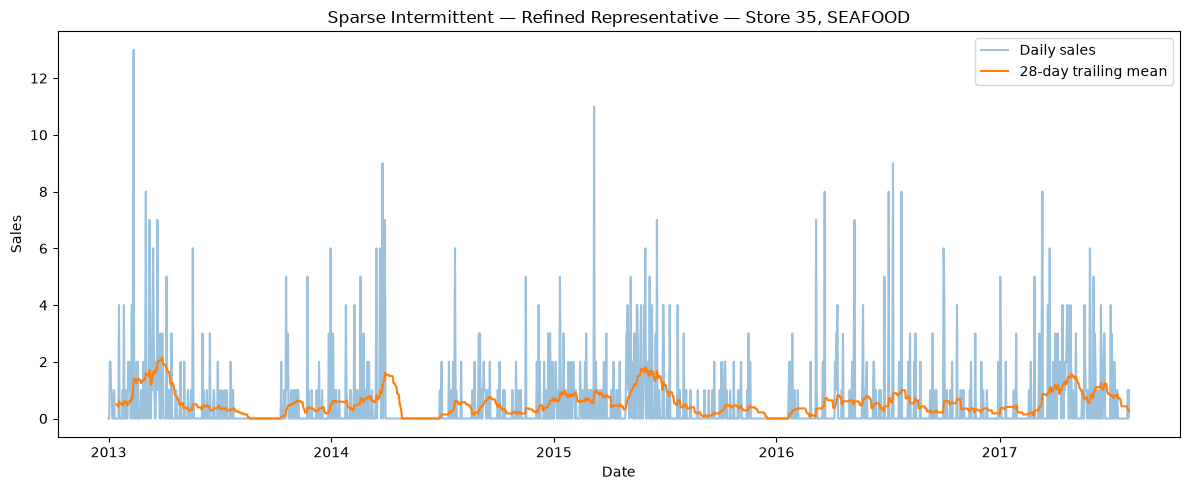

In [35]:
# Use the same trailing four-week smoother as in the initial visual diagnosis
# so that the refined representative is directly comparable.
refined_intermittent_series["rolling_mean_28"] = (
    refined_intermittent_series["sales"]
    .rolling(
        window=28,
        min_periods=14,
    )
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    refined_intermittent_series["date"],
    refined_intermittent_series["sales"],
    label="Daily sales",
    alpha=0.45,
)

plt.plot(
    refined_intermittent_series["date"],
    refined_intermittent_series["rolling_mean_28"],
    label="28-day trailing mean",
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title(
    "Sparse Intermittent — Refined Representative — "
    f"Store {refined_store_nbr}, {refined_family}"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    DIAGNOSTICS_FIGURES_DIR
    / "sparse_intermittent_refined_development_history.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

### Refined Intermittent-Demand Takeaway

Unlike the initial sparse representative, the refined series remains active
across almost the complete historical period while repeatedly returning to zero
sales.

Its sparsity is therefore distributed throughout its active lifetime rather
than concentrated in a long initial inactive regime. This visual behavior is
consistent with the refined quantitative definition of intermittent demand.

The comparison between the initial and refined representatives illustrates why
cross-sectional sparsity statistics should be complemented with temporal
diagnostics before assigning time-series behavior labels.

### 4.4 Weekly Seasonality

The long-term diagnostics showed that the representative series exhibit
different forms of level evolution, regime changes, volatility, and
intermittency.

The next question is whether demand also follows patterns that repeat at
regular calendar intervals.

Retail demand often exhibits weekly seasonality because customer behavior
depends on the day of the week. In a daily time series, a weekly seasonal
period corresponds to:

$$ m = 7 $$

A weekly seasonal structure means that observations separated by seven days
tend to occupy similar positions within a recurring weekly pattern.

The objective of this section is to determine whether such a pattern is
visible in the representative series, how strong it is, and whether it is
consistent across different demand behaviors.

#### Final Development Diagnostic Dataset

The intermittent-demand refinement changed one of the four representative
series. To preserve the earlier exploratory objects and figures, the final
diagnostic dataset is rebuilt separately from the finalized representative
selection.

Only observations available through 2017-08-01 are retrieved. This development
dataset will be used for the remaining seasonality, autocorrelation,
stationarity, and classical forecasting diagnostics; the final temporal holdout
remains excluded.

In [36]:
# Build the Athena filter from the finalized representative-series selection.
seasonality_conditions = []

for row in selected_series.itertuples(index=False):
    escaped_family = row.family.replace("'", "''")

    seasonality_conditions.append(
        f"(store_nbr = {int(row.store_nbr)} "
        f"AND family = '{escaped_family}')"
    )

seasonality_filter = " OR ".join(seasonality_conditions)


# Retrieve only the finalized diagnostic series within the development window.
final_diagnostic_series = run_athena_query(
    f"""
    SELECT
        date,
        store_nbr,
        family,
        sales,
        onpromotion
    FROM retail_demand_forecasting_curated.stg_sales
    WHERE ({seasonality_filter})
      AND date <= DATE '{DEVELOPMENT_END_DATE_SQL}'
    ORDER BY
        store_nbr,
        family,
        date
    """
)

final_diagnostic_series["date"] = pd.to_datetime(
    final_diagnostic_series["date"]
)
final_diagnostic_series["store_nbr"] = (
    final_diagnostic_series["store_nbr"].astype("string")
)
final_diagnostic_series["sales"] = pd.to_numeric(
    final_diagnostic_series["sales"]
)
final_diagnostic_series["onpromotion"] = pd.to_numeric(
    final_diagnostic_series["onpromotion"]
)

assert final_diagnostic_series["date"].max() <= DEVELOPMENT_END_DATE

final_diagnostic_series = final_diagnostic_series.merge(
    selected_series[
        [
            "store_nbr",
            "family",
            "archetype",
        ]
    ],
    on=["store_nbr", "family"],
    how="left",
    validate="many_to_one",
)

print("Shape:", final_diagnostic_series.shape)

display(
    final_diagnostic_series
    .groupby("archetype")
    .size()
    .rename("observations")
    .to_frame()
)

Shape: (6680, 6)


,observations
archetype,
active_volatile,1670
high_volume_stable,1670
sparse_intermittent,1670
typical,1670


In [37]:
# Reindex each finalized series onto the complete daily development calendar.
final_regularized_series = []

for selected in selected_series.itertuples(index=False):
    series = final_diagnostic_series.loc[
        (final_diagnostic_series["store_nbr"] == str(selected.store_nbr))
        & (final_diagnostic_series["family"] == selected.family)
    ].copy()

    series = (
        series
        .set_index("date")
        .reindex(calendar)
        .rename_axis("date")
        .reset_index()
    )

    series["store_nbr"] = str(selected.store_nbr)
    series["family"] = selected.family
    series["archetype"] = selected.archetype

    final_regularized_series.append(series)


final_regularized_series = pd.concat(
    final_regularized_series,
    ignore_index=True,
)

# Verify that the final diagnostic series share the same daily time grid.
display(
    final_regularized_series
    .groupby("archetype")
    .agg(
        calendar_days=("date", "size"),
        observed_sales=("sales", "count"),
        missing_sales=("sales", lambda values: values.isna().sum()),
    )
)

,calendar_days,observed_sales,missing_sales
archetype,,,
active_volatile,1674,1670,4
high_volume_stable,1674,1670,4
sparse_intermittent,1674,1670,4
typical,1674,1670,4


#### Short-Window Visual Inspection

Weekly patterns are difficult to identify on a multi-year plot because seven-day
cycles are visually compressed.

A shorter window is therefore examined before aggregating observations by day
of week. The purpose is to determine whether repeated within-week structures
are visible directly in the raw daily data.

This is a descriptive diagnostic only; the selected window is drawn entirely from the development period and is not
used as a model-validation period.

In [38]:
# Inspect the final eight weeks of development history so that repeated weekly patterns
# remain visible at daily granularity.
window_end = final_regularized_series["date"].max()
window_start = window_end - pd.Timedelta(weeks=8)

weekly_visual_window = final_regularized_series.loc[
    final_regularized_series["date"].between(
        window_start,
        window_end,
    )
].copy()

print("Window:", window_start.date(), "to", window_end.date())

Window: 2017-06-06 to 2017-08-01


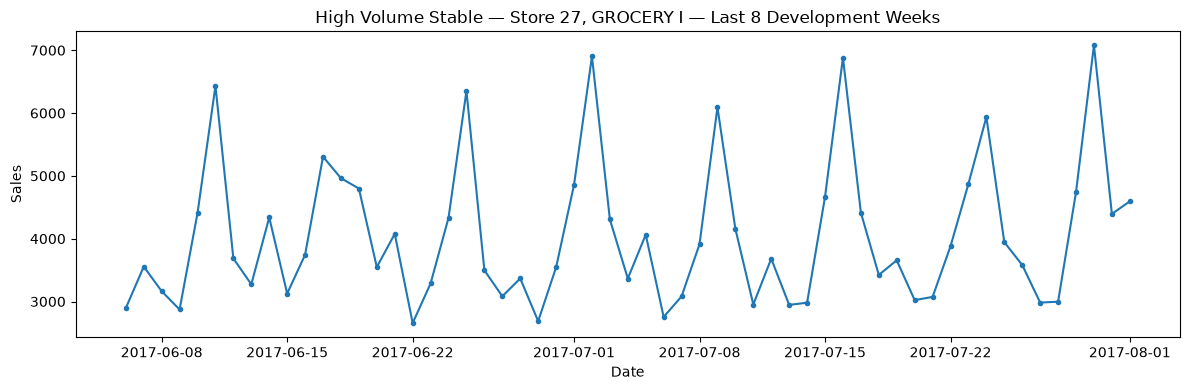

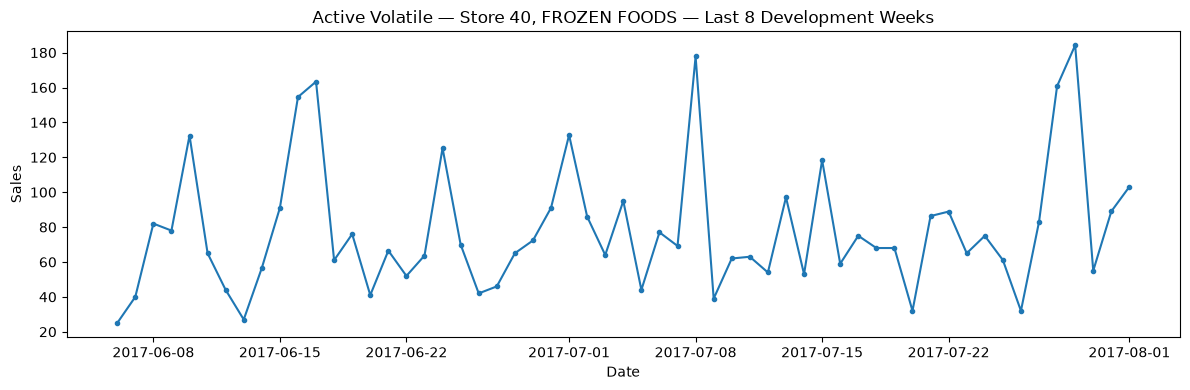

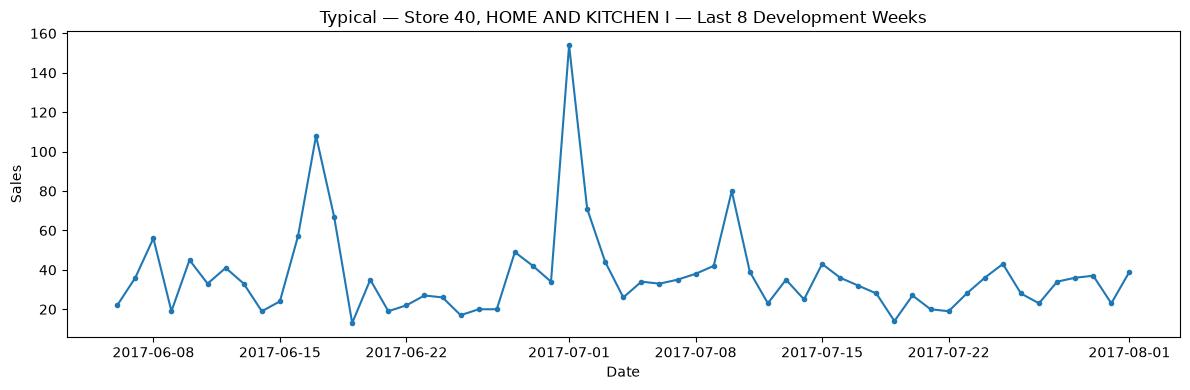

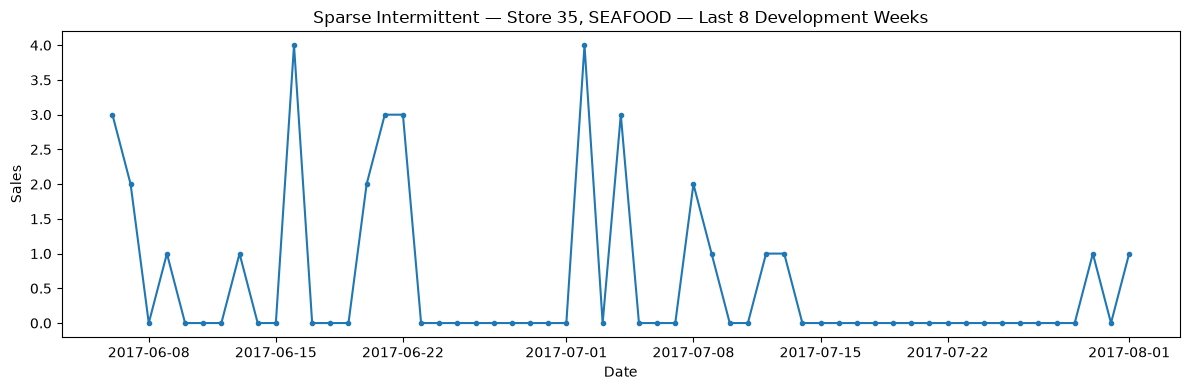

In [39]:
for archetype in selected_series["archetype"]:
    series = (
        weekly_visual_window.loc[
            weekly_visual_window["archetype"] == archetype
        ]
        .sort_values("date")
        .copy()
    )

    store_nbr = series["store_nbr"].iloc[0]
    family = series["family"].iloc[0]

    plt.figure(figsize=(12, 4))

    plt.plot(
        series["date"],
        series["sales"],
        marker="o",
        markersize=3,
    )

    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.title(
        f"{archetype.replace('_', ' ').title()} — "
        f"Store {store_nbr}, {family} — Last 8 Development Weeks"
    )
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_last_8_weeks.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

#### Day-of-Week Profiles

Visual inspection alone cannot establish weekly seasonality reliably.

To quantify the recurring weekly structure, sales are aggregated by day of
week for each representative series.

Because the selected series operate at very different sales scales, the raw
weekday means are also normalized by each series' overall mean:

$$ weekday\_index_d = \frac{\text{mean sales on weekday } d} {\text{overall mean sales}} $$

An index of `1.0` represents the series' average daily sales level. Values
above or below `1.0` indicate systematically stronger or weaker demand on that
weekday.

This allows weekly shapes to be compared across series without allowing demand
scale to dominate the comparison.

In [40]:
WEEKDAY_ORDER = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

weekday_profiles = final_regularized_series.dropna(
    subset=["sales"]
).copy()

weekday_profiles["weekday"] = (
    weekday_profiles["date"].dt.day_name()
)

weekday_profiles["weekday"] = pd.Categorical(
    weekday_profiles["weekday"],
    categories=WEEKDAY_ORDER,
    ordered=True,
)


# Compute the absolute weekday demand profile.
weekday_summary = (
    weekday_profiles
    .groupby(
        ["archetype", "weekday"],
        observed=True,
    )
    .agg(
        mean_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        observations=("sales", "size"),
    )
    .reset_index()
)


# Normalize weekday means by each series' overall mean demand.
overall_means = (
    weekday_profiles
    .groupby("archetype")["sales"]
    .mean()
    .rename("overall_mean_sales")
)

weekday_summary = weekday_summary.merge(
    overall_means,
    on="archetype",
    how="left",
    validate="many_to_one",
)

weekday_summary["weekday_index"] = (
    weekday_summary["mean_sales"]
    / weekday_summary["overall_mean_sales"]
)

display(weekday_summary)

,archetype,weekday,mean_sales,median_sales,observations,overall_mean_sales,weekday_index
0,active_volatile,Monday,59.952644,39.0000,239,70.545508,0.849844
1,active_volatile,Tuesday,69.658008,44.1775,240,70.545508,0.987419
2,active_volatile,Wednesday,68.331345,47.1575,238,70.545508,0.968614
3,active_volatile,Thursday,71.838723,51.0000,238,70.545508,1.018332
4,active_volatile,Friday,73.215677,56.0000,238,70.545508,1.037850
5,active_volatile,Saturday,97.472690,80.0000,239,70.545508,1.381699
6,active_volatile,Sunday,53.288294,43.5785,238,70.545508,0.755375
7,high_volume_stable,Monday,3216.937238,3135.0000,239,3176.340719,1.012781
8,high_volume_stable,Tuesday,2742.250000,2721.5000,240,3176.340719,0.863336
9,high_volume_stable,Wednesday,2982.890756,2947.0000,238,3176.340719,0.939097


#### Normalized Weekly Seasonal Profiles

The weekday averages indicate that several representative series exhibit
systematic differences across the week.

To compare these patterns directly despite large differences in sales scale,
the normalized `weekday_index` is plotted for all four archetypes.

A value of `1.0` represents the overall average daily sales level of a series.
Values above or below this baseline indicate weekdays associated with
systematically stronger or weaker average demand.

For the intermittent series, however, the weekday mean combines both the
probability of observing positive demand and the magnitude of demand when it
occurs. These two mechanisms will therefore be examined separately afterward.

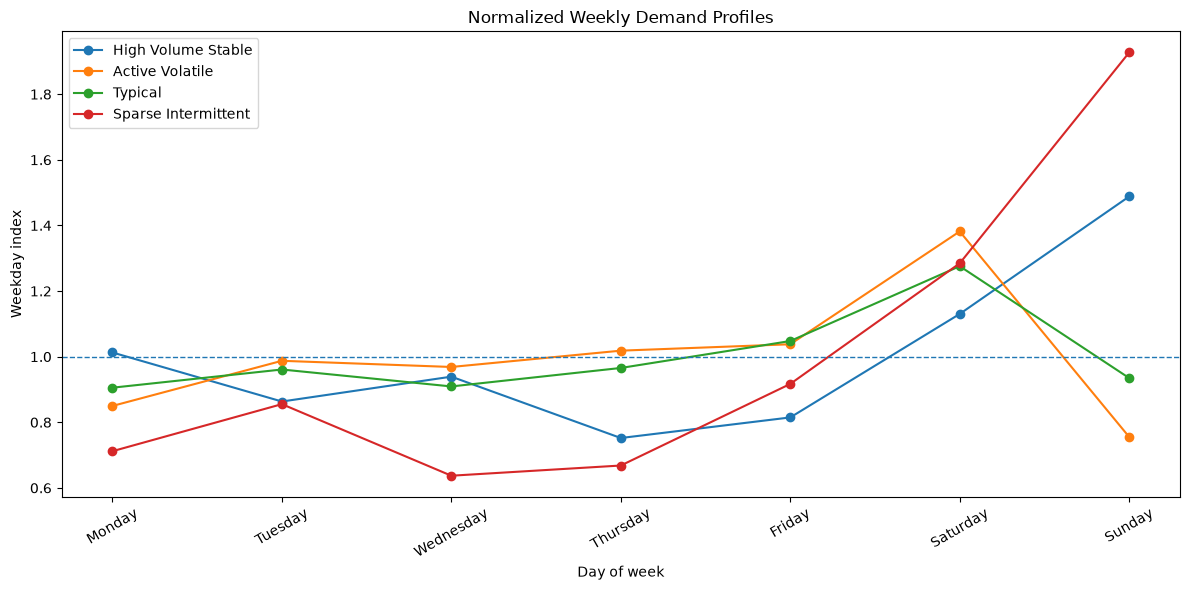

In [41]:
plt.figure(figsize=(12, 6))

for archetype in selected_series["archetype"]:
    profile = (
        weekday_summary.loc[
            weekday_summary["archetype"] == archetype
        ]
        .sort_values("weekday")
    )

    plt.plot(
        profile["weekday"],
        profile["weekday_index"],
        marker="o",
        label=archetype.replace("_", " ").title(),
    )

# A value of one corresponds to each series' overall average demand.
plt.axhline(
    y=1.0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Day of week")
plt.ylabel("Weekday index")
plt.title("Normalized Weekly Demand Profiles")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    DIAGNOSTICS_FIGURES_DIR
    / "normalized_weekday_profiles.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

#### Intermittent Demand: Occurrence vs. Positive-Demand Size

For an intermittent series, a higher weekday average can arise through two
different mechanisms:

1. positive demand occurs more frequently on that weekday;
2. demand is larger when a positive observation occurs.

For non-negative demand:

$$ E[Y \mid d] = P(Y > 0 \mid d) \times E[Y \mid Y > 0, d] $$

where $d$ denotes the day of week.

The intermittent representative is therefore decomposed into:

- **positive-demand rate**: the probability that sales are greater than zero;
- **conditional positive mean**: average sales given that positive demand
  occurs.

This distinguishes seasonality in demand occurrence from seasonality in demand
magnitude.

In [42]:
# Decompose intermittent weekday demand into occurrence frequency and
# positive-demand magnitude.
intermittent_weekdays = weekday_profiles.loc[
    weekday_profiles["archetype"] == "sparse_intermittent"
].copy()

intermittent_weekday_decomposition = (
    intermittent_weekdays
    .groupby(
        "weekday",
        observed=True,
    )
    .agg(
        observations=("sales", "size"),
        positive_days=("sales", lambda values: (values > 0).sum()),
        mean_sales=("sales", "mean"),
        mean_positive_sales=(
            "sales",
            lambda values: values.loc[values > 0].mean(),
        ),
    )
    .reset_index()
)

intermittent_weekday_decomposition["positive_demand_rate"] = (
    intermittent_weekday_decomposition["positive_days"]
    / intermittent_weekday_decomposition["observations"]
)

display(intermittent_weekday_decomposition)

,weekday,observations,positive_days,mean_sales,mean_positive_sales,positive_demand_rate
0,Monday,239,45,0.384937,2.044444,0.188285
1,Tuesday,240,58,0.462500,1.913793,0.241667
2,Wednesday,238,45,0.344538,1.822222,0.189076
3,Thursday,238,51,0.361345,1.686275,0.214286
4,Friday,238,54,0.495798,2.185185,0.226891
5,Saturday,239,74,0.694561,2.243243,0.309623
6,Sunday,238,82,1.042017,3.024390,0.344538


In [43]:
# Verify the occurrence × magnitude decomposition of average demand.
intermittent_weekday_decomposition["reconstructed_mean"] = (
    intermittent_weekday_decomposition["positive_demand_rate"]
    * intermittent_weekday_decomposition["mean_positive_sales"]
)

display(
    intermittent_weekday_decomposition[
        [
            "weekday",
            "mean_sales",
            "positive_demand_rate",
            "mean_positive_sales",
            "reconstructed_mean",
        ]
    ]
)

,weekday,mean_sales,positive_demand_rate,mean_positive_sales,reconstructed_mean
0,Monday,0.384937,0.188285,2.044444,0.384937
1,Tuesday,0.462500,0.241667,1.913793,0.462500
2,Wednesday,0.344538,0.189076,1.822222,0.344538
3,Thursday,0.361345,0.214286,1.686275,0.361345
4,Friday,0.495798,0.226891,2.185185,0.495798
5,Saturday,0.694561,0.309623,2.243243,0.694561
6,Sunday,1.042017,0.344538,3.024390,1.042017


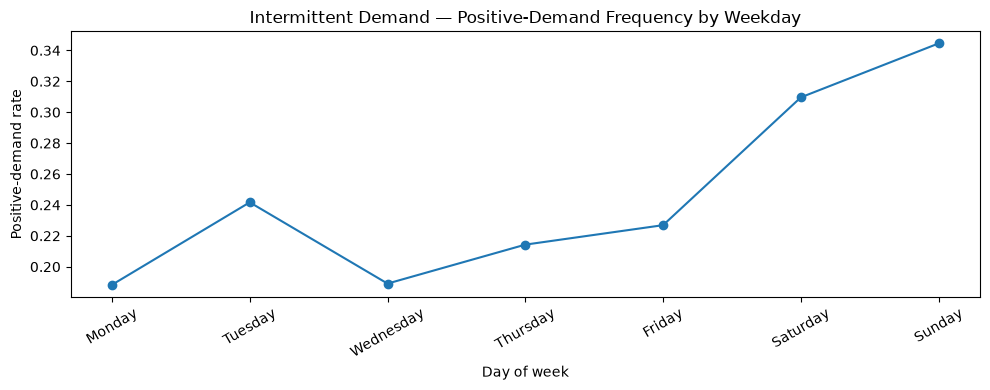

In [44]:
plt.figure(figsize=(10, 4))

plt.plot(
    intermittent_weekday_decomposition["weekday"],
    intermittent_weekday_decomposition["positive_demand_rate"],
    marker="o",
)

plt.xlabel("Day of week")
plt.ylabel("Positive-demand rate")
plt.title("Intermittent Demand — Positive-Demand Frequency by Weekday")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    DIAGNOSTICS_FIGURES_DIR
    / "intermittent_positive_demand_rate_by_weekday.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

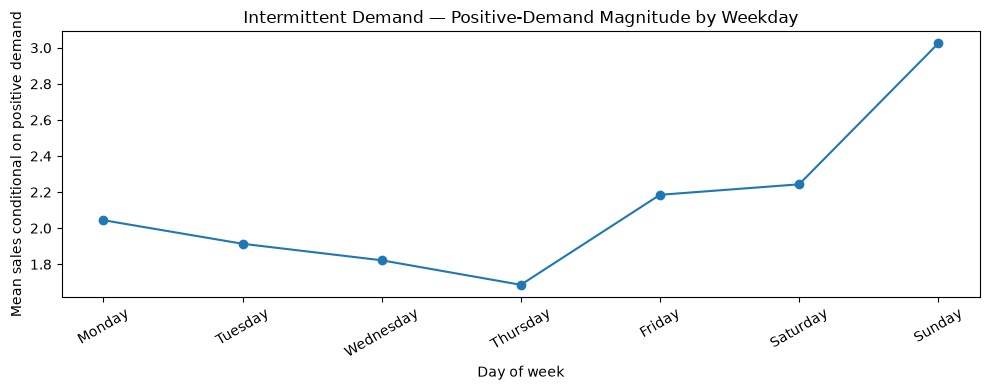

In [45]:
plt.figure(figsize=(10, 4))

plt.plot(
    intermittent_weekday_decomposition["weekday"],
    intermittent_weekday_decomposition["mean_positive_sales"],
    marker="o",
)

plt.xlabel("Day of week")
plt.ylabel("Mean sales conditional on positive demand")
plt.title("Intermittent Demand — Positive-Demand Magnitude by Weekday")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    DIAGNOSTICS_FIGURES_DIR
    / "intermittent_positive_demand_magnitude_by_weekday.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

### Weekly Seasonality Takeaway

The representative series exhibit materially different weekly demand patterns.

- **High-volume stable demand** shows the strongest broad weekly structure,
  with substantially higher Sunday demand and weaker demand around Thursday
  and Friday.
- **Typical demand** exhibits a more moderate weekly effect, driven primarily
  by stronger Saturday sales.
- **Active volatile demand** also shows a clear Saturday effect despite its
  much larger irregular fluctuations, demonstrating that high volatility does
  not imply an absence of recurring seasonal structure.
- **Sparse intermittent demand** exhibits a pronounced weekend effect, but its
  weekday averages combine two distinct mechanisms: how often positive demand
  occurs and how large demand is when it occurs.

For the intermittent representative, Saturday demand is elevated mainly
because positive demand occurs more frequently. Sunday combines both a higher
probability of positive demand and a larger conditional demand magnitude.
Other weekdays illustrate that these two mechanisms can also offset one
another.

The diagnostics therefore provide strong descriptive evidence of weekly
calendar structure, but show that seasonality can manifest differently across
demand behaviors. For intermittent demand in particular, seasonality may affect
both the occurrence and the magnitude of demand.

These patterns do not imply that weekday alone explains demand: promotions,
holidays, level changes, and other temporal effects may also contribute to the
observed variation.

The next step is to examine temporal dependence directly. If past observations
contain information about future demand, particularly across weekly intervals,
this should appear in lagged relationships and autocorrelation.

## 5. Lagged Dependence and Autocorrelation

The previous section identified recurring weekly calendar patterns across the
representative series.

Calendar seasonality answers the question:

> Does demand systematically differ according to where an observation falls
> within the week?

A different but related question is whether the **realized historical demand
itself** contains information about future demand.

This section examines temporal dependence through lagged observations and
autocorrelation. In particular, it investigates whether demand today is related
to demand one day, one week, or several weeks earlier.

Understanding these dependencies serves two purposes:

- it provides the statistical foundation for classical autoregressive models;
- it helps justify lagged-demand features such as `lag_1`, `lag_7`, and
  `lag_14` in the later global machine-learning model.

### 5.1 Selected Lag Correlations

Before examining the full autocorrelation function, a small set of interpretable
lags is evaluated directly.

The selected lags correspond to:

- `1` day: very short-term dependence;
- `7` days: one weekly cycle;
- `14` days: two weekly cycles;
- `21` days: three weekly cycles;
- `28` days: four weekly cycles.

For each representative series, the correlation between current sales and the
corresponding lagged sales is computed using only date pairs for which both
observations are available.

Because the series have been reindexed onto a complete daily calendar (due to the 4 missing Xmas days in the initial series), these
row lags correspond directly to calendar-day lags.

In [46]:
# Measure direct linear dependence at a small set of interpretable lags.
SELECTED_LAGS = [1, 7, 14, 21, 28]

lag_correlation_records = []

for archetype in selected_series["archetype"]:
    series = (
        final_regularized_series.loc[
            final_regularized_series["archetype"] == archetype
        ]
        .sort_values("date")
        .copy()
    )

    for lag in SELECTED_LAGS:
        lag_correlation = series["sales"].corr(
            series["sales"].shift(lag)
        )

        lag_correlation_records.append(
            {
                "archetype": archetype,
                "lag": lag,
                "lag_correlation": lag_correlation,
            }
        )


selected_lag_correlations = pd.DataFrame(
    lag_correlation_records
)

display(
    selected_lag_correlations.pivot(
        index="archetype",
        columns="lag",
        values="lag_correlation",
    )
)

lag,1,7,14,21,28
archetype,,,,,
active_volatile,0.725289,0.393105,0.112202,0.038291,0.026241
high_volume_stable,0.480167,0.736125,0.739003,0.713340,0.731057
sparse_intermittent,0.136631,0.136084,0.124428,0.127106,0.064871
typical,0.528015,0.451965,0.419672,0.361591,0.322868


### 5.2 Autocorrelation and Partial Autocorrelation

Selected lag correlations showed that temporal dependence differs strongly
across the representative demand behaviors.

The **autocorrelation function (ACF)** generalizes this analysis across a
sequence of lags:

$$ ACF(k) = Corr(y_t, y_{t-k}) $$

It measures the total linear association between current demand and demand
observed $ k $ days earlier.

The **partial autocorrelation function (PACF)** asks a different question. At
lag $ k $, it measures the remaining association between $ y_t $ and
$ y_{t-k} $ after accounting for the intermediate lags
$ 1,\ldots,k-1 $.

ACF therefore captures both direct and indirect lagged relationships, while
PACF helps identify which lags may contribute additional direct information.

However, neither diagnostic automatically removes trend, level shifts, or
seasonality. Non-stationary structure can therefore produce persistent or
misleading autocorrelation patterns.

The initial ACF and PACF plots are consequently treated as diagnostics of the
raw series rather than as direct model-order selection tools. They will later
be revisited after examining stationarity and differencing.

#### 5.2.1 Why Stationarity Matters for Autocorrelation

Lag correlations measure relationships between observations separated by a
fixed amount of time. Their interpretation becomes more difficult when the
statistical properties of the series themselves change over time.

A weakly stationary time series has a stable mean and variance:

$$
E[Y_t] = \mu
$$

$$
Var(Y_t) = \sigma^2
$$

and its covariance structure depends only on the lag between observations:

$$
Cov(Y_t, Y_{t-k}) = \gamma(k)
$$

rather than on the particular date at which the relationship is measured.

Stationarity does not imply an absence of temporal dependence. A stationary
series can still exhibit strong autocorrelation. Instead, it means that the
underlying probabilistic structure remains stable over time.

This distinction matters because trend, level shifts, and seasonality can
produce persistent autocorrelation even when a particular historical
observation has no direct predictive effect at that lag.

The raw ACF and PACF will therefore be treated as descriptive diagnostics.
Stationarity and differencing will subsequently be examined explicitly before
using these diagnostics to motivate classical model specifications.

#### 5.2.2 Raw ACF and PACF Diagnostics

The selected lag correlations examined only a small number of predefined
horizons. The next step generalizes this analysis across the first 35 daily
lags, corresponding to five weekly cycles.

The autocorrelation function measures the total linear association between
current demand and its past values:

$$
ACF(k) = Corr(Y_t, Y_{t-k})
$$

The partial autocorrelation function instead measures the additional
association with lag $ k $ after accounting for the intermediate lags
$ 1,\ldots,k-1 $.

The raw series are examined first. These plots are descriptive diagnostics:
trend, level shifts, and seasonality may themselves generate persistent
autocorrelation, so the results should not yet be interpreted as final
AR or MA model-order choices.

The four missing Christmas observations remain explicitly represented on the
daily calendar. ACF estimation uses missing-value-aware calculations, while
PACF is estimated from calendar-aligned lag regressions so that a lag of
$ k $ always corresponds to exactly $ k $ calendar days.

In [47]:
from statsmodels.tsa.stattools import acf

# Compute raw ACF values while preserving the daily calendar and treating
# missing observations conservatively.
MAX_LAG = 35

acf_records = []

for archetype in selected_series["archetype"]:
    series = (
        final_regularized_series.loc[
            final_regularized_series["archetype"] == archetype
        ]
        .sort_values("date")
    )

    acf_values = acf(
        series["sales"],
        nlags=MAX_LAG,
        missing="conservative",
        fft=False,
    )

    for lag, value in enumerate(acf_values):
        acf_records.append(
            {
                "archetype": archetype,
                "lag": lag,
                "acf": value,
            }
        )

raw_acf = pd.DataFrame(acf_records)

In [48]:
import statsmodels.api as sm

def calendar_safe_pacf(series, max_lag):
    """
    Estimate PACF through calendar-aligned OLS regressions.

    Lag columns are created before incomplete rows are removed, ensuring that
    each lag always represents the correct number of calendar days.
    """
    data = pd.DataFrame(
        {
            "sales": series.astype(float),
        }
    )

    # Create all calendar-aligned lag columns before handling missing values.
    for lag in range(1, max_lag + 1):
        data[f"lag_{lag}"] = data["sales"].shift(lag)

    pacf_values = [1.0]

    for lag in range(1, max_lag + 1):
        required_columns = [
            "sales",
            *[f"lag_{k}" for k in range(1, lag + 1)],
        ]

        regression_data = data[
            required_columns
        ].dropna()

        y = regression_data["sales"]

        X = regression_data[
            [f"lag_{k}" for k in range(1, lag + 1)]
        ]

        X = sm.add_constant(X)

        model = sm.OLS(
            y,
            X,
        ).fit()

        # PACF(k) is the coefficient associated with the furthest lag in AR(k).
        pacf_values.append(
            model.params[f"lag_{lag}"]
        )

    return np.array(pacf_values)

In [49]:
pacf_records = []

for archetype in selected_series["archetype"]:
    series = (
        final_regularized_series.loc[
            final_regularized_series["archetype"] == archetype
        ]
        .sort_values("date")["sales"]
    )

    pacf_values = calendar_safe_pacf(
        series,
        max_lag=MAX_LAG,
    )

    for lag, value in enumerate(pacf_values):
        pacf_records.append(
            {
                "archetype": archetype,
                "lag": lag,
                "pacf": value,
            }
        )

raw_pacf = pd.DataFrame(pacf_records)

In [50]:
# Compare ACF values with the previously computed direct lag correlations.
acf_selected_lags = (
    raw_acf.loc[
        raw_acf["lag"].isin(SELECTED_LAGS)
    ]
    .pivot(
        index="archetype",
        columns="lag",
        values="acf",
    )
)

display(acf_selected_lags)

lag,1,7,14,21,28
archetype,,,,,
active_volatile,0.712439,0.391353,0.112011,0.038220,0.026172
high_volume_stable,0.477526,0.719599,0.723532,0.692578,0.705348
sparse_intermittent,0.136418,0.135843,0.124123,0.126393,0.064297
typical,0.523535,0.450036,0.416433,0.357497,0.318174


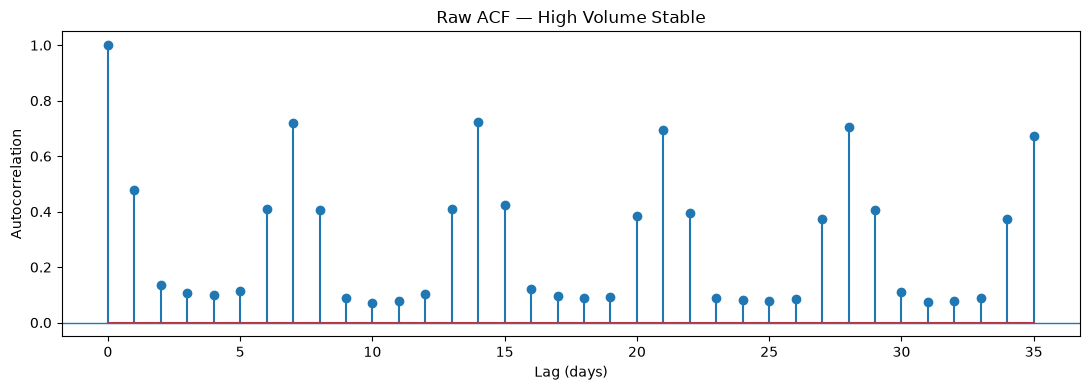

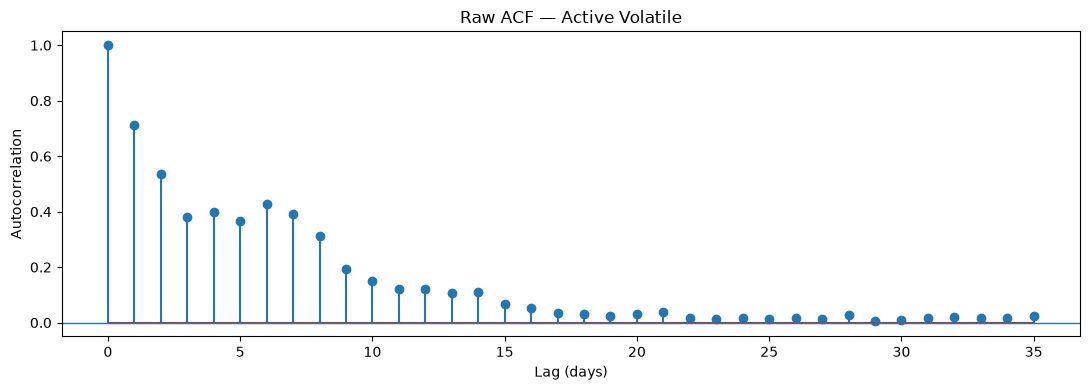

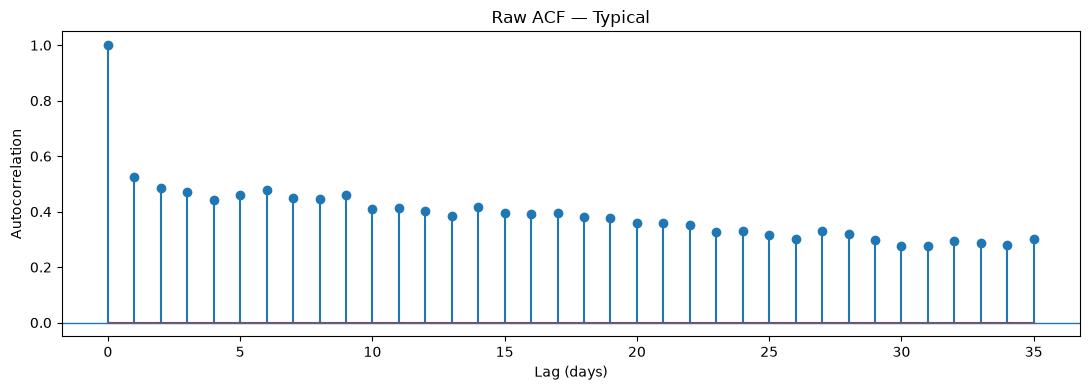

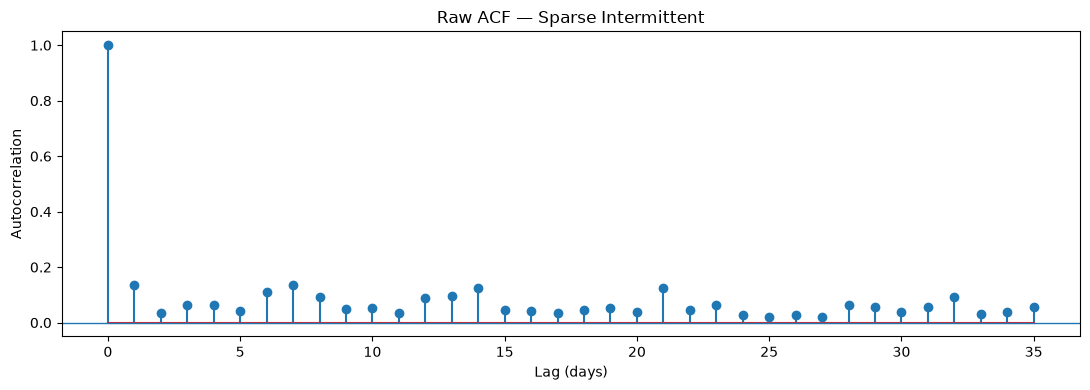

In [51]:
for archetype in selected_series["archetype"]:
    profile = raw_acf.loc[
        raw_acf["archetype"] == archetype
    ]

    plt.figure(figsize=(11, 4))

    plt.stem(
        profile["lag"],
        profile["acf"],
    )

    plt.axhline(
        0,
        linewidth=1,
    )

    plt.xlabel("Lag (days)")
    plt.ylabel("Autocorrelation")
    plt.title(
        f"Raw ACF — {archetype.replace('_', ' ').title()}"
    )
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_raw_acf.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

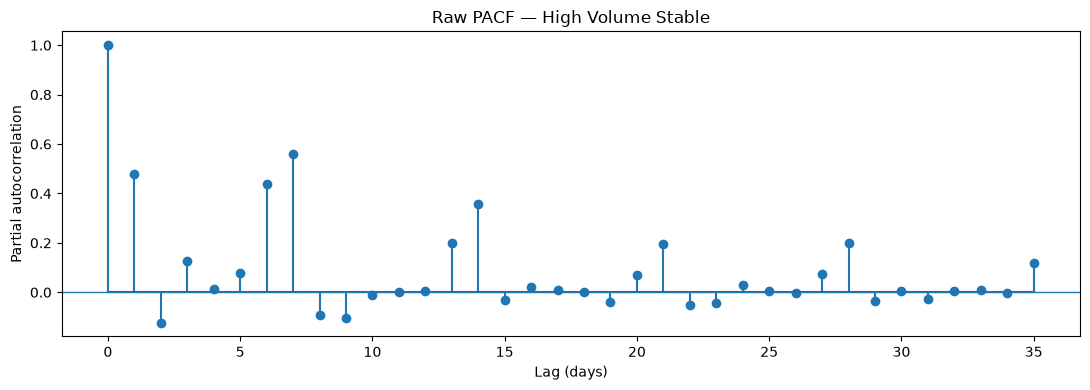

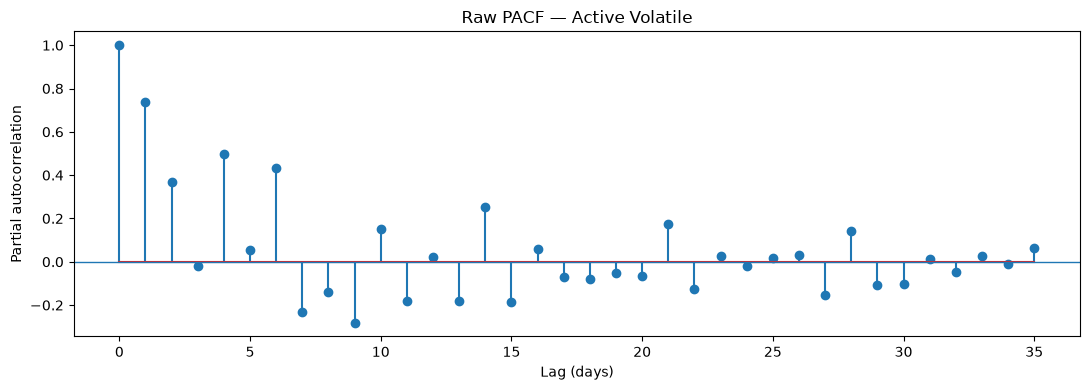

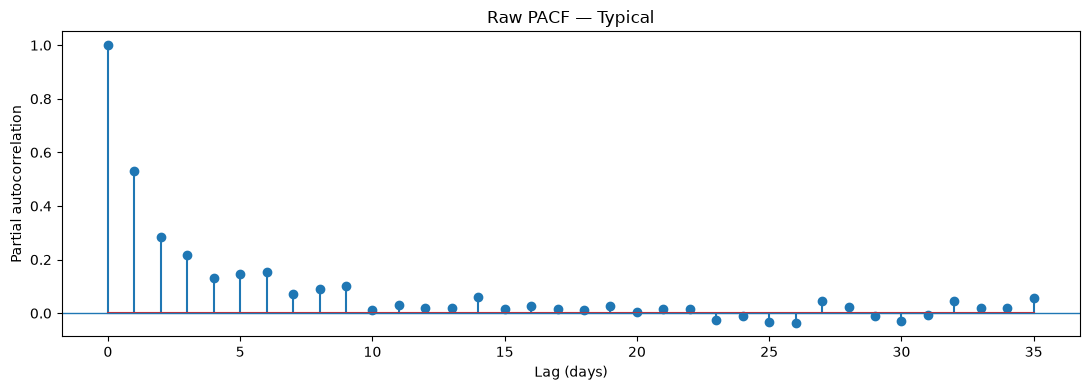

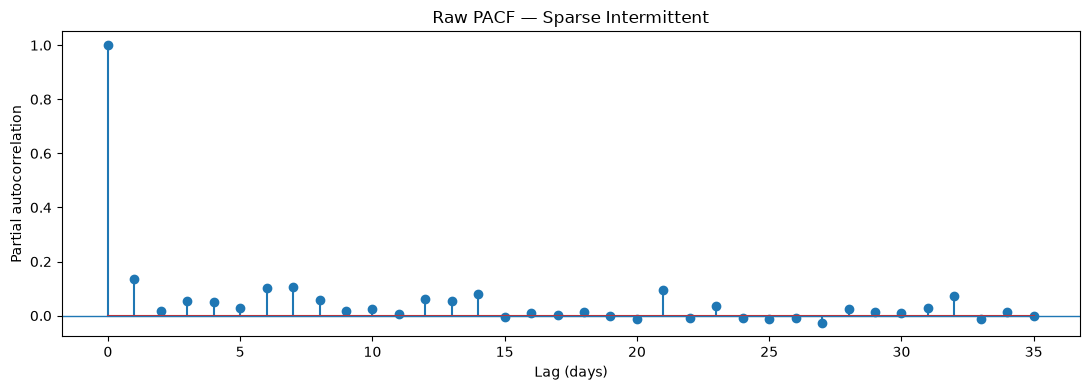

In [52]:
for archetype in selected_series["archetype"]:
    profile = raw_pacf.loc[
        raw_pacf["archetype"] == archetype
    ]

    plt.figure(figsize=(11, 4))

    plt.stem(
        profile["lag"],
        profile["pacf"],
    )

    plt.axhline(
        0,
        linewidth=1,
    )

    plt.xlabel("Lag (days)")
    plt.ylabel("Partial autocorrelation")
    plt.title(
        f"Raw PACF — {archetype.replace('_', ' ').title()}"
    )
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_raw_pacf.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

#### Raw ACF/PACF Takeaway

The raw autocorrelation diagnostics reveal strongly heterogeneous forms of
temporal dependence across the representative series.

- **High-volume stable demand** exhibits a pronounced seven-day structure.
  Autocorrelation rises sharply at weekly multiples (`7`, `14`, `21`, `28`,
  and `35` days), confirming persistent weekly dependence in realized demand.
- **Active volatile demand** displays strong short-term persistence followed
  by a gradual decay in autocorrelation. Its PACF concentrates much more of
  this dependence in the first few lags, suggesting that the long ACF tail is
  largely propagated through shorter-term relationships.
- **Typical demand** shows persistent autocorrelation across many lags. Given
  the level and regime changes previously observed in this series, part of this
  persistence may reflect non-stationary structure rather than a large number
  of directly informative historical lags.
- **Sparse intermittent demand** exhibits comparatively weak dependence in raw
  sales quantities. This remains compatible with its weekday effects, which
  were shown to operate substantially through the probability of positive
  demand rather than through strong continuity in realized sales quantities.

These are raw-series diagnostics. Trend, level changes, and seasonality remain
present and may distort classical ACF/PACF interpretation. Stationarity must
therefore be examined before using these plots to motivate specific
autoregressive or moving-average model orders.

## 6. Stationarity and Differencing

The raw ACF and PACF diagnostics revealed persistent temporal dependence, but
these relationships cannot yet be interpreted purely as autoregressive or
moving-average structure.

Trend, level shifts, and other changes in the statistical properties of a
series can themselves generate strong autocorrelation.

A weakly stationary process has a stable mean and variance:

$$
E[Y_t] = \mu
$$

$$
Var(Y_t) = \sigma^2
$$

and its covariance at a given lag depends only on that lag:

$$
Cov(Y_t, Y_{t-k}) = \gamma(k)
$$

rather than on the specific date at which the relationship is observed.

This section examines whether the representative demand series approximately
satisfy these conditions and, when they do not, whether differencing can
produce a more stable temporal process.

The objective is not to force every retail series into a stationary form.
Stationarity is primarily required for the classical ARIMA-style modeling and
for a clean interpretation of ACF/PACF diagnostics; the later global
tree-based forecasting model does not impose this requirement.

### 6.1 Rolling Mean and Variability

A first stationarity diagnostic is to examine whether the local mean and local
variability remain approximately stable through time.

For each representative series, an 84-day trailing window is used:

$$
84 = 12 \times 7
$$

This covers twelve complete weekly cycles, reducing sensitivity to individual
weekday effects while remaining short enough to reveal medium-term changes in
the demand-generating process.

The rolling statistics are descriptive diagnostics rather than formal
stationarity tests.

In [53]:
# Compute local mean and variability over twelve complete weekly cycles.
STATIONARITY_WINDOW = 84

stationarity_profiles = final_regularized_series.copy()

stationarity_profiles = (
    stationarity_profiles
    .sort_values(["archetype", "date"])
)

stationarity_profiles["rolling_mean_84"] = (
    stationarity_profiles
    .groupby("archetype")["sales"]
    .transform(
        lambda values: values.rolling(
            window=STATIONARITY_WINDOW,
            min_periods=STATIONARITY_WINDOW // 2,
        ).mean()
    )
)

stationarity_profiles["rolling_std_84"] = (
    stationarity_profiles
    .groupby("archetype")["sales"]
    .transform(
        lambda values: values.rolling(
            window=STATIONARITY_WINDOW,
            min_periods=STATIONARITY_WINDOW // 2,
        ).std()
    )
)

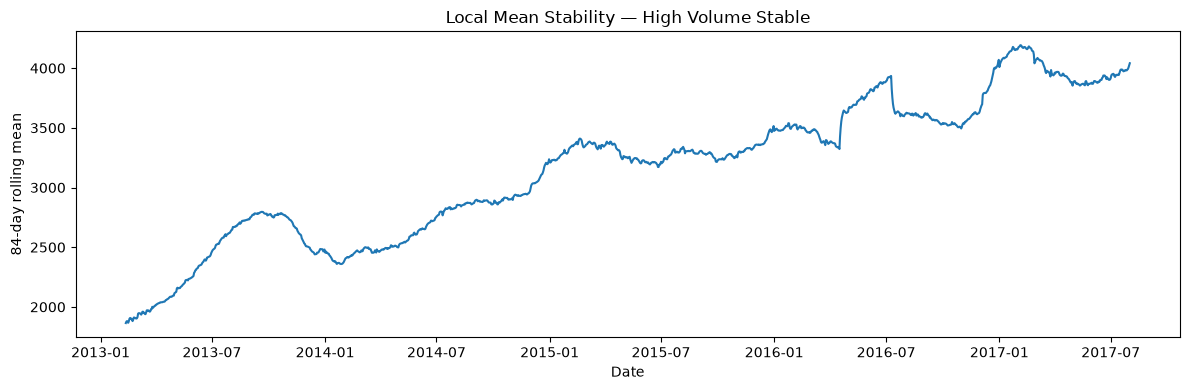

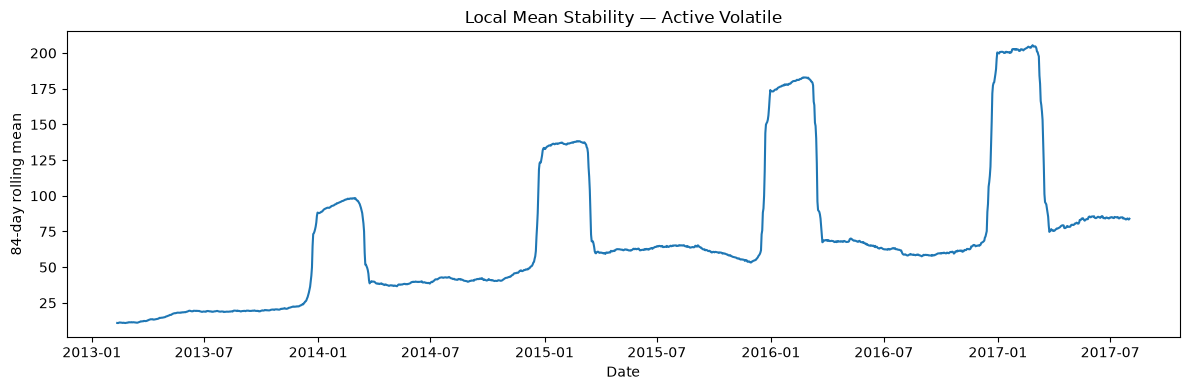

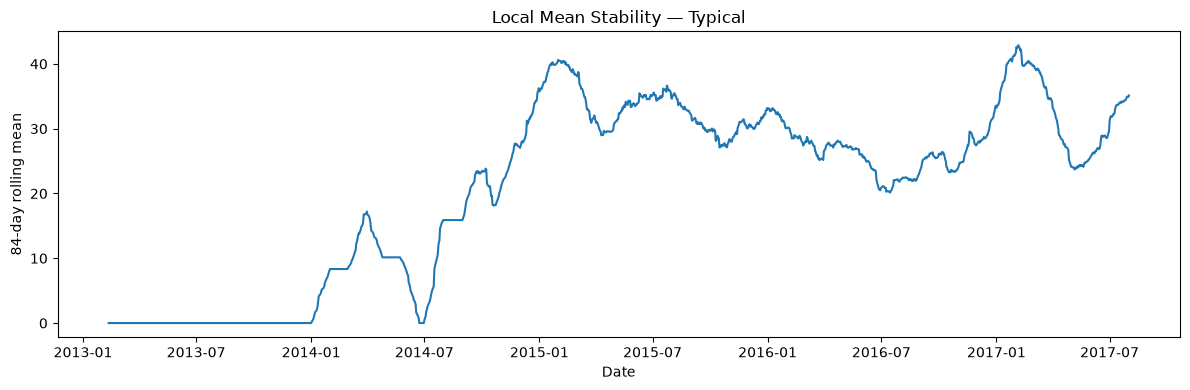

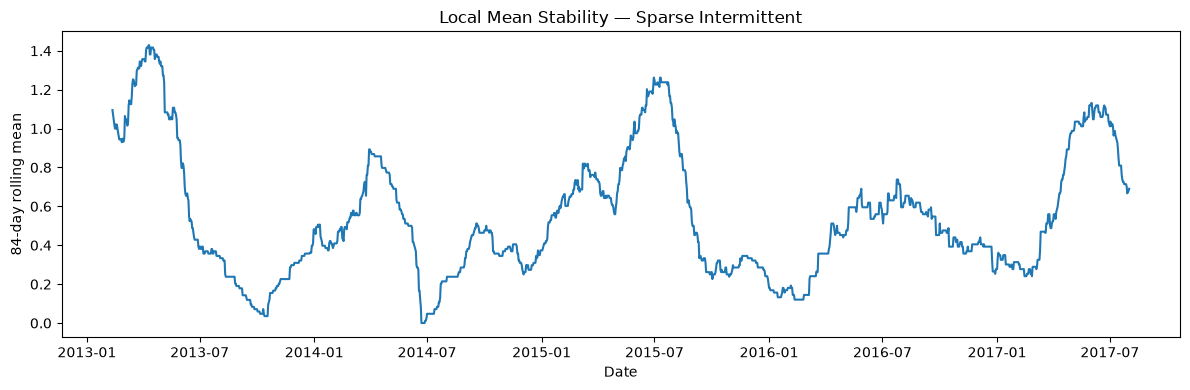

In [54]:
for archetype in selected_series["archetype"]:
    profile = stationarity_profiles.loc[
        stationarity_profiles["archetype"] == archetype
    ]

    plt.figure(figsize=(12, 4))

    plt.plot(
        profile["date"],
        profile["rolling_mean_84"],
    )

    plt.xlabel("Date")
    plt.ylabel("84-day rolling mean")
    plt.title(
        f"Local Mean Stability — "
        f"{archetype.replace('_', ' ').title()}"
    )
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_rolling_mean_84.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

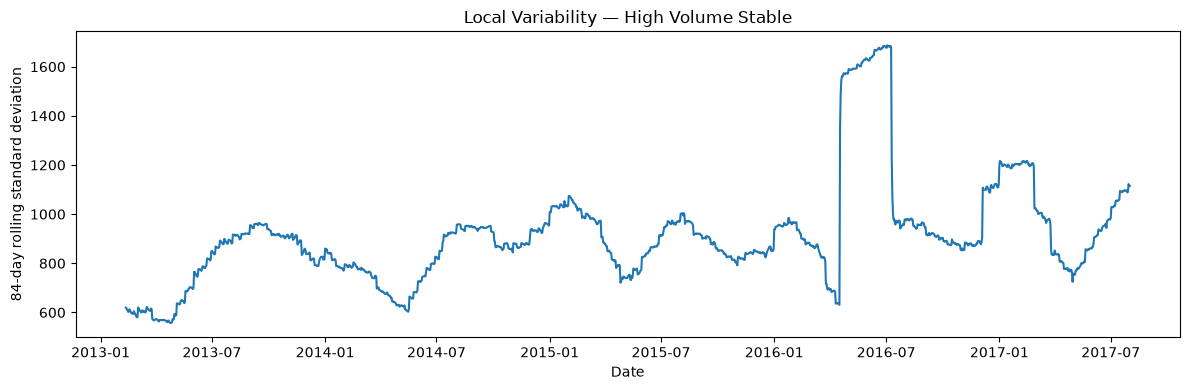

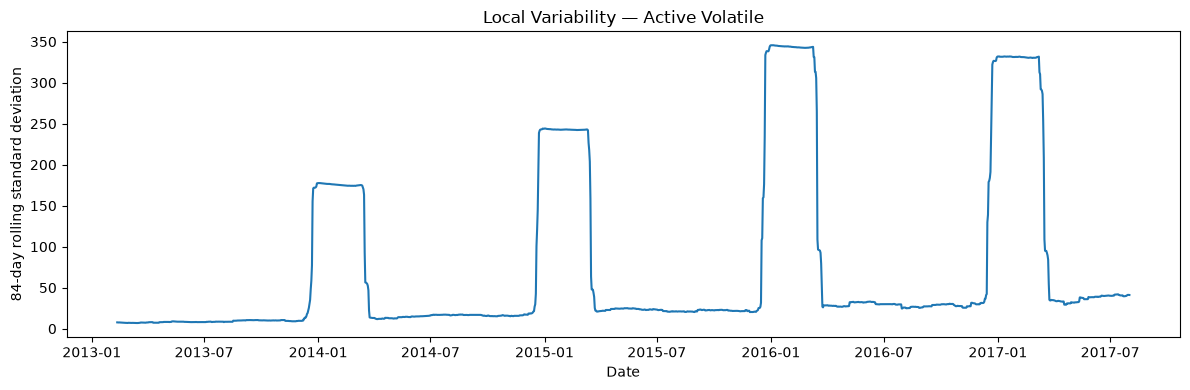

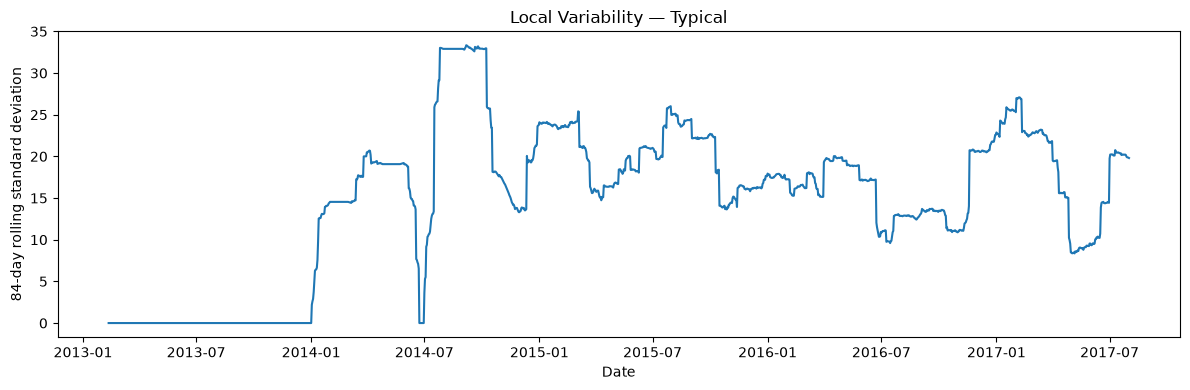

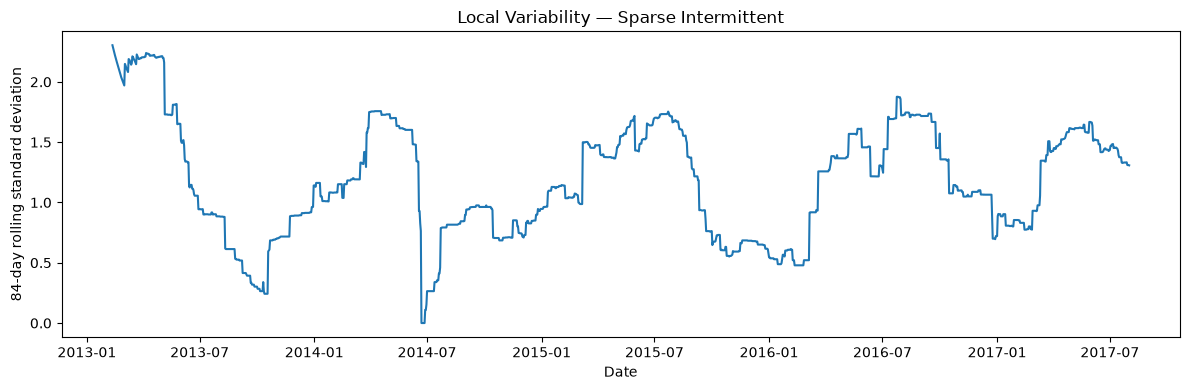

In [55]:
for archetype in selected_series["archetype"]:
    profile = stationarity_profiles.loc[
        stationarity_profiles["archetype"] == archetype
    ]

    plt.figure(figsize=(12, 4))

    plt.plot(
        profile["date"],
        profile["rolling_std_84"],
    )

    plt.xlabel("Date")
    plt.ylabel("84-day rolling standard deviation")
    plt.title(
        f"Local Variability — "
        f"{archetype.replace('_', ' ').title()}"
    )
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_rolling_std_84.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

### Rolling-Statistics Takeaway

The rolling diagnostics provide strong visual evidence that the raw
representative series do not maintain stable statistical properties throughout
the historical period.

- **High-volume stable demand** exhibits a pronounced long-term increase in
  its local mean together with substantial changes in local variability. The
  `stable` archetype therefore refers to low relative variability within the
  cross-sectional series population, not to time-series stationarity.
- **Active volatile demand** shows recurring episodes of exceptionally high
  local mean and variance. The 84-day rolling window prolongs the visual
  influence of individual extreme episodes, but the underlying distribution
  nevertheless changes materially across time.
- **Typical demand** displays an especially clear regime change, moving from
  an initially inactive period to sustained positive demand with varying local
  mean and dispersion.
- **Sparse intermittent demand** also exhibits changing local mean and
  variability, indicating that the frequency and/or magnitude of positive
  demand is not constant throughout the historical period.

These rolling statistics are descriptive rather than formal stationarity
tests. Their persistent changes nevertheless suggest that interpreting the raw
ACF and PACF as stationary AR/MA signatures would be premature.

The next step is to complement the visual diagnostics with formal
stationarity tests before deciding whether differencing is appropriate.

### 6.2 Formal Stationarity Tests

Visual rolling statistics suggest that the raw series have changing means
and/or variances, but visual diagnostics alone cannot establish the type of
non-stationarity involved.

Two complementary statistical tests are therefore used.

The **Augmented Dickey-Fuller (ADF) test** examines the null hypothesis that a
series contains a unit root, a common source of stochastic non-stationarity.

Its hypotheses are:

$$
H_0: \text{the series contains a unit root}
$$

$$
H_1: \text{the series does not contain a unit root}
$$

A small ADF p-value therefore provides evidence against unit-root
non-stationarity.

The **Kwiatkowski–Phillips–Schmidt–Shin (KPSS) test** approaches the question
from the opposite direction.

Its hypotheses are:

$$
H_0: \text{the series is stationary}
$$

$$
H_1: \text{the series is non-stationary}
$$

Using both tests reduces reliance on a single null hypothesis. Agreement
between ADF and KPSS provides stronger evidence, while conflicting results can
indicate more complex behavior such as deterministic trends, structural
breaks, or limited test power.

These tests address specific statistical forms of non-stationarity and should
therefore be interpreted together with the previously observed rolling
diagnostics rather than as automatic yes/no classifiers.

#### 6.2.1 Missing-Value Handling for Stationarity Tests

ADF and KPSS require complete regularly spaced observations, while the
Favorita development history contains four isolated missing Christmas dates.

Removing these observations would break the daily time grid, while replacing
them with zero would incorrectly treat unobserved demand as observed zero
demand.

For the formal stationarity tests, each missing observation is therefore
replaced by the average of the same weekday over the four preceding weeks:

$$
\tilde{Y}_t =
\frac{
Y_{t-7} + Y_{t-14} + Y_{t-21} + Y_{t-28}
}{4}
$$

This preserves the daily calendar while using only historical observations.

The imputation is diagnostic only. It is not used for forecasting, feature
engineering, model training, or model evaluation.

In [56]:
# Build a complete diagnostic version of each series using only historical
# same-weekday observations for the four missing calendar dates.
stationarity_test_series = {}

for archetype in selected_series["archetype"]:
    series = (
        final_regularized_series.loc[
            final_regularized_series["archetype"] == archetype
        ]
        .sort_values("date")
        .set_index("date")["sales"]
        .astype(float)
    )

    past_seasonal_imputed = series.copy()

    missing_dates = past_seasonal_imputed.index[
        past_seasonal_imputed.isna()
    ]

    for missing_date in missing_dates:
        historical_values = [
            past_seasonal_imputed.loc[
                missing_date - pd.Timedelta(days=7 * lag)
            ]
            for lag in range(1, 5)
        ]

        past_seasonal_imputed.loc[missing_date] = np.mean(
            historical_values
        )

    stationarity_test_series[
        archetype
    ] = past_seasonal_imputed

# Verify that every diagnostic series is now complete.
for archetype, series in stationarity_test_series.items():
    assert series.isna().sum() == 0, (
        f"Missing values remain for {archetype}"
    )

print(
    "Complete diagnostic series:",
    len(stationarity_test_series),
)

Complete diagnostic series: 4


In [57]:
# Audit the values inserted at the originally missing calendar dates.
imputation_records = []

for archetype in selected_series["archetype"]:
    original_series = (
        final_regularized_series.loc[
            final_regularized_series["archetype"] == archetype
        ]
        .sort_values("date")
        .set_index("date")["sales"]
        .astype(float)
    )

    missing_dates = original_series.index[
        original_series.isna()
    ]

    for missing_date in missing_dates:
        imputation_records.append(
            {
                "archetype": archetype,
                "date": missing_date,
                "imputed_sales": (
                    stationarity_test_series[archetype]
                    .loc[missing_date]
                ),
            }
        )

imputation_audit = pd.DataFrame(
    imputation_records
)

display(imputation_audit)

,archetype,date,imputed_sales
0,high_volume_stable,2013-12-25,2132.25000
1,high_volume_stable,2014-12-25,2558.50000
2,high_volume_stable,2015-12-25,2917.75000
3,high_volume_stable,2016-12-25,5927.75000
4,active_volatile,2013-12-25,83.19025
5,active_volatile,2014-12-25,127.12250
6,active_volatile,2015-12-25,130.51800
7,active_volatile,2016-12-25,161.82675
8,typical,2013-12-25,0.00000
9,typical,2014-12-25,44.25000


In [58]:
from statsmodels.tsa.stattools import adfuller, kpss

# Run ADF and KPSS under both level and deterministic-trend specifications.
stationarity_test_records = []

for archetype, series in stationarity_test_series.items():

    adf_level = adfuller(
        series,
        regression="c",
        autolag="AIC",
        result_object=False,
    )

    adf_trend = adfuller(
        series,
        regression="ct",
        autolag="AIC",
        result_object=False,
    )

    kpss_level = kpss(
        series,
        regression="c",
        nlags="auto",
        result_object=False,
    )

    kpss_trend = kpss(
        series,
        regression="ct",
        nlags="auto",
        result_object=False,
    )

    stationarity_test_records.append(
        {
            "archetype": archetype,
            "adf_level_stat": adf_level[0],
            "adf_level_pvalue": adf_level[1],
            "adf_trend_stat": adf_trend[0],
            "adf_trend_pvalue": adf_trend[1],
            "kpss_level_stat": kpss_level[0],
            "kpss_level_pvalue": kpss_level[1],
            "kpss_trend_stat": kpss_trend[0],
            "kpss_trend_pvalue": kpss_trend[1],
        }
    )

stationarity_tests = pd.DataFrame(
    stationarity_test_records
)

display(stationarity_tests)

/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/417813322.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_level = kpss(
/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/417813322.py:29: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_trend = kpss(
/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/417813322.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_level = kpss(
/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/417813322.py:29: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. Th

,archetype,adf_level_stat,adf_level_pvalue,adf_trend_stat,adf_trend_pvalue,kpss_level_stat,kpss_level_pvalue,kpss_trend_stat,kpss_trend_pvalue
0,high_volume_stable,-2.356040,1.545299e-01,-5.994174,2.259658e-06,7.835754,0.01,0.068989,0.100000
1,active_volatile,-9.059432,4.605868e-15,-9.412464,4.334075e-14,0.859227,0.01,0.041452,0.100000
2,typical,-4.200929,6.565182e-04,-6.496843,1.875040e-07,3.715599,0.01,0.677955,0.010000
3,sparse_intermittent,-5.667694,9.071718e-07,-5.664816,1.079187e-05,0.161244,0.10,0.161174,0.037355


### Formal Stationarity Tests — Takeaway

The formal tests confirm that the representative series exhibit different
forms of temporal non-stationarity.

- **High-volume stable demand** is not stationary around a constant level, but
  the combination of ADF and KPSS results is compatible with stationarity
  around a deterministic trend.
- **Active volatile demand** strongly rejects a unit root but also rejects
  level stationarity. Trend-adjusted tests are more favorable, although the
  large recurring changes in local mean and variance indicate that a simple
  deterministic trend does not capture the full temporal structure.
- **Typical demand** rejects a unit root while also rejecting both level and
  trend stationarity. This is consistent with the structural regime changes
  observed visually and illustrates that non-stationarity need not arise from
  a unit root.
- **Sparse intermittent demand** rejects a unit root and does not reject level
  stationarity, making it the strongest candidate for approximate
  level-stationarity among the four representative series.

The results therefore suggest that differencing should not be applied
mechanically to every series. Different transformations may be appropriate for
different forms of temporal structure.

### 6.3 Differencing

The previous diagnostics show that several representative series have unstable
levels and recurring seasonal structure.

Differencing is used to remove specific forms of temporal non-stationarity
before fitting classical time-series models.

A first difference replaces the absolute level of the series with its
day-to-day change:

$$
\Delta Y_t = Y_t - Y_{t-1}
$$

For example, a random walk satisfies:

$$
Y_t = Y_{t-1} + \varepsilon_t
$$

and therefore:

$$
\Delta Y_t = \varepsilon_t
$$

The non-stationary accumulated level has disappeared, leaving only the
innovation process.

For a daily series with weekly seasonality, a seasonal difference compares an
observation with the same weekday one week earlier:

$$
\Delta_7 Y_t = Y_t - Y_{t-7}
$$

If a seasonal component repeats every seven days, this transformation can
remove much of that recurring structure.

The two transformations can also be combined:

$$
\Delta \Delta_7 Y_t
=
(Y_t-Y_{t-7}) - (Y_{t-1}-Y_{t-8})
$$

The objective is therefore not simply to express demand as changes rather than
levels. It is to remove persistent level and seasonal structures that can
prevent a process from being stationary and distort the interpretation of
classical AR/MA dynamics.

Differencing is not automatically beneficial. Unnecessary differencing can
remove useful predictive structure and amplify noise.

The representative series will therefore be compared under four forms:

- raw levels;
- first difference;
- weekly seasonal difference;
- combined first and weekly seasonal difference.

Variance-stabilizing transformations such as `log1p` will be considered
separately when the diagnostics suggest that variability systematically grows
with the level of the series.

In [59]:
# Construct alternative differenced versions of each complete diagnostic series.
differenced_series = {}

for archetype, series in stationarity_test_series.items():

    differenced_series[
        (archetype, "raw")
    ] = series.copy()

    differenced_series[
        (archetype, "first_difference")
    ] = series.diff(1)

    differenced_series[
        (archetype, "seasonal_difference_7")
    ] = series.diff(7)

    differenced_series[
        (archetype, "first_and_seasonal_difference")
    ] = (
        series
        .diff(7)
        .diff(1)
    )

In [60]:
# Summarize the observations retained after each transformation.
transformation_records = []

for (archetype, transformation), series in differenced_series.items():
    transformation_records.append(
        {
            "archetype": archetype,
            "transformation": transformation,
            "total_rows": len(series),
            "valid_rows": series.notna().sum(),
            "missing_rows": series.isna().sum(),
        }
    )

transformation_summary = pd.DataFrame(
    transformation_records
)

display(
    transformation_summary
    .sort_values(["archetype", "transformation"])
    .style.hide(axis="index")
)

archetype,transformation,total_rows,valid_rows,missing_rows
active_volatile,first_and_seasonal_difference,1674,1666,8
active_volatile,first_difference,1674,1673,1
active_volatile,raw,1674,1674,0
active_volatile,seasonal_difference_7,1674,1667,7
high_volume_stable,first_and_seasonal_difference,1674,1666,8
high_volume_stable,first_difference,1674,1673,1
high_volume_stable,raw,1674,1674,0
high_volume_stable,seasonal_difference_7,1674,1667,7
sparse_intermittent,first_and_seasonal_difference,1674,1666,8
sparse_intermittent,first_difference,1674,1673,1


In [61]:
# Compare the basic distributional properties of each transformed series.
transformation_profile_records = []

for (archetype, transformation), series in differenced_series.items():
    valid_series = series.dropna()

    transformation_profile_records.append(
        {
            "archetype": archetype,
            "transformation": transformation,
            "mean": valid_series.mean(),
            "std": valid_series.std(),
            "min": valid_series.min(),
            "max": valid_series.max(),
        }
    )

transformation_profiles = pd.DataFrame(
    transformation_profile_records
)

display(
    transformation_profiles
    .sort_values(["archetype", "transformation"])
    .style.hide(axis="index")
)

archetype,transformation,mean,std,min,max
active_volatile,first_and_seasonal_difference,0.016464,140.547367,-2534.715960,1625.453960
active_volatile,first_difference,0.061645,102.295857,-1746.576960,1024.260000
active_volatile,raw,70.677214,135.655811,0.000000,2297.539000
active_volatile,seasonal_difference_7,0.368902,149.759250,-1684.829000,2078.738000
high_volume_stable,first_and_seasonal_difference,-0.624250,1006.049890,-12067.000000,11393.000000
high_volume_stable,first_difference,2.745965,1127.280908,-5888.000000,11790.000000
high_volume_stable,raw,3176.837067,1107.710049,0.000000,14396.000000
high_volume_stable,seasonal_difference_7,10.703059,816.410870,-9682.000000,10154.000000
sparse_intermittent,first_and_seasonal_difference,0.000600,2.345272,-14.000000,12.000000
sparse_intermittent,first_difference,0.000598,1.690283,-13.000000,11.000000


#### 6.3.1 Stationarity After Differencing

Each transformed series is now tested for stationarity around a constant level.

Unlike the raw-series analysis, the primary objective here is not to distinguish
level stationarity from trend stationarity. Differencing is specifically being
evaluated as a transformation intended to remove persistent level and seasonal
structure.

For each transformation:

- ADF tests the null hypothesis of a unit root;
- KPSS tests the null hypothesis of level stationarity.

A useful transformation should ideally produce the combination:

- ADF rejects the unit-root null;
- KPSS does not reject level stationarity.

The tests are interpreted together with the previously observed temporal
structure rather than used as automatic transformation-selection rules.

In [62]:
# Evaluate level stationarity after each transformation.
differencing_test_records = []

for (archetype, transformation), series in differenced_series.items():
    valid_series = series.dropna()

    adf_result = adfuller(
        valid_series,
        regression="c",
        autolag="AIC",
        result_object=False,
    )

    kpss_result = kpss(
        valid_series,
        regression="c",
        nlags="auto",
        result_object=False,
    )

    differencing_test_records.append(
        {
            "archetype": archetype,
            "transformation": transformation,
            "adf_stat": adf_result[0],
            "adf_pvalue": adf_result[1],
            "kpss_stat": kpss_result[0],
            "kpss_pvalue": kpss_result[1],
        }
    )


differencing_tests = pd.DataFrame(
    differencing_test_records
)

display(
    differencing_tests
    .sort_values(["archetype", "transformation"])
    .style.hide(axis="index")
)

/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/661541559.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/661541559.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/661541559.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/var/folders/9b/jy4h3b490nx9py6bch99p2tm0000gr/T/ipykernel_96089/661541559.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table.

archetype,transformation,adf_stat,adf_pvalue,kpss_stat,kpss_pvalue
active_volatile,first_and_seasonal_difference,-15.587094,0.000000,0.044662,0.100000
active_volatile,first_difference,-12.054260,0.000000,0.025470,0.100000
active_volatile,raw,-9.059432,0.000000,0.859227,0.010000
active_volatile,seasonal_difference_7,-10.704534,0.000000,0.005791,0.100000
high_volume_stable,first_and_seasonal_difference,-15.968085,0.000000,0.029480,0.100000
high_volume_stable,first_difference,-13.587025,0.000000,0.045539,0.100000
high_volume_stable,raw,-2.356040,0.154530,7.835754,0.010000
high_volume_stable,seasonal_difference_7,-11.908961,0.000000,0.006899,0.100000
sparse_intermittent,first_and_seasonal_difference,-15.615711,0.000000,0.078967,0.100000
sparse_intermittent,first_difference,-14.446696,0.000000,0.029392,0.100000


In [63]:
# Summarize the statistical evidence without treating test outcomes as an
# automatic transformation-selection rule.
SIGNIFICANCE_LEVEL = 0.05

differencing_test_summary = differencing_tests.copy()

differencing_test_summary["adf_rejects_unit_root"] = (
    differencing_test_summary["adf_pvalue"]
    < SIGNIFICANCE_LEVEL
)

differencing_test_summary["kpss_rejects_stationarity"] = (
    differencing_test_summary["kpss_pvalue"]
    < SIGNIFICANCE_LEVEL
)

differencing_test_summary["tests_support_level_stationarity"] = (
    differencing_test_summary["adf_rejects_unit_root"]
    & ~differencing_test_summary["kpss_rejects_stationarity"]
)

display(
    differencing_test_summary[
        [
            "archetype",
            "transformation",
            "adf_pvalue",
            "kpss_pvalue",
            "tests_support_level_stationarity",
        ]
    ]
    .sort_values(["archetype", "transformation"])
    .style.hide(axis="index")
)

archetype,transformation,adf_pvalue,kpss_pvalue,tests_support_level_stationarity
active_volatile,first_and_seasonal_difference,0.000000,0.100000,True
active_volatile,first_difference,0.000000,0.100000,True
active_volatile,raw,0.000000,0.010000,False
active_volatile,seasonal_difference_7,0.000000,0.100000,True
high_volume_stable,first_and_seasonal_difference,0.000000,0.100000,True
high_volume_stable,first_difference,0.000000,0.100000,True
high_volume_stable,raw,0.154530,0.010000,False
high_volume_stable,seasonal_difference_7,0.000000,0.100000,True
sparse_intermittent,first_and_seasonal_difference,0.000000,0.100000,True
sparse_intermittent,first_difference,0.000000,0.100000,True


#### Differencing Stationarity Tests — Takeaway

The stationarity tests show that different representative series require
different treatment.

- **High-volume stable demand** is non-stationary in raw levels, while both
  first and weekly seasonal differencing produce series compatible with level
  stationarity.
- **Active volatile demand** rejects a unit root even in raw form but fails the
  KPSS level-stationarity test. Both first and weekly seasonal differencing
  are sufficient to produce test results compatible with level stationarity.
- **Typical demand** similarly has no evidence of a unit root in raw levels,
  yet fails level stationarity because of its changing temporal regime.
  Either first or weekly seasonal differencing is sufficient according to the
  formal tests.
- **Sparse intermittent demand** already satisfies the combined ADF/KPSS
  criterion in raw levels and therefore does not require differencing for
  stationarity.

The combined first-and-seasonal transformation also produces stationary test
results for the non-stationary series, but it is not required because a single
difference is already sufficient.

To avoid over-differencing, the next step compares the temporal dependence
remaining after the simpler candidate transformations rather than selecting
the most aggressive transformation.

#### 6.3.2 Visualizing the Differenced Series

The formal tests indicate that several differenced series are compatible with
level stationarity. The transformations are now inspected visually to
understand what this statistical result means in practice.

For each representative series, two transformations are compared:

- **first difference**, which measures day-to-day changes;
- **weekly seasonal difference**, which measures changes relative to the same
  weekday one week earlier.

A stationary transformed series should no longer exhibit a persistent drifting
level. Its observations may remain noisy or autocorrelated, but they should
fluctuate around a comparatively stable local mean.

An 84-day trailing mean is therefore added to each transformed series as a
visual diagnostic of remaining level drift.

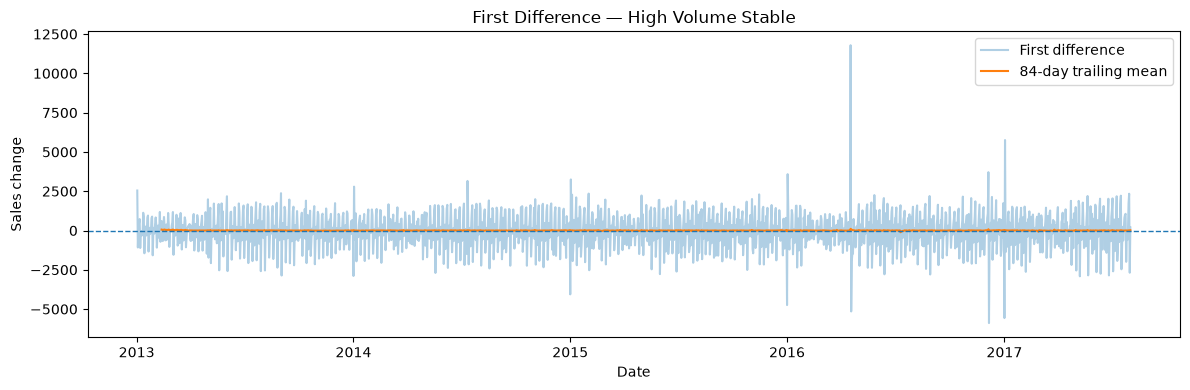

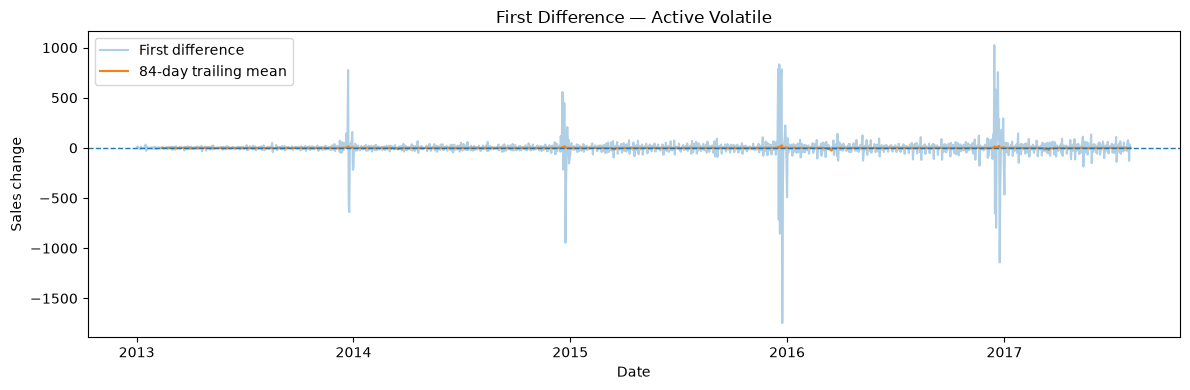

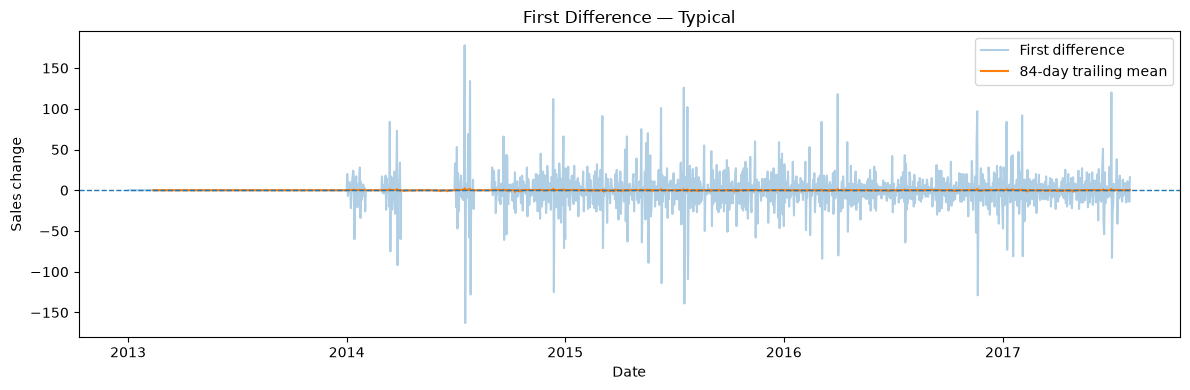

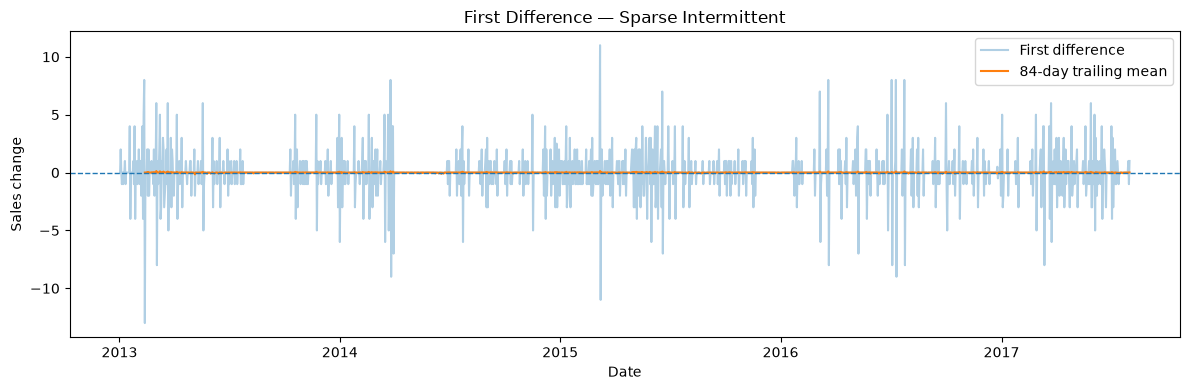

In [64]:
# Visualize day-to-day changes and their medium-term local mean.
for archetype in selected_series["archetype"]:
    series = differenced_series[
        (archetype, "first_difference")
    ].copy()

    rolling_mean = series.rolling(
        window=STATIONARITY_WINDOW,
        min_periods=STATIONARITY_WINDOW // 2,
    ).mean()

    plt.figure(figsize=(12, 4))

    plt.plot(
        series.index,
        series,
        alpha=0.35,
        label="First difference",
    )

    plt.plot(
        rolling_mean.index,
        rolling_mean,
        label="84-day trailing mean",
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.xlabel("Date")
    plt.ylabel("Sales change")
    plt.title(
        f"First Difference — "
        f"{archetype.replace('_', ' ').title()}"
    )
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_first_difference.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

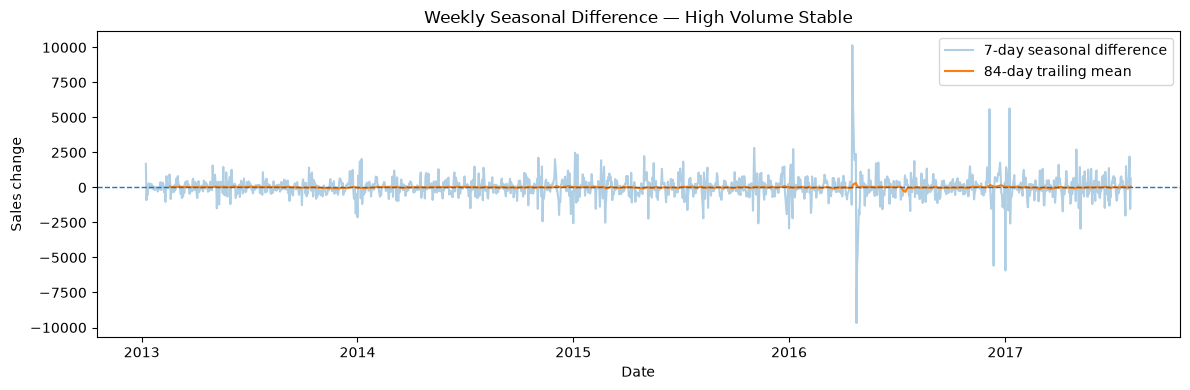

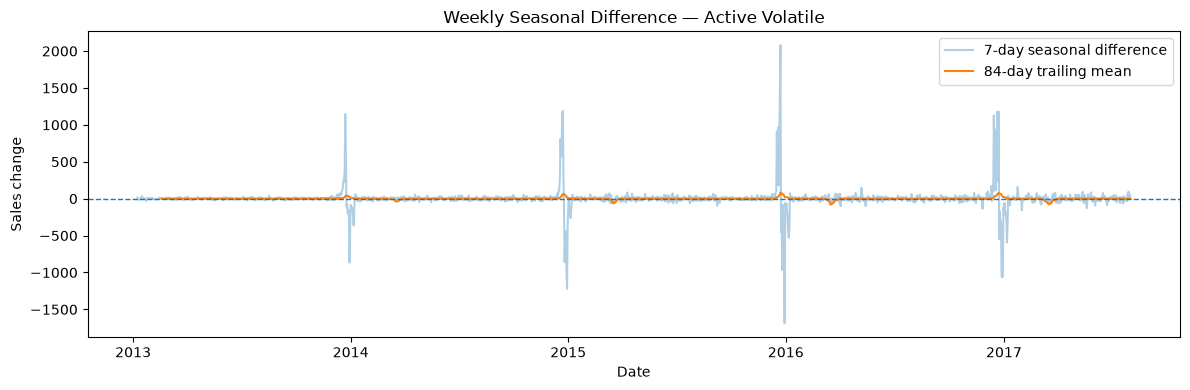

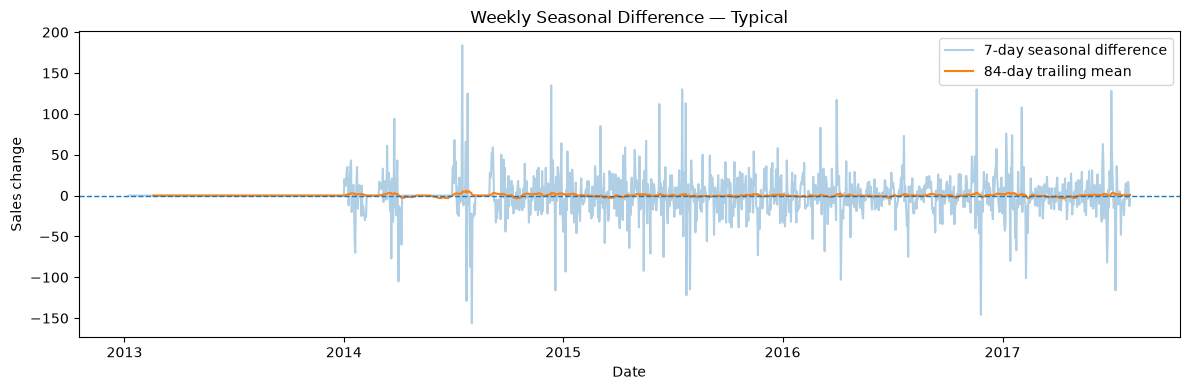

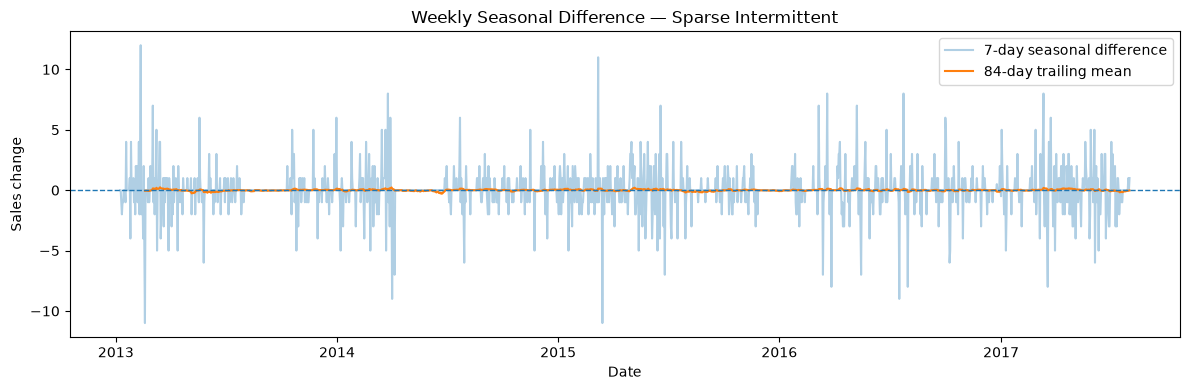

In [65]:
# Visualize changes relative to the same weekday one week earlier.
for archetype in selected_series["archetype"]:
    series = differenced_series[
        (archetype, "seasonal_difference_7")
    ].copy()

    rolling_mean = series.rolling(
        window=STATIONARITY_WINDOW,
        min_periods=STATIONARITY_WINDOW // 2,
    ).mean()

    plt.figure(figsize=(12, 4))

    plt.plot(
        series.index,
        series,
        alpha=0.35,
        label="7-day seasonal difference",
    )

    plt.plot(
        rolling_mean.index,
        rolling_mean,
        label="84-day trailing mean",
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.xlabel("Date")
    plt.ylabel("Sales change")
    plt.title(
        f"Weekly Seasonal Difference — "
        f"{archetype.replace('_', ' ').title()}"
    )
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_seasonal_difference_7.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

#### Differenced-Series Visual Diagnostics — Takeaway

The differenced-series plots provide a visual interpretation of the formal
stationarity results.

For the high-volume, active-volatile, and typical representatives, both first
and weekly seasonal differencing largely remove the persistent movement in the
local mean. Their 84-day trailing means fluctuate close to zero rather than
following the changing demand levels observed in the raw series.

However, differencing does not necessarily stabilize variance. In particular,
the active-volatile and typical representatives continue to exhibit
substantial changes in the magnitude of their fluctuations across time.

The sparse intermittent representative illustrates the risk of unnecessary
differencing: its raw series already satisfies the combined ADF/KPSS
level-stationarity criterion, while differencing introduces alternating
positive and negative changes without addressing a clear level-stationarity
problem.

These diagnostics support using the minimum amount of differencing necessary
and treating mean stabilization and variance stabilization as separate
modeling questions.

### 6.4 Selecting the Differencing Structure

Formal stationarity tests show that both first and weekly seasonal
differencing are sufficient for the three non-stationary representative
series.

Stationarity alone does not determine which transformation is preferable.
Different transformations can remove different types of temporal structure
and leave different residual dependence patterns.

The candidate transformations are therefore compared through their ACF and
PACF:

- **first difference** targets persistence in the local level;
- **weekly seasonal difference** targets recurring seven-day structure.

The preferred transformation should achieve stationarity without removing
more information than necessary and should leave a parsimonious temporal
dependence structure that can be modeled using AR/MA components.

The sparse intermittent representative is already compatible with level
stationarity and is therefore retained in raw form.

In [66]:
# Retain only the minimal stationary candidate transformations that require
# further comparison.
candidate_transformations = {
    "high_volume_stable": [
        "first_difference",
        "seasonal_difference_7",
    ],
    "active_volatile": [
        "first_difference",
        "seasonal_difference_7",
    ],
    "typical": [
        "first_difference",
        "seasonal_difference_7",
    ],
    "sparse_intermittent": [
        "raw",
    ],
}

In [67]:
# Compare remaining autocorrelation at interpretable daily and weekly lags.
TRANSFORMED_LAGS = [1, 2, 7, 14, 21, 28]

transformed_lag_records = []

for archetype, transformations in candidate_transformations.items():

    for transformation in transformations:
        series = differenced_series[
            (archetype, transformation)
        ].dropna()

        for lag in TRANSFORMED_LAGS:
            transformed_lag_records.append(
                {
                    "archetype": archetype,
                    "transformation": transformation,
                    "lag": lag,
                    "correlation": series.corr(
                        series.shift(lag)
                    ),
                }
            )


transformed_lag_correlations = pd.DataFrame(
    transformed_lag_records
)

display(
    transformed_lag_correlations.pivot_table(
        index=[
            "archetype",
            "transformation",
        ],
        columns="lag",
        values="correlation",
    )
)

lag                                              1         2         7   \
archetype           transformation                                        
active_volatile     first_difference      -0.203841 -0.020846  0.059335   
                    seasonal_difference_7  0.559872  0.435983 -0.269408   
high_volume_stable  first_difference      -0.168478 -0.308073  0.600994   
                    seasonal_difference_7  0.240090  0.105284 -0.526839   
sparse_intermittent raw                    0.136812  0.036604  0.136453   
typical             first_difference      -0.456829 -0.031280 -0.027575   
                    seasonal_difference_7  0.114170  0.039407 -0.473233   

lag                                              14        21        28  
archetype           transformation                                       
active_volatile     first_difference       0.091473  0.052088  0.056402  
                    seasonal_difference_7 -0.169592 -0.051547 -0.008977  
high_volume_stable  first_difference       0.606105  0.591124  0.626379  
                    seasonal_difference_7  0.068618 -0.075908  0.080387  
sparse_intermittent raw                    0.124781  0.127387  0.064873  
typical             first_difference       0.057407  0.002314  0.010315  
                    seasonal_difference_7  0.025479 -0.019461 -0.020489

### 6.5 ACF and PACF After Stationarity Treatment

A candidate stationary representation has now been selected for each
representative series:

- **high-volume stable:** weekly seasonal difference;
- **active volatile:** first difference;
- **typical:** first difference;
- **sparse intermittent:** raw levels.

The ACF and PACF are now re-estimated on these representations.

Unlike the earlier raw-series diagnostics, these plots can be interpreted more
directly in terms of AR and MA structure because persistent level and seasonal
non-stationarity have been reduced.

Approximate 95% confidence intervals are included. Spikes extending beyond
these intervals indicate autocorrelations that are statistically distinguishable
from zero under the standard large-sample approximation.

These plots will be used to identify plausible non-seasonal AR/MA orders
$(p, q)$ and, where relevant, seasonal AR/MA orders $(P, Q)$.

#### Calendar-Safe Candidate Representations

The missing-value imputations introduced for ADF/KPSS were diagnostic-only and
must not propagate into the modeling series.

The final candidate representations are therefore rebuilt directly from the
original development daily calendar, preserving the four missing Christmas observations.

Differencing is applied before any missing observations are removed, ensuring
that every lag and difference retains its correct calendar interpretation.

ACF estimation will use missing-aware calculations, while PACF will use the
calendar-aligned OLS estimator introduced earlier.

In [68]:
# Rebuild the candidate representations directly from the original development
# daily calendar so that diagnostic imputations do not propagate into modeling.
original_regularized_series = {}

for archetype in selected_series["archetype"]:
    original_regularized_series[archetype] = (
        final_regularized_series.loc[
            final_regularized_series["archetype"] == archetype
        ]
        .sort_values("date")
        .set_index("date")["sales"]
        .astype(float)
        .asfreq("D")
    )


modeling_candidate_series = {
    "high_volume_stable": (
        original_regularized_series["high_volume_stable"]
        .diff(7)
    ),

    "active_volatile": (
        original_regularized_series["active_volatile"]
        .diff(1)
    ),

    "typical": (
        original_regularized_series["typical"]
        .diff(1)
    ),

    "sparse_intermittent": (
        original_regularized_series["sparse_intermittent"]
        .copy()
    ),
}

In [69]:
candidate_missing_summary = pd.DataFrame(
    [
        {
            "archetype": archetype,
            "rows": len(series),
            "missing_values": series.isna().sum(),
        }
        for archetype, series in modeling_candidate_series.items()
    ]
)

display(candidate_missing_summary)

,archetype,rows,missing_values
0,high_volume_stable,1674,15
1,active_volatile,1674,9
2,typical,1674,9
3,sparse_intermittent,1674,4


In [70]:
for archetype, series in modeling_candidate_series.items():
    print(f"\n{archetype}")
    print(series[series.isna()].index.tolist())


high_volume_stable
[Timestamp('2013-01-01 00:00:00'), Timestamp('2013-01-02 00:00:00'), Timestamp('2013-01-03 00:00:00'), Timestamp('2013-01-04 00:00:00'), Timestamp('2013-01-05 00:00:00'), Timestamp('2013-01-06 00:00:00'), Timestamp('2013-01-07 00:00:00'), Timestamp('2013-12-25 00:00:00'), Timestamp('2014-01-01 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-01-01 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-01-01 00:00:00'), Timestamp('2016-12-25 00:00:00'), Timestamp('2017-01-01 00:00:00')]

active_volatile
[Timestamp('2013-01-01 00:00:00'), Timestamp('2013-12-25 00:00:00'), Timestamp('2013-12-26 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2014-12-26 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2015-12-26 00:00:00'), Timestamp('2016-12-25 00:00:00'), Timestamp('2016-12-26 00:00:00')]

typical
[Timestamp('2013-01-01 00:00:00'), Timestamp('2013-12-25 00:00:00'), Timestamp('2013-12-26 00:00:00'), Timestamp('2014-12-25 00:00:00'),

In [71]:
def calendar_safe_pacf(series, max_lag):
    """
    Estimate PACF through calendar-aligned OLS regressions.

    Lag columns are created before incomplete rows are removed, ensuring that
    each lag always represents the correct number of calendar days.
    """
    data = pd.DataFrame(
        {
            "sales": series.astype(float),
        }
    )

    for lag in range(1, max_lag + 1):
        data[f"lag_{lag}"] = data["sales"].shift(lag)

    pacf_values = [1.0]
    valid_counts = [data["sales"].notna().sum()]

    for lag in range(1, max_lag + 1):
        required_columns = [
            "sales",
            *[f"lag_{k}" for k in range(1, lag + 1)],
        ]

        regression_data = data[
            required_columns
        ].dropna()

        y = regression_data["sales"]

        X = regression_data[
            [f"lag_{k}" for k in range(1, lag + 1)]
        ]

        X = sm.add_constant(X)

        model = sm.OLS(
            y,
            X,
        ).fit()

        pacf_values.append(
            model.params[f"lag_{lag}"]
        )

        valid_counts.append(
            len(regression_data)
        )

    return (
        np.array(pacf_values),
        np.array(valid_counts),
    )

In [72]:
MAX_LAG = 35

candidate_acf_records = []

for archetype, series in modeling_candidate_series.items():

    acf_values = acf(
        series,
        nlags=MAX_LAG,
        missing="conservative",
        fft=False,
    )

    for lag, value in enumerate(acf_values):
        candidate_acf_records.append(
            {
                "archetype": archetype,
                "lag": lag,
                "acf": value,
            }
        )


candidate_acf = pd.DataFrame(
    candidate_acf_records
)

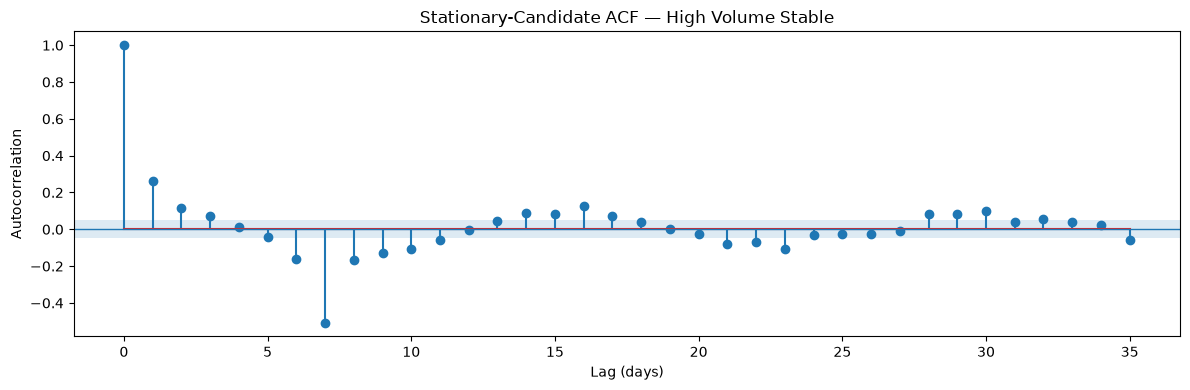

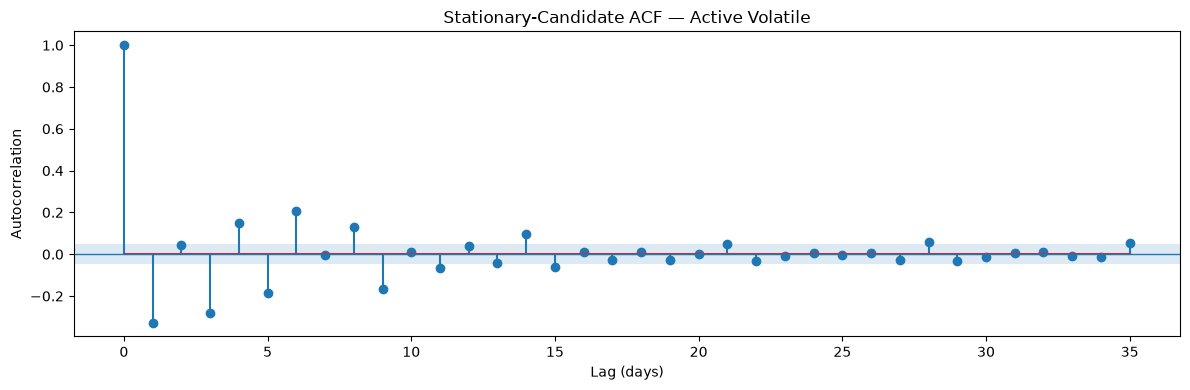

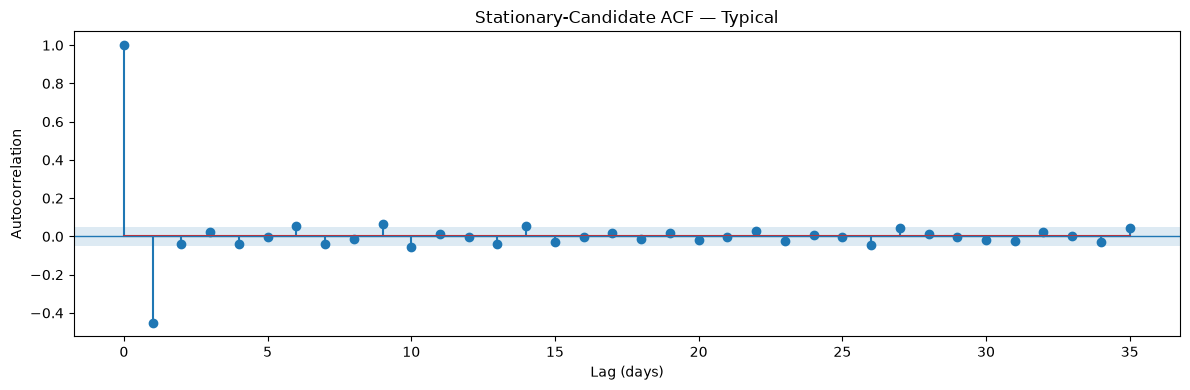

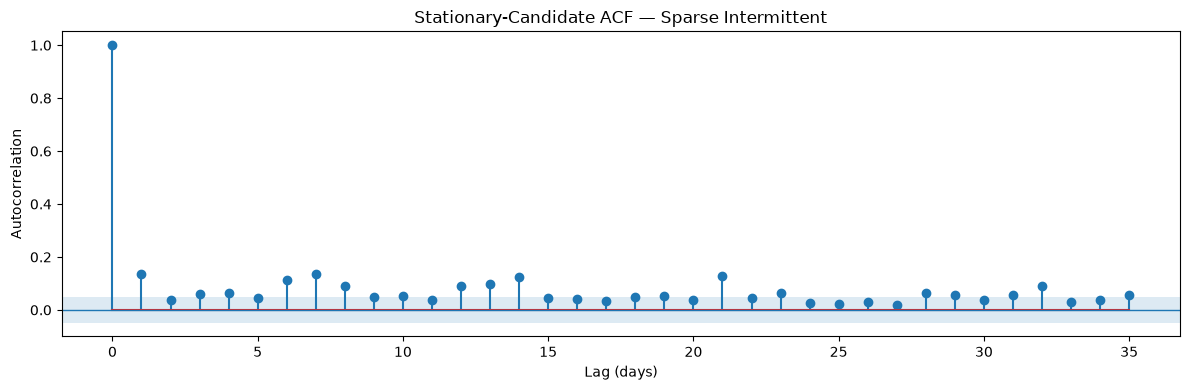

In [73]:
for archetype, series in modeling_candidate_series.items():

    profile = candidate_acf.loc[
        candidate_acf["archetype"] == archetype
    ]

    n_observed = series.notna().sum()
    confidence_bound = 1.96 / np.sqrt(n_observed)

    plt.figure(figsize=(12, 4))

    plt.stem(
        profile["lag"],
        profile["acf"],
    )

    plt.axhline(0, linewidth=1)

    plt.axhspan(
        -confidence_bound,
        confidence_bound,
        alpha=0.15,
    )

    plt.xlabel("Lag (days)")
    plt.ylabel("Autocorrelation")
    plt.title(
        f"Stationary-Candidate ACF — "
        f"{archetype.replace('_', ' ').title()}"
    )

    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_candidate_acf.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

In [74]:
candidate_pacf_records = []

for archetype, series in modeling_candidate_series.items():

    pacf_values, valid_counts = calendar_safe_pacf(
        series,
        max_lag=MAX_LAG,
    )

    for lag, (value, n_valid) in enumerate(
        zip(pacf_values, valid_counts)
    ):
        candidate_pacf_records.append(
            {
                "archetype": archetype,
                "lag": lag,
                "pacf": value,
                "valid_observations": n_valid,
            }
        )


candidate_pacf = pd.DataFrame(
    candidate_pacf_records
)

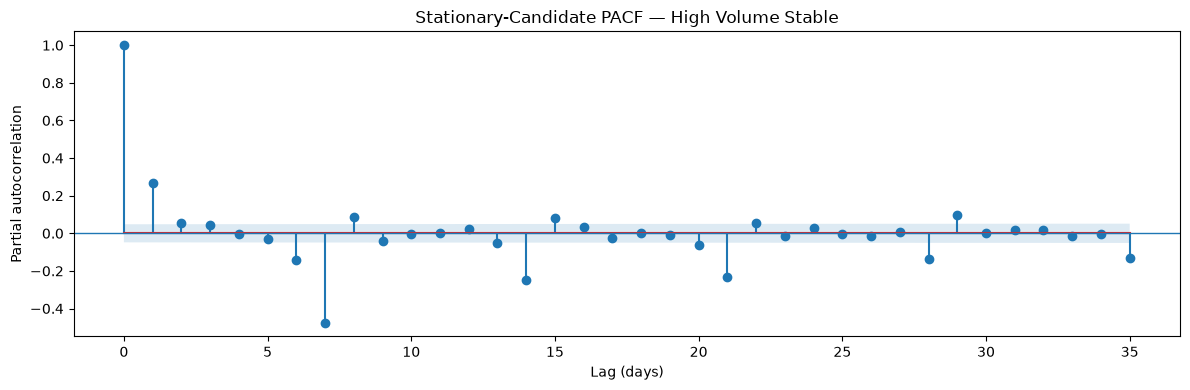

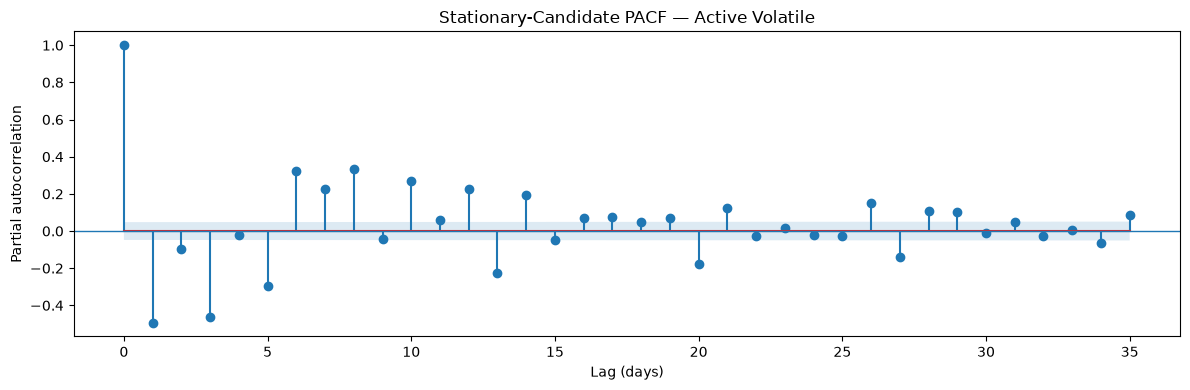

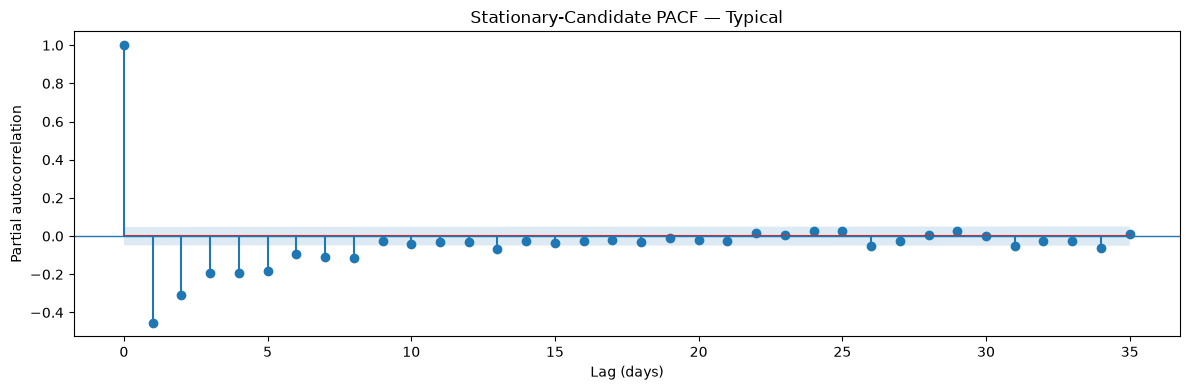

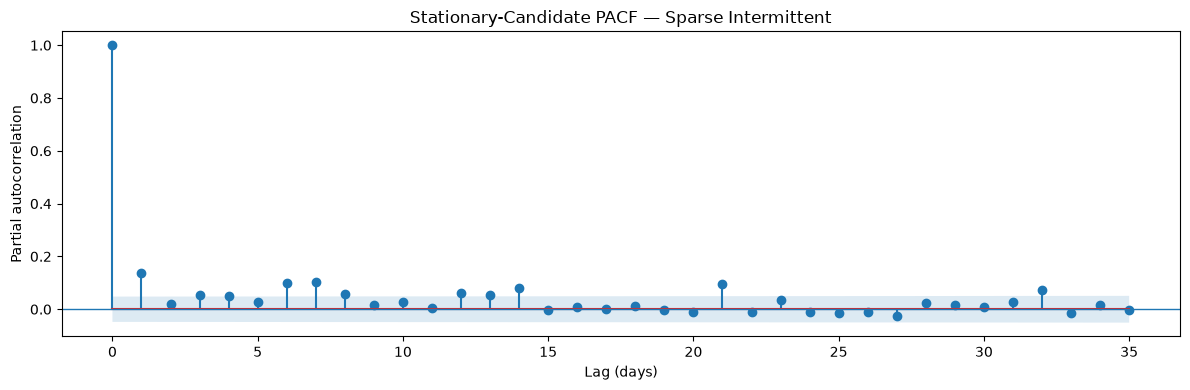

In [75]:
for archetype in selected_series["archetype"]:

    profile = candidate_pacf.loc[
        candidate_pacf["archetype"] == archetype
    ].copy()

    profile["confidence_bound"] = (
        1.96
        / np.sqrt(profile["valid_observations"])
    )

    plt.figure(figsize=(12, 4))

    plt.stem(
        profile["lag"],
        profile["pacf"],
    )

    plt.axhline(0, linewidth=1)

    plt.fill_between(
        profile["lag"],
        -profile["confidence_bound"],
        profile["confidence_bound"],
        alpha=0.15,
    )

    plt.xlabel("Lag (days)")
    plt.ylabel("Partial autocorrelation")
    plt.title(
        f"Stationary-Candidate PACF — "
        f"{archetype.replace('_', ' ').title()}"
    )

    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_candidate_pacf.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

### Time-Series Diagnostics — Final Takeaway

The representative-series analysis reveals substantial heterogeneity in the
temporal structure of retail demand.

- **High-volume stable demand** exhibits a strong and persistent weekly
  seasonal pattern together with a changing long-term level. Weekly seasonal
  differencing removes most of the repeated seven-day dependence and produces
  a representation compatible with level stationarity. The remaining
  ACF/PACF structure suggests a dominant seasonal MA component together with
  some short-term non-seasonal dependence.

- **Active volatile demand** is characterized by strong short-term persistence
  and recurring high-volatility episodes. First differencing removes the
  changing local level and leaves an oscillating autocorrelation pattern,
  suggesting a compact autoregressive structure with negative short-lag
  dependence.

- **Typical demand** exhibits clear regime and level changes in its raw form.
  First differencing produces a stationary candidate whose ACF is dominated by
  a large negative lag-1 spike while the PACF decays over several lags. This is
  strongly suggestive of a low-order moving-average structure.

- **Sparse intermittent demand** is already compatible with approximate
  level stationarity in raw form. Its autocorrelations are statistically
  detectable but individually weak and do not exhibit a clean low-order
  AR/MA signature. This indicates that calendar effects, occurrence dynamics,
  and cross-series information may be more useful than a complex local ARIMA
  specification.

These diagnostics also motivate the later global forecasting feature set.
Different demand regimes expose different useful signals: short lags,
weekly lags, rolling levels and variability, calendar variables, and
intermittency measures such as recent positive-demand rates and zero shares.

The representative series are diagnostic probes rather than fixed production
segments. Their purpose is to understand the diversity of temporal behavior,
define classical local benchmarks, and motivate point-in-time-safe features
for the later global forecasting model.

## 7. Classical Forecasting Models

The previous diagnostics identified plausible stationary representations and
AR/MA structures for the four representative demand series.

The objective is now to convert these diagnostics into explicit classical
forecasting models.

Candidate specifications are evaluated using three complementary criteria:

1. **Akaike Information Criterion (AIC)**

$$
AIC = -2\log(L) + 2k
$$

2. **Bayesian Information Criterion (BIC)**

$$
BIC = -2\log(L) + k\log(n)
$$

where $L$ is the maximized likelihood, $k$ is the number of estimated
parameters, and $n$ is the number of observations.

Lower AIC and BIC values indicate a better trade-off between model fit and
complexity, with BIC applying a stronger complexity penalty.

3. **Out-of-sample forecasting performance**

AIC and BIC are in-sample model-selection criteria and are not substitutes for
forecast evaluation. Candidate models will therefore ultimately be compared
using the shared rolling 14-day development-validation framework used for the
seasonal-naive baseline.

The original level series are passed directly to the models. Differencing is
specified through the ARIMA/SARIMA orders themselves, avoiding accidental
double differencing.

In [76]:
classical_model_candidates = {
    "high_volume_stable": [
        {
            "name": "SARIMA(0,0,0)(0,1,1,7)",
            "order": (0, 0, 0),
            "seasonal_order": (0, 1, 1, 7),
            "trend": "n",
        },
        {
            "name": "SARIMA(1,0,0)(0,1,1,7)",
            "order": (1, 0, 0),
            "seasonal_order": (0, 1, 1, 7),
            "trend": "n",
        },
        {
            "name": "SARIMA(0,0,1)(0,1,1,7)",
            "order": (0, 0, 1),
            "seasonal_order": (0, 1, 1, 7),
            "trend": "n",
        },
    ],

    "active_volatile": [
        {
            "name": "ARIMA(1,1,0)",
            "order": (1, 1, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
        {
            "name": "ARIMA(2,1,0)",
            "order": (2, 1, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
        {
            "name": "ARIMA(3,1,0)",
            "order": (3, 1, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
        {
            "name": "ARIMA(1,1,1)",
            "order": (1, 1, 1),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
    ],

    "typical": [
        {
            "name": "ARIMA(0,1,0)",
            "order": (0, 1, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
        {
            "name": "ARIMA(0,1,1)",
            "order": (0, 1, 1),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
        {
            "name": "ARIMA(1,1,0)",
            "order": (1, 1, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
        {
            "name": "ARIMA(1,1,1)",
            "order": (1, 1, 1),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "n",
        },
    ],

    "sparse_intermittent": [
        {
            "name": "ARIMA(0,0,0)",
            "order": (0, 0, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "c",
        },
        {
            "name": "ARIMA(1,0,0)",
            "order": (1, 0, 0),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "c",
        },
        {
            "name": "ARIMA(0,0,1)",
            "order": (0, 0, 1),
            "seasonal_order": (0, 0, 0, 0),
            "trend": "c",
        },
    ],
}

In [77]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

classical_fit_records = []
classical_fitted_models = {}

for archetype, candidates in classical_model_candidates.items():

    series = original_regularized_series[archetype]

    for candidate in candidates:
        try:
            model = SARIMAX(
                series,
                order=candidate["order"],
                seasonal_order=candidate["seasonal_order"],
                trend=candidate["trend"],
                enforce_stationarity=True,
                enforce_invertibility=True,
            )

            result = model.fit(
                disp=False,
            )

            model_key = (
                archetype,
                candidate["name"],
            )

            classical_fitted_models[
                model_key
            ] = result

            classical_fit_records.append(
                {
                    "archetype": archetype,
                    "model": candidate["name"],
                    "aic": result.aic,
                    "bic": result.bic,
                    "log_likelihood": result.llf,
                    "parameters": len(result.params),
                    "converged": result.mle_retvals.get(
                        "converged",
                        None,
                    ),
                }
            )

        except Exception as error:
            classical_fit_records.append(
                {
                    "archetype": archetype,
                    "model": candidate["name"],
                    "aic": np.nan,
                    "bic": np.nan,
                    "log_likelihood": np.nan,
                    "parameters": np.nan,
                    "converged": False,
                    "error": str(error),
                }
            )


classical_fit_summary = pd.DataFrame(
    classical_fit_records
)

display(
    classical_fit_summary
    .sort_values(
        ["archetype", "aic"]
    )
    .style.hide(axis="index")
)

archetype,model,aic,bic,log_likelihood,parameters,converged
active_volatile,"ARIMA(3,1,0)",19837.036735,19858.726229,-9914.518367,4,True
active_volatile,"ARIMA(1,1,1)",19906.362726,19922.629847,-9950.181363,3,True
active_volatile,"ARIMA(2,1,0)",19998.967432,20015.234553,-9996.483716,3,True
active_volatile,"ARIMA(1,1,0)",20002.923060,20013.767807,-9999.461530,2,True
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",25961.960456,25978.216798,-12977.980228,3,True
high_volume_stable,"SARIMA(0,0,1)(0,1,1,7)",25982.248870,25998.505212,-12988.124435,3,True
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",26091.363890,26102.201451,-13043.681945,2,True
sparse_intermittent,"ARIMA(1,0,0)",5556.976988,5573.245902,-2775.488494,3,True
sparse_intermittent,"ARIMA(0,0,1)",5558.219544,5574.488458,-2776.109772,3,True
sparse_intermittent,"ARIMA(0,0,0)",5586.342348,5597.188290,-2791.171174,2,True


### Candidate Model Fit — Takeaway

All candidate specifications converged successfully.

- **High-volume stable demand:** `SARIMA(1,0,0)(0,1,1,7)` is strongly
  preferred by both AIC and BIC. This supports the diagnostic conclusion that
  weekly seasonal differencing and a seasonal MA component capture the dominant
  weekly structure, while a remaining non-seasonal AR(1) term explains
  additional short-term dependence.

- **Active volatile demand:** `ARIMA(3,1,0)` is clearly preferred by both
  information criteria. This is consistent with the oscillating short-lag ACF
  observed after first differencing and suggests that several autoregressive
  lags are useful for describing the remaining dynamics.

- **Typical demand:** `ARIMA(1,1,1)` achieves the lowest AIC, but
  `ARIMA(0,1,1)` remains highly competitive under BIC and is more parsimonious.
  The latter also aligns closely with the MA(1)-like ACF/PACF signature.
  Out-of-sample evaluation is therefore required to determine whether the
  additional AR term improves forecasting performance.

- **Sparse intermittent demand:** low-order AR(1) and MA(1) models provide
  similar information-criterion values and both improve over a constant-only
  model. The difference between AR and MA specifications is small, reinforcing
  the conclusion that the local linear dependence is relatively weak.

Information criteria evaluate in-sample fit adjusted for model complexity.
They are therefore used to rank and validate the already narrowed candidate set rather than to select the
final forecasting model. Residual diagnostics and rolling 14-day
out-of-sample performance remain necessary.

### 7.2 Residual Diagnostics

A good in-sample fit does not guarantee that a time-series model has captured
all predictable temporal structure.

For each fitted model, the one-step-ahead residual at date $t$ is:

$$
e_t = Y_t - \hat{Y}_{t|t-1}
$$

where $\hat{Y}_{t|t-1}$ is the prediction for date $t$ based on information
available before observing $Y_t$.

If the model has adequately captured the temporal dynamics of the series, the
remaining residuals should behave approximately like white noise:

$$
E[e_t] = 0
$$

$$
Var(e_t) = \sigma^2
$$

and, for $k>0$:

$$
Cov(e_t,e_{t-k}) = 0
$$

Residual autocorrelation therefore indicates that predictable temporal
structure remains unexplained by the model.

The Ljung-Box test jointly evaluates residual autocorrelations up to a chosen
lag $m$:

$$
Q =
n(n+2)
\sum_{k=1}^{m}
\frac{\hat{\rho}_k^2}{n-k}
$$

Its hypotheses are:

$$
H_0:
\rho_1 = \rho_2 = \cdots = \rho_m = 0
$$

$$
H_1:
\text{at least one residual autocorrelation is non-zero}
$$

A small p-value therefore indicates remaining serial dependence.

The original calendar contains four missing Christmas observations. This
requires different missing-value treatment for the two residual diagnostics.

The residual ACF is computed on the original calendar using missing-aware
estimation, so that each lag retains its correct calendar meaning.

The standard Ljung-Box test, however, expects a complete regularly spaced
sequence. Rather than dropping the missing dates and compressing time, the
models are therefore refitted on a diagnostic-only version of the series in
which the four missing observations are filled using historical same-weekday
information.

This imputation is used only for the Ljung-Box diagnostic. The original
missing-aware model fits remain the models used for model comparison and
forecast evaluation.

In [78]:
# Extract residuals while preserving the original daily calendar.
classical_residuals = {}

for (archetype, model_name), result in classical_fitted_models.items():
    original_series = original_regularized_series[
        archetype
    ]

    residuals = pd.Series(
        result.resid,
        index=original_series.index,
        dtype=float,
    )

    # A residual is undefined when the target itself was not observed.
    residuals = residuals.mask(
        original_series.isna()
    )

    # Ignore state-space initialization observations when applicable.
    burn = result.loglikelihood_burn

    if burn > 0:
        residuals.iloc[:burn] = np.nan

    classical_residuals[
        (archetype, model_name)
    ] = residuals

In [79]:
residual_summary_records = []

for (archetype, model_name), residuals in classical_residuals.items():
    residual_summary_records.append(
        {
            "archetype": archetype,
            "model": model_name,
            "observed_residuals": residuals.notna().sum(),
            "missing_residuals": residuals.isna().sum(),
            "mean_residual": residuals.mean(),
            "std_residual": residuals.std(),
        }
    )


residual_summary = pd.DataFrame(
    residual_summary_records
)

display(
    residual_summary
    .sort_values(["archetype", "model"])
    .style.hide(axis="index")
)

archetype,model,observed_residuals,missing_residuals,mean_residual,std_residual
active_volatile,"ARIMA(1,1,0)",1669,5,0.352028,98.661947
active_volatile,"ARIMA(1,1,1)",1669,5,3.153188,94.034713
active_volatile,"ARIMA(2,1,0)",1669,5,0.319384,98.278138
active_volatile,"ARIMA(3,1,0)",1669,5,0.272418,93.098677
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",1663,11,69.012351,613.165834
high_volume_stable,"SARIMA(0,0,1)(0,1,1,7)",1663,11,67.024134,592.966977
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",1663,11,65.722366,589.336654
sparse_intermittent,"ARIMA(0,0,0)",1670,4,-0.000000,1.287524
sparse_intermittent,"ARIMA(0,0,1)",1670,4,-0.000046,1.275960
sparse_intermittent,"ARIMA(1,0,0)",1670,4,-0.000006,1.275485


In [80]:
residual_plot_shortlist = {
    "high_volume_stable": [
        "SARIMA(1,0,0)(0,1,1,7)",
        "SARIMA(0,0,0)(0,1,1,7)",
    ],
    "active_volatile": [
        "ARIMA(3,1,0)",
        "ARIMA(1,1,1)",
    ],
    "typical": [
        "ARIMA(1,1,1)",
        "ARIMA(0,1,1)",
    ],
    "sparse_intermittent": [
        "ARIMA(1,0,0)",
        "ARIMA(0,0,1)",
    ],
}

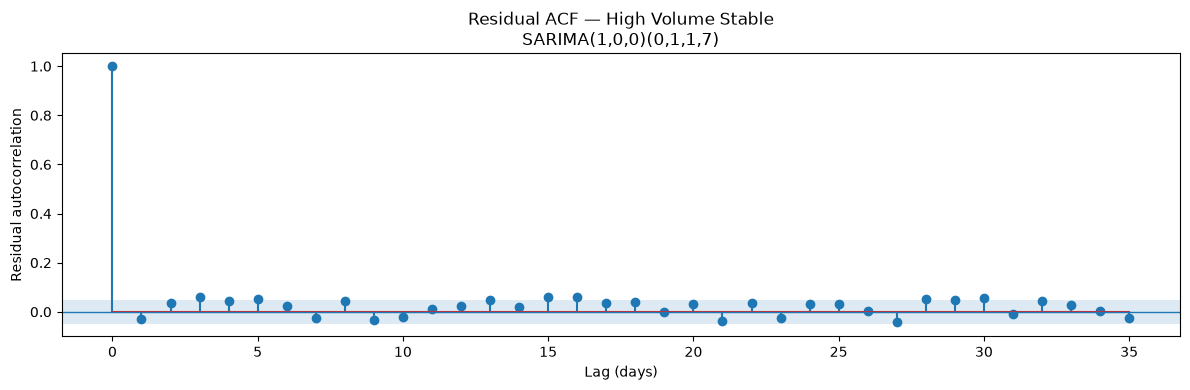

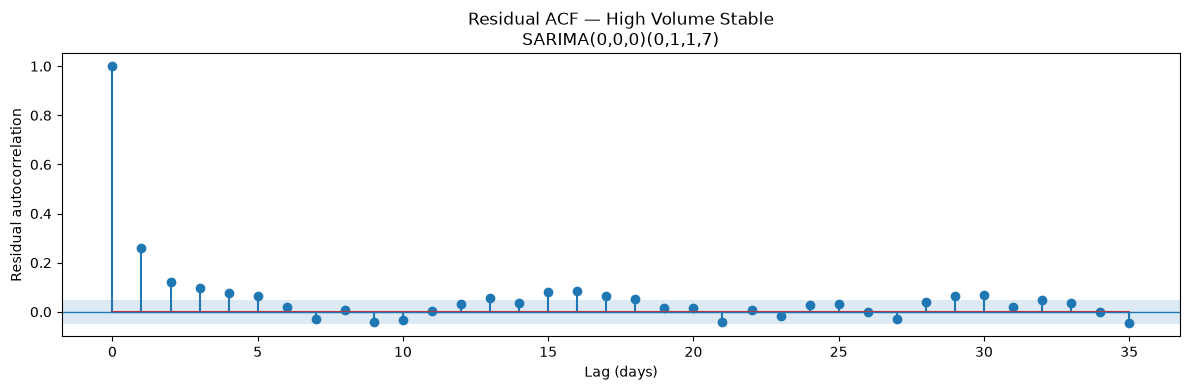

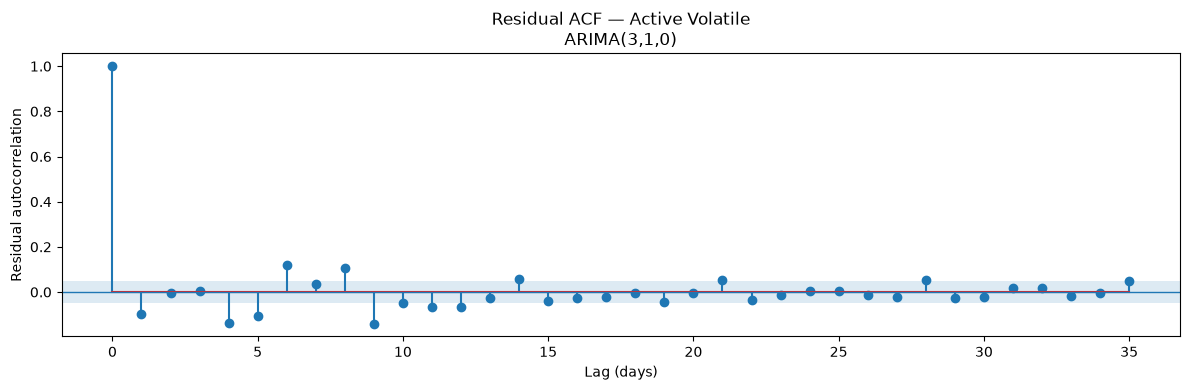

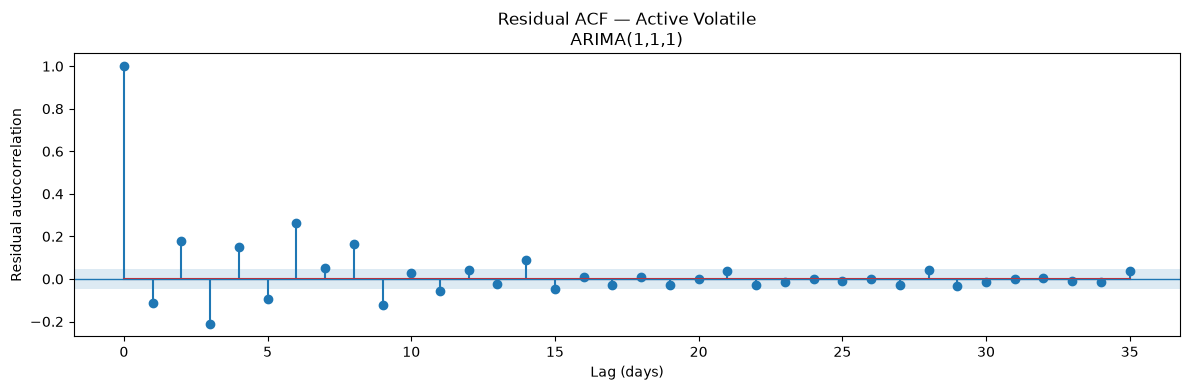

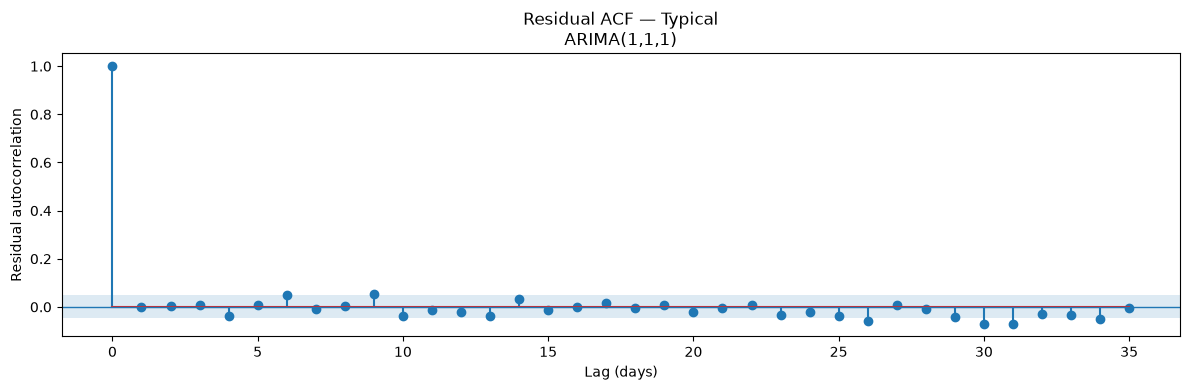

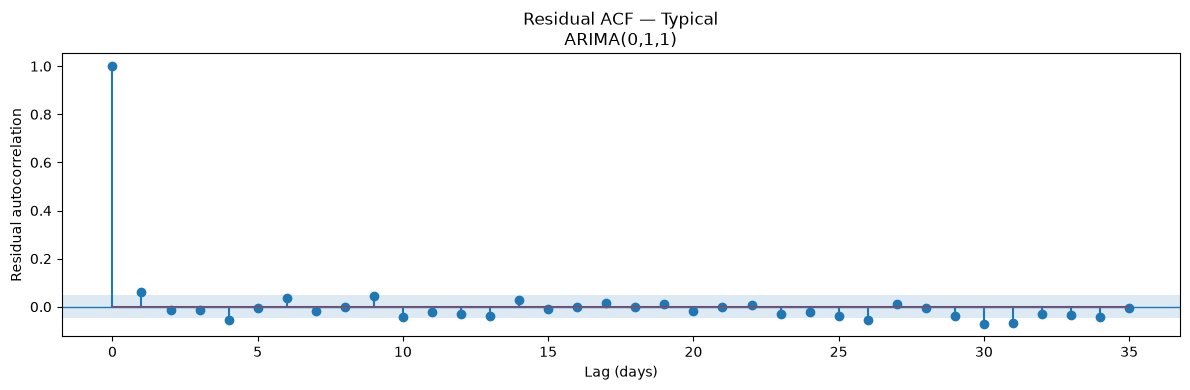

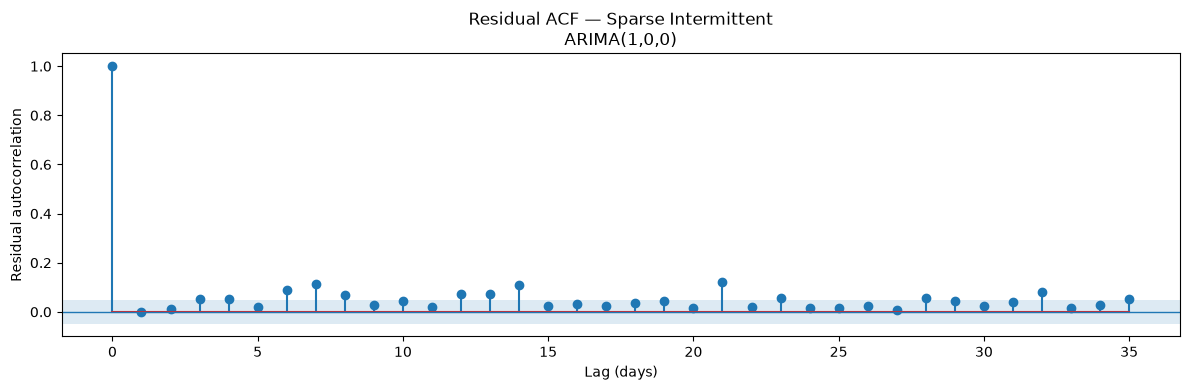

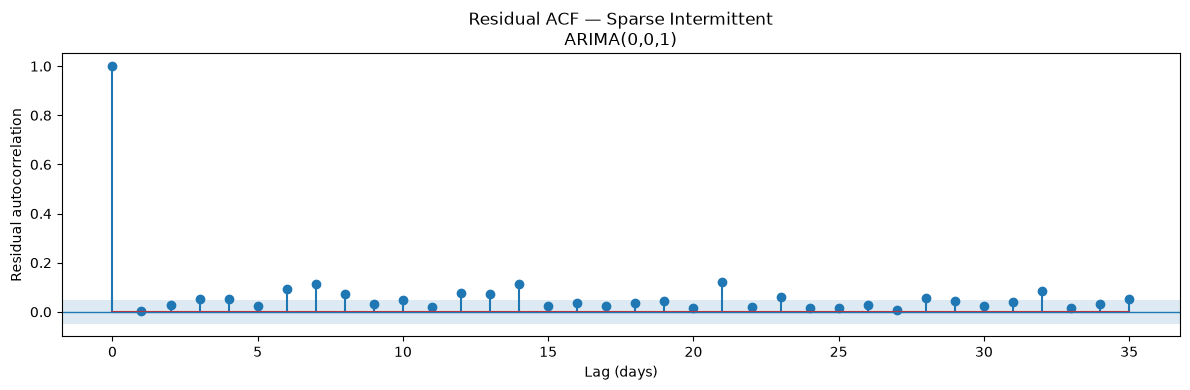

In [81]:
RESIDUAL_MAX_LAG = 35

for archetype, model_names in residual_plot_shortlist.items():

    for model_name in model_names:

        residuals = classical_residuals[
            (archetype, model_name)
        ]

        acf_values = acf(
            residuals,
            nlags=RESIDUAL_MAX_LAG,
            missing="conservative",
            fft=False,
        )

        n_observed = residuals.notna().sum()

        confidence_bound = (
            1.96 / np.sqrt(n_observed)
        )

        plt.figure(figsize=(12, 4))

        plt.stem(
            range(len(acf_values)),
            acf_values,
        )

        plt.axhline(
            0,
            linewidth=1,
        )

        plt.axhspan(
            -confidence_bound,
            confidence_bound,
            alpha=0.15,
        )

        plt.xlabel("Lag (days)")
        plt.ylabel("Residual autocorrelation")
        plt.title(
            f"Residual ACF — {archetype.replace('_', ' ').title()}"
            f"\n{model_name}"
        )

        plt.tight_layout()

        safe_model_name = (
            model_name
            .replace("(", "")
            .replace(")", "")
            .replace(",", "_")
        )

        plt.savefig(
            DIAGNOSTICS_FIGURES_DIR
            / f"{archetype}_{safe_model_name}_residual_acf.png",
            dpi=150,
            bbox_inches="tight",
        )

        plt.show()

#### 7.2.1 Development-History Ljung-Box Diagnostic

The residual ACF can preserve the original calendar through missing-aware
estimation, but the standard Ljung-Box test requires a complete regularly
spaced residual sequence.

The candidate models are therefore refitted on the same diagnostic-only
past-based imputation previously used for the stationarity tests.

For each missing date $t$, the imputed observation uses the same weekday from
the four preceding weeks:

$$
\tilde{Y}_t =
\frac{
Y_{t-7} + Y_{t-14} + Y_{t-21} + Y_{t-28}
}{4}
$$

Only four of 1,674 calendar observations are affected, and no future observation is used.

These refitted models are used exclusively to obtain complete residual
sequences for the Ljung-Box test. They do not replace the original model fits
used for AIC/BIC comparison, residual ACF diagnostics, or forecasting
backtests.

In [82]:
from statsmodels.stats.diagnostic import acorr_ljungbox


candidate_spec_lookup = {
    (archetype, candidate["name"]): candidate
    for archetype, candidates in classical_model_candidates.items()
    for candidate in candidates
}


LJUNG_BOX_LAGS = [7, 14, 28]
SIGNIFICANCE_LEVEL = 0.05

In [83]:
# Refit the same candidate specifications on complete diagnostic-only series.
# These fits are used exclusively for development-history residual diagnostics.
ljung_box_diagnostic_models = {}
ljung_box_diagnostic_residuals = {}

for archetype, candidates in classical_model_candidates.items():

    diagnostic_series = (
        stationarity_test_series[archetype]
        .asfreq("D")
    )

    assert diagnostic_series.isna().sum() == 0

    for candidate in candidates:

        model = SARIMAX(
            diagnostic_series,
            order=candidate["order"],
            seasonal_order=candidate["seasonal_order"],
            trend=candidate["trend"],
            enforce_stationarity=True,
            enforce_invertibility=True,
        )

        result = model.fit(
            disp=False,
        )

        model_key = (
            archetype,
            candidate["name"],
        )

        ljung_box_diagnostic_models[
            model_key
        ] = result

        residuals = pd.Series(
            result.resid,
            index=diagnostic_series.index,
            dtype=float,
        )

        # Remove only state-space initialization residuals at the beginning.
        burn = result.loglikelihood_burn

        if burn > 0:
            residuals.iloc[:burn] = np.nan

        ljung_box_diagnostic_residuals[
            model_key
        ] = residuals

In [84]:
ljung_box_residual_summary = pd.DataFrame(
    [
        {
            "archetype": archetype,
            "model": model_name,
            "rows": len(residuals),
            "valid_residuals": residuals.notna().sum(),
            "missing_residuals": residuals.isna().sum(),
            "first_valid_date": residuals.first_valid_index(),
            "last_valid_date": residuals.last_valid_index(),
        }
        for (
            archetype,
            model_name,
        ), residuals in ljung_box_diagnostic_residuals.items()
    ]
)

display(
    ljung_box_residual_summary
    .sort_values(["archetype", "model"])
    .style.hide(axis="index")
)

archetype,model,rows,valid_residuals,missing_residuals,first_valid_date,last_valid_date
active_volatile,"ARIMA(1,1,0)",1674,1673,1,2013-01-02 00:00:00,2017-08-01 00:00:00
active_volatile,"ARIMA(1,1,1)",1674,1673,1,2013-01-02 00:00:00,2017-08-01 00:00:00
active_volatile,"ARIMA(2,1,0)",1674,1673,1,2013-01-02 00:00:00,2017-08-01 00:00:00
active_volatile,"ARIMA(3,1,0)",1674,1673,1,2013-01-02 00:00:00,2017-08-01 00:00:00
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",1674,1667,7,2013-01-08 00:00:00,2017-08-01 00:00:00
high_volume_stable,"SARIMA(0,0,1)(0,1,1,7)",1674,1667,7,2013-01-08 00:00:00,2017-08-01 00:00:00
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",1674,1667,7,2013-01-08 00:00:00,2017-08-01 00:00:00
sparse_intermittent,"ARIMA(0,0,0)",1674,1674,0,2013-01-01 00:00:00,2017-08-01 00:00:00
sparse_intermittent,"ARIMA(0,0,1)",1674,1674,0,2013-01-01 00:00:00,2017-08-01 00:00:00
sparse_intermittent,"ARIMA(1,0,0)",1674,1674,0,2013-01-01 00:00:00,2017-08-01 00:00:00


In [85]:
full_history_ljung_box_records = []

for (
    archetype,
    model_name,
), residuals in ljung_box_diagnostic_residuals.items():

    candidate = candidate_spec_lookup[
        (archetype, model_name)
    ]

    p, _, q = candidate["order"]
    P, _, Q, _ = candidate["seasonal_order"]

    model_df = p + q + P + Q

    # Any remaining missing residuals occur only during model initialization.
    valid_residuals = residuals.dropna()

    test = acorr_ljungbox(
        valid_residuals,
        lags=LJUNG_BOX_LAGS,
        model_df=model_df,
        return_df=True,
    )

    for lag, row in test.iterrows():
        full_history_ljung_box_records.append(
            {
                "archetype": archetype,
                "model": model_name,
                "lag": lag,
                "model_df": model_df,
                "effective_test_df": lag - model_df,
                "lb_stat": row["lb_stat"],
                "lb_pvalue": row["lb_pvalue"],
                "reject_no_autocorrelation": (
                    row["lb_pvalue"]
                    < SIGNIFICANCE_LEVEL
                ),
            }
        )


full_history_ljung_box = pd.DataFrame(
    full_history_ljung_box_records
)

display(
    full_history_ljung_box
    .sort_values(
        [
            "archetype",
            "model",
            "lag",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,lag,model_df,effective_test_df,lb_stat,lb_pvalue,reject_no_autocorrelation
active_volatile,"ARIMA(1,1,0)",7,1,6,300.729299,0.000000,True
active_volatile,"ARIMA(1,1,0)",14,1,13,369.557530,0.000000,True
active_volatile,"ARIMA(1,1,0)",28,1,27,384.638108,0.000000,True
active_volatile,"ARIMA(1,1,1)",7,2,5,223.603557,0.000000,True
active_volatile,"ARIMA(1,1,1)",14,2,12,282.544676,0.000000,True
active_volatile,"ARIMA(1,1,1)",28,2,26,297.684398,0.000000,True
active_volatile,"ARIMA(2,1,0)",7,2,5,319.342112,0.000000,True
active_volatile,"ARIMA(2,1,0)",14,2,12,394.507481,0.000000,True
active_volatile,"ARIMA(2,1,0)",28,2,26,409.614708,0.000000,True
active_volatile,"ARIMA(3,1,0)",7,3,4,114.935764,0.000000,True


### Residual Diagnostics — Takeaway

Residual diagnostics distinguish good historical fit from complete temporal
specification.

- **High-volume stable demand:** adding the non-seasonal AR(1) term to the
  seasonal specification dramatically reduces residual autocorrelation
  relative to the seasonal-only model. However, the development-history Ljung-Box
  test still rejects residual independence, indicating that some weak temporal
  structure remains unexplained.

- **Active volatile demand:** `ARIMA(3,1,0)` removes substantially more
  short-term dependence than the lower-order alternatives and remains the
  strongest candidate within the tested grid. Nevertheless, Ljung-Box rejects
  residual independence at all tested horizons, consistent with the complex
  regime and volatility behavior observed earlier.

- **Typical demand:** `ARIMA(1,1,1)` produces the cleanest residual diagnostics.
  Ljung-Box does not reject the absence of residual autocorrelation at 7, 14,
  or 28 days. This provides additional support for the AR term that was only
  moderately favored over `ARIMA(0,1,1)` by the information criteria.

- **Sparse intermittent demand:** low-order AR and MA models reduce some local
  dependence but leave substantial residual autocorrelation. This reinforces
  the view that a simple local ARIMA process is not sufficient to represent
  the series' intermittent structure.

Residual independence is a diagnostic criterion rather than the final model
selection objective. With a long history, Ljung-Box can detect small residual
dependencies that may have limited forecasting importance. Candidate models
must therefore be evaluated using point-in-time rolling forecasts over the
actual 14-day business horizon.

### 7.3 Rolling 14-Day Development Validation

In-sample fit and residual diagnostics evaluate whether a model provides a
reasonable statistical representation of development history. The business
objective, however, is to forecast future demand over a 14-day planning
horizon.

Candidate models are therefore compared using a shared rolling temporal
validation framework. At each forecast origin $T$:

1. only observations dated at or before $T$ are available;
2. the model is refitted using this point-in-time training history;
3. a 14-day forecast is produced for $T+1,\ldots,T+14$;
4. no observations inside the forecast horizon are used to update the model;
5. predictions are compared with the subsequently observed development data.

Six non-overlapping validation windows are used. The final labeled period from
2017-08-02 through 2017-08-15 is excluded from this rolling validation and
reserved as the final temporal holdout.

All candidate classical specifications are evaluated on the same validation
origins rather than selecting a single model from AIC/BIC results alone.

#### Point-in-Time Safety

Every rolling-validation forecast is point-in-time safe: model estimation at
origin $T$ uses only target observations available at or before $T$.

The target-based exploratory diagnostics and candidate-model design in this
notebook also use only the development window ending on 2017-08-01. The final
14-day temporal holdout is not used for feature, model, or hyperparameter
selection.

#### Development Validation vs. Final Temporal Holdout

The rolling windows below are used for model development and selection.

A separate 14-day temporal holdout is reserved for the final model audit:

$$
\text{2017-08-02} \rightarrow \text{2017-08-15}
$$

The holdout should be evaluated only after the model family, feature set, and
hyperparameters have been frozen.

After final acceptance, a production model may be refitted using all historical
observations available at its actual deployment forecast origin. The holdout is
therefore an evaluation quarantine, not permanently discarded training data.

In [86]:
VALIDATION_ORIGINS = pd.to_datetime(
    [
        "2017-05-09",
        "2017-05-23",
        "2017-06-06",
        "2017-06-20",
        "2017-07-04",
        "2017-07-18",
    ]
)

assert max(
    origin + pd.Timedelta(days=FORECAST_HORIZON)
    for origin in VALIDATION_ORIGINS
) <= DEVELOPMENT_END_DATE

In [87]:
for origin in VALIDATION_ORIGINS:
    target_start = origin + pd.Timedelta(days=1)
    target_end = origin + pd.Timedelta(days=FORECAST_HORIZON)

    print(
        origin.date(),
        "→",
        target_start.date(),
        "to",
        target_end.date(),
    )

print(
    "\nFinal temporal holdout:",
    FINAL_HOLDOUT_START_DATE.date(),
    "to",
    FINAL_HOLDOUT_END_DATE.date(),
)

2017-05-09 → 2017-05-10 to 2017-05-23
2017-05-23 → 2017-05-24 to 2017-06-06
2017-06-06 → 2017-06-07 to 2017-06-20
2017-06-20 → 2017-06-21 to 2017-07-04
2017-07-04 → 2017-07-05 to 2017-07-18
2017-07-18 → 2017-07-19 to 2017-08-01

Final temporal holdout: 2017-08-02 to 2017-08-15


In [88]:
def compute_forecast_metrics(actual, prediction):
    """
    Compute the forecasting metrics used throughout the project.

    Positive normalized bias means overforecasting.
    Negative normalized bias means underforecasting.
    """
    actual = np.asarray(actual, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    error = prediction - actual
    absolute_error = np.abs(error)

    denominator = actual.sum()

    return {
        "mae": absolute_error.mean(),
        "rmse": np.sqrt(np.mean(error ** 2)),
        "wape": (
            absolute_error.sum() / denominator
            if denominator > 0
            else np.nan
        ),
        "bias": (
            error.sum() / denominator
            if denominator > 0
            else np.nan
        ),
    }

In [89]:
def seasonal_naive_forecast(
    series,
    origin,
    horizon=14,
    season_length=7,
):
    """
    Produce a leakage-safe multi-step seasonal-naive forecast.

    For horizons beyond one seasonal cycle, reuse only observations
    that were already available at the forecast origin.
    """
    predictions = []

    for h in range(1, horizon + 1):
        target_date = origin + pd.Timedelta(days=h)

        seasonal_cycles_back = int(
            np.ceil(h / season_length)
        )

        source_date = (
            target_date
            - pd.Timedelta(
                days=season_length * seasonal_cycles_back
            )
        )

        assert source_date <= origin

        predictions.append(
            series.loc[source_date]
        )

    target_index = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=horizon,
        freq="D",
    )

    return pd.Series(
        predictions,
        index=target_index,
        dtype=float,
    )

#### Non-Negative Forecast Constraint

ARIMA and SARIMA are linear models and may produce negative point forecasts,
although retail sales cannot be negative.

For business evaluation, classical forecasts are therefore constrained using:

$$
\hat{Y}^{+}_{T+h|T}
=
\max(0,\hat{Y}_{T+h|T})
$$

The raw model prediction is retained for diagnostic purposes, and the number
of forecasts requiring clipping is recorded.

This deterministic post-processing uses no future information.

In [90]:
classical_backtest_records = []
classical_backtest_fit_records = []

for archetype, candidates in classical_model_candidates.items():

    full_series = (
        original_regularized_series[archetype]
        .asfreq("D")
    )

    for origin in VALIDATION_ORIGINS:

        train_series = full_series.loc[:origin]

        target_index = pd.date_range(
            start=origin + pd.Timedelta(days=1),
            periods=FORECAST_HORIZON,
            freq="D",
        )

        actual = full_series.reindex(
            target_index
        )

        assert actual.notna().all(), (
            f"Missing target values for "
            f"{archetype} at origin {origin}"
        )

        # Seasonal-naive benchmark.
        baseline_prediction = seasonal_naive_forecast(
            series=full_series,
            origin=origin,
            horizon=FORECAST_HORIZON,
            season_length=7,
        )

        for h, target_date in enumerate(
            target_index,
            start=1,
        ):
            classical_backtest_records.append(
                {
                    "archetype": archetype,
                    "model": "SeasonalNaive7",
                    "origin": origin,
                    "target_date": target_date,
                    "horizon": h,
                    "actual": actual.loc[target_date],
                    "raw_prediction": baseline_prediction.loc[
                        target_date
                    ],
                    "prediction": baseline_prediction.loc[
                        target_date
                    ],
                    "was_clipped": False,
                }
            )

        # Classical model candidates.
        for candidate in candidates:

            try:
                model = SARIMAX(
                    train_series,
                    order=candidate["order"],
                    seasonal_order=candidate[
                        "seasonal_order"
                    ],
                    trend=candidate["trend"],
                    enforce_stationarity=True,
                    enforce_invertibility=True,
                )

                result = model.fit(
                    disp=False,
                )

                raw_prediction = pd.Series(
                    np.asarray(
                        result.get_forecast(
                            steps=FORECAST_HORIZON
                        ).predicted_mean
                    ),
                    index=target_index,
                    dtype=float,
                )

                prediction = raw_prediction.clip(
                    lower=0.0
                )

                classical_backtest_fit_records.append(
                    {
                        "archetype": archetype,
                        "model": candidate["name"],
                        "origin": origin,
                        "converged": result.mle_retvals.get(
                            "converged",
                            None,
                        ),
                    }
                )

                for h, target_date in enumerate(
                    target_index,
                    start=1,
                ):
                    classical_backtest_records.append(
                        {
                            "archetype": archetype,
                            "model": candidate["name"],
                            "origin": origin,
                            "target_date": target_date,
                            "horizon": h,
                            "actual": actual.loc[target_date],
                            "raw_prediction": raw_prediction.loc[
                                target_date
                            ],
                            "prediction": prediction.loc[
                                target_date
                            ],
                            "was_clipped": (
                                raw_prediction.loc[target_date]
                                < 0
                            ),
                        }
                    )

            except Exception as error:
                classical_backtest_fit_records.append(
                    {
                        "archetype": archetype,
                        "model": candidate["name"],
                        "origin": origin,
                        "converged": False,
                        "error": str(error),
                    }
                )

In [91]:
classical_backtest_forecasts = pd.DataFrame(
    classical_backtest_records
)

classical_backtest_fits = pd.DataFrame(
    classical_backtest_fit_records
)

In [92]:
display(
    classical_backtest_fits
    .sort_values(
        [
            "archetype",
            "model",
            "origin",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,origin,converged
active_volatile,"ARIMA(1,1,0)",2017-05-09 00:00:00,True
active_volatile,"ARIMA(1,1,0)",2017-05-23 00:00:00,True
active_volatile,"ARIMA(1,1,0)",2017-06-06 00:00:00,True
active_volatile,"ARIMA(1,1,0)",2017-06-20 00:00:00,True
active_volatile,"ARIMA(1,1,0)",2017-07-04 00:00:00,True
active_volatile,"ARIMA(1,1,0)",2017-07-18 00:00:00,True
active_volatile,"ARIMA(1,1,1)",2017-05-09 00:00:00,True
active_volatile,"ARIMA(1,1,1)",2017-05-23 00:00:00,True
active_volatile,"ARIMA(1,1,1)",2017-06-06 00:00:00,True
active_volatile,"ARIMA(1,1,1)",2017-06-20 00:00:00,True


In [93]:
def summarize_backtest_group(group):
    metrics = compute_forecast_metrics(
        actual=group["actual"],
        prediction=group["prediction"],
    )

    return pd.Series(
        {
            **metrics,
            "forecast_rows": len(group),
            "clipped_forecasts": group[
                "was_clipped"
            ].sum(),
        }
    )


classical_backtest_summary = (
    classical_backtest_forecasts
    .groupby(
        [
            "archetype",
            "model",
        ]
    )
    .apply(
        summarize_backtest_group,
        include_groups=False,
    )
    .reset_index()
)


display(
    classical_backtest_summary
    .sort_values(
        [
            "archetype",
            "wape",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,mae,rmse,wape,bias,forecast_rows,clipped_forecasts
active_volatile,SeasonalNaive7,27.666060,36.149975,0.329616,0.036404,84.000000,0.000000
active_volatile,"ARIMA(3,1,0)",32.194488,43.793303,0.383568,-0.009643,84.000000,0.000000
active_volatile,"ARIMA(1,1,1)",32.564543,41.982296,0.387977,0.113812,84.000000,0.000000
active_volatile,"ARIMA(1,1,0)",33.183600,47.070601,0.395352,-0.167542,84.000000,0.000000
active_volatile,"ARIMA(2,1,0)",33.905850,47.793343,0.403957,-0.171900,84.000000,0.000000
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",396.728638,546.180741,0.098174,-0.024747,84.000000,0.000000
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",399.185470,553.383458,0.098782,-0.026025,84.000000,0.000000
high_volume_stable,"SARIMA(0,0,1)(0,1,1,7)",399.903720,551.642510,0.098960,-0.025299,84.000000,0.000000
high_volume_stable,SeasonalNaive7,491.107143,665.331738,0.121529,-0.000545,84.000000,0.000000
sparse_intermittent,"ARIMA(0,0,1)",0.893479,1.303154,1.294004,-0.203992,84.000000,0.000000


#### Why Metric Rankings Can Differ

Different forecasting metrics encode different error preferences.

WAPE penalizes absolute errors linearly:

$$
WAPE =
\frac{
\sum_t |\hat{Y}_t-Y_t|
}{
\sum_t Y_t
}
$$

whereas RMSE applies a quadratic penalty:

$$
RMSE =
\sqrt{
\frac{1}{n}
\sum_t
(\hat{Y}_t-Y_t)^2
}
$$

RMSE therefore places disproportionately more weight on a small number of
large forecast misses.

A model can consequently achieve a slightly better WAPE by reducing total
absolute error while another model achieves a better RMSE by avoiding the
largest individual errors.

Model rankings should therefore be interpreted relative to the business
objective: WAPE is the primary aggregate accuracy metric in this project,
while RMSE complements it by highlighting sensitivity to large errors.

In [94]:
classical_backtest_by_origin = (
    classical_backtest_forecasts
    .groupby(
        [
            "archetype",
            "model",
            "origin",
        ]
    )
    .apply(
        summarize_backtest_group,
        include_groups=False,
    )
    .reset_index()
)


display(
    classical_backtest_by_origin
    .sort_values(
        [
            "archetype",
            "origin",
            "wape",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,origin,mae,rmse,wape,bias,forecast_rows,clipped_forecasts
active_volatile,SeasonalNaive7,2017-05-09 00:00:00,32.754357,41.622510,0.332207,0.008971,14.000000,0.000000
active_volatile,"ARIMA(3,1,0)",2017-05-09 00:00:00,34.853968,52.598456,0.353502,-0.110293,14.000000,0.000000
active_volatile,"ARIMA(1,1,1)",2017-05-09 00:00:00,35.712212,53.093215,0.362206,-0.048282,14.000000,0.000000
active_volatile,"ARIMA(1,1,0)",2017-05-09 00:00:00,35.793299,59.124879,0.363029,-0.290189,14.000000,0.000000
active_volatile,"ARIMA(2,1,0)",2017-05-09 00:00:00,36.567972,60.210617,0.370886,-0.309880,14.000000,0.000000
active_volatile,SeasonalNaive7,2017-05-23 00:00:00,27.025714,36.991702,0.303472,-0.028446,14.000000,0.000000
active_volatile,"ARIMA(1,1,1)",2017-05-23 00:00:00,32.561357,43.351717,0.365631,0.142437,14.000000,0.000000
active_volatile,"ARIMA(1,1,0)",2017-05-23 00:00:00,33.052158,43.517536,0.371143,0.150442,14.000000,0.000000
active_volatile,"ARIMA(2,1,0)",2017-05-23 00:00:00,34.234242,44.208200,0.384416,0.172914,14.000000,0.000000
active_volatile,"ARIMA(3,1,0)",2017-05-23 00:00:00,36.162241,46.241304,0.406066,0.194687,14.000000,0.000000


#### Metric Aggregation Across Forecast Origins

The aggregate WAPE reported above is not the arithmetic mean of the six
origin-level WAPEs.

For forecast origins $o$ and horizons $h$:

$$
WAPE_{\text{pooled}}
=
\frac{
\sum_o \sum_h
|\hat{Y}_{o,h} - Y_{o,h}|
}{
\sum_o \sum_h Y_{o,h}
}
$$

This can also be written as a volume-weighted average of origin-level WAPEs:

$$
WAPE_{\text{pooled}}
=
\sum_o
w_o \, WAPE_o
$$

with:

$$
w_o =
\frac{
\sum_h Y_{o,h}
}{
\sum_o \sum_h Y_{o,h}
}
$$

Forecast windows with larger realized demand therefore contribute more to the
aggregate WAPE.

As a result, a model does not need to rank first at every individual forecast
origin to achieve the best pooled WAPE. It may perform consistently well and
make its smallest errors during the highest-volume windows.

The same distinction between pooled and unweighted per-origin metrics should
be kept in mind when interpreting model rankings.

This aggregation issue is separate from differences between metric definitions.
For example, WAPE and RMSE can rank the same models differently even on the
same pooled observations because WAPE penalizes absolute error linearly whereas
RMSE disproportionately penalizes large individual misses. Both the aggregation
scheme and the loss geometry therefore matter when interpreting model rankings.

In [95]:
typical_bias_stability = (
    classical_backtest_by_origin[
        (
            classical_backtest_by_origin["archetype"]
            == "typical"
        )
        & classical_backtest_by_origin["model"].isin(
            [
                "ARIMA(1,1,0)",
                "ARIMA(1,1,1)",
            ]
        )
    ]
    .groupby("model")
    .agg(
        unweighted_mean_origin_wape=(
            "wape",
            "mean",
        ),
        std_origin_wape=(
            "wape",
            "std",
        ),
        mean_origin_bias=(
            "bias",
            "mean",
        ),
        mean_absolute_origin_bias=(
            "bias",
            lambda values: values.abs().mean(),
        ),
        maximum_absolute_origin_bias=(
            "bias",
            lambda values: values.abs().max(),
        ),
        underforecast_origin_rate=(
            "bias",
            lambda values: (values < 0).mean(),
        ),
    )
    .reset_index()
)

display(
    typical_bias_stability
    .style.hide(axis="index")
)

model,unweighted_mean_origin_wape,std_origin_wape,mean_origin_bias,mean_absolute_origin_bias,maximum_absolute_origin_bias,underforecast_origin_rate
"ARIMA(1,1,0)",0.341756,0.118621,-0.236979,0.239323,0.428020,0.833333
"ARIMA(1,1,1)",0.366509,0.119905,-0.005657,0.194084,0.279348,0.500000


### Rolling Validation — Takeaway

The 14-day rolling validation confirms that statistical fit and forecasting
performance are related but not equivalent.

- **Active volatile demand:** the weekly seasonal-naive benchmark achieves the
  best validation accuracy among the tested models (`32.96%` WAPE), while
  `ARIMA(3,1,0)` is the strongest ARIMA candidate (`38.36%` WAPE). This is an
  important counterexample to selecting a model from AIC/BIC or residual
  diagnostics alone: `ARIMA(3,1,0)` is clearly preferred in-sample, yet the
  simple weekly rule generalizes better over the development validation
  windows.

- **High-volume stable demand:** all three SARIMA candidates materially
  outperform the seasonal-naive benchmark. The simplest seasonal
  specification, `SARIMA(0,0,0)(0,1,1,7)`, achieves the best validation WAPE
  (`9.82%`), MAE, and RMSE, despite `SARIMA(1,0,0)(0,1,1,7)` being strongly
  preferred by development-history AIC/BIC and residual diagnostics. The
  additional non-seasonal dynamics improve statistical fit but do not improve
  14-day validation accuracy.

- **Typical demand:** `ARIMA(1,1,0)` achieves the best WAPE and MAE (`35.30%`
  WAPE), but its aggregate normalized bias is strongly negative (`-24.99%`).
  `ARIMA(1,1,1)` has moderately worse WAPE (`37.89%`) but lower RMSE and a
  near-neutral aggregate bias (`-1.13%`). `ARIMA(0,1,1)` is similarly
  well-balanced but slightly worse on WAPE and RMSE. Accuracy and directional
  bias therefore create a genuine model-selection trade-off that should be
  investigated before fixing the classical benchmark.

- **Sparse intermittent demand:** low-order ARIMA models outperform the
  seasonal-naive benchmark, with `ARIMA(0,0,1)` achieving the lowest aggregate
  WAPE. However, WAPE remains above 100% because realized demand is extremely
  small. MAE, bias, grouped sparse-demand metrics, and eventually scaled or
  occurrence-based metrics are therefore necessary complements.

Performance also varies materially across forecast origins. No local classical
specification dominates in every temporal regime, and a simple seasonal
baseline can remain difficult to beat even when richer models have superior
in-sample diagnostics.

#### Classical Benchmark Shortlist for Cross-Family Comparison

The development validation leaves the following models as the relevant
benchmarks to carry into the ETS comparison:

- **Active volatile:** `SeasonalNaive7` is the current accuracy benchmark;
  `ARIMA(3,1,0)` is retained as the strongest ARIMA diagnostic candidate.
- **High-volume stable:** `SARIMA(0,0,0)(0,1,1,7)` is the validation winner;
  `SARIMA(1,0,0)(0,1,1,7)` is retained as the stronger in-sample diagnostic
  competitor.
- **Typical:** `ARIMA(1,1,0)` is the accuracy leader, while `ARIMA(1,1,1)` is
  the stronger uncalibrated bias/residual compromise. Both remain relevant
  until the bias-calibration sensitivity analysis is completed.
- **Sparse intermittent:** `ARIMA(0,0,1)` is the best low-order ARIMA benchmark,
  while interpretation remains constrained by unstable individual-series WAPE.

ETS models will be evaluated on the same six validation origins and against
these benchmarks plus the weekly seasonal-naive baseline.

### Modeling Implications for the Global Forecasting Model

The classical-model experiment provides several design lessons for the later
global forecasting system.

**Temporal regimes matter.**  
Model rankings change materially across forecast origins even within a single
series. Point-in-time regime indicators such as rolling level, rolling
volatility, recent growth, zero share, positive-demand rate, and time since the
last positive observation may therefore help a global model adapt its behavior
over time.

**Lagged demand is useful, but richer local dynamics do not always generalize.**  
The high-volume, typical, and sparse representatives all benefit from classical
models that exploit temporal dependence. However, the active-volatile series is
forecast more accurately by the simple weekly seasonal-naive benchmark than by
any tested ARIMA specification. This supports exposing short and seasonal lags
to the global model while also retaining simple baselines as mandatory
benchmarks rather than assuming that additional temporal complexity must help.

**Weekly structure is operationally important.**  
The strong performance of weekly seasonal-naive and seasonal SARIMA models
supports point-in-time-safe features such as $lag_7$, $lag_{14}$, and calendar
weekday variables, alongside shorter lags where diagnostics justify them.

**Aggregate and slice-level evaluation must coexist.**  
A strong portfolio WAPE can hide poor behavior on low-volume or intermittent
series. Evaluation should therefore report both portfolio-level metrics and
performance slices based on demand volume, sparsity, store, family, behavioral
regime, and forecast lead time.

For intermittent-demand slices, individual-series WAPE may become unstable
because realized demand is close to zero. Grouped WAPE, MAE, bias, and later
scaled and occurrence/magnitude diagnostics will therefore complement the
primary global metric.

These findings motivate a global model that shares statistical strength across
series while remaining sensitive to point-in-time demand regimes and being
benchmarked against robust simple forecasting rules.

### 7.4 Forecast Performance by Horizon

The previous rolling-backtest metrics pooled all forecast lead times from
$h=1$ through $h=14$.

However, a 14-day forecast is a vector of distinct predictions:

$$
\hat{Y}_{T+1|T},
\hat{Y}_{T+2|T},
\ldots,
\hat{Y}_{T+14|T}
$$

where $h$ represents the number of days between the forecast origin $T$ and
the target date.

Forecast uncertainty generally increases with lead time because recent
information becomes progressively less informative about more distant targets.

Performance is therefore evaluated separately for each:

$$
h \in \{1,\ldots,14\}
$$

using the six rolling forecast origins.

For a given horizon $h$, pooled WAPE is:

$$
WAPE_h
=
\frac{
\sum_o
|\hat{Y}_{o,h} - Y_{o,h}|
}{
\sum_o Y_{o,h}
}
$$

Because each horizon contains only six forecasts per representative series,
individual points may be noisy. The analysis therefore focuses on systematic
lead-time patterns rather than isolated horizon values.

In [96]:
HORIZON_MODEL_SHORTLIST = {
    "active_volatile": [
        "SeasonalNaive7",
        "ARIMA(3,1,0)",
    ],
    "high_volume_stable": [
        "SeasonalNaive7",
        "SARIMA(0,0,0)(0,1,1,7)",
        "SARIMA(1,0,0)(0,1,1,7)",
    ],
    "typical": [
        "SeasonalNaive7",
        "ARIMA(1,1,0)",
        "ARIMA(1,1,1)",
    ],
    "sparse_intermittent": [
        "SeasonalNaive7",
        "ARIMA(0,0,1)",
    ],
}

In [97]:
horizon_forecast_frames = []

for archetype, models in HORIZON_MODEL_SHORTLIST.items():

    horizon_forecast_frames.append(
        classical_backtest_forecasts[
            (
                classical_backtest_forecasts["archetype"]
                == archetype
            )
            & classical_backtest_forecasts[
                "model"
            ].isin(models)
        ]
    )


horizon_forecasts = pd.concat(
    horizon_forecast_frames,
    ignore_index=True,
)

In [98]:
def summarize_horizon_group(group):
    metrics = compute_forecast_metrics(
        actual=group["actual"],
        prediction=group["prediction"],
    )

    return pd.Series(
        {
            **metrics,
            "forecast_rows": len(group),
            "total_actual": group["actual"].sum(),
        }
    )


classical_horizon_summary = (
    horizon_forecasts
    .groupby(
        [
            "archetype",
            "model",
            "horizon",
        ]
    )
    .apply(
        summarize_horizon_group,
        include_groups=False,
    )
    .reset_index()
)

In [99]:
display(
    classical_horizon_summary.loc[(classical_horizon_summary['archetype'] == 'typical') | ((classical_horizon_summary['archetype'] == 'sparse_intermittent'))]
    .sort_values(
        [
            "archetype",
            "model",
            "horizon",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,horizon,mae,rmse,wape,bias,forecast_rows,total_actual
sparse_intermittent,"ARIMA(0,0,1)",1,0.965896,1.148552,1.159076,-0.188397,6.000000,5.000000
sparse_intermittent,"ARIMA(0,0,1)",2,0.859088,1.117642,1.718175,0.079755,6.000000,3.000000
sparse_intermittent,"ARIMA(0,0,1)",3,0.515003,0.516351,1.545009,0.619632,6.000000,2.000000
sparse_intermittent,"ARIMA(0,0,1)",4,0.691295,0.770927,2.073886,0.619632,6.000000,2.000000
sparse_intermittent,"ARIMA(0,0,1)",5,0.524629,0.525589,3.147771,2.239264,6.000000,1.000000
sparse_intermittent,"ARIMA(0,0,1)",6,1.361993,2.285648,1.361993,-0.460123,6.000000,6.000000
sparse_intermittent,"ARIMA(0,0,1)",7,0.837465,1.110546,1.004958,-0.352147,6.000000,5.000000
sparse_intermittent,"ARIMA(0,0,1)",8,0.524629,0.525589,3.147771,2.239264,6.000000,1.000000
sparse_intermittent,"ARIMA(0,0,1)",9,0.513411,0.514807,1.540233,0.619632,6.000000,2.000000
sparse_intermittent,"ARIMA(0,0,1)",10,1.026221,1.495615,1.539331,-0.190184,6.000000,4.000000


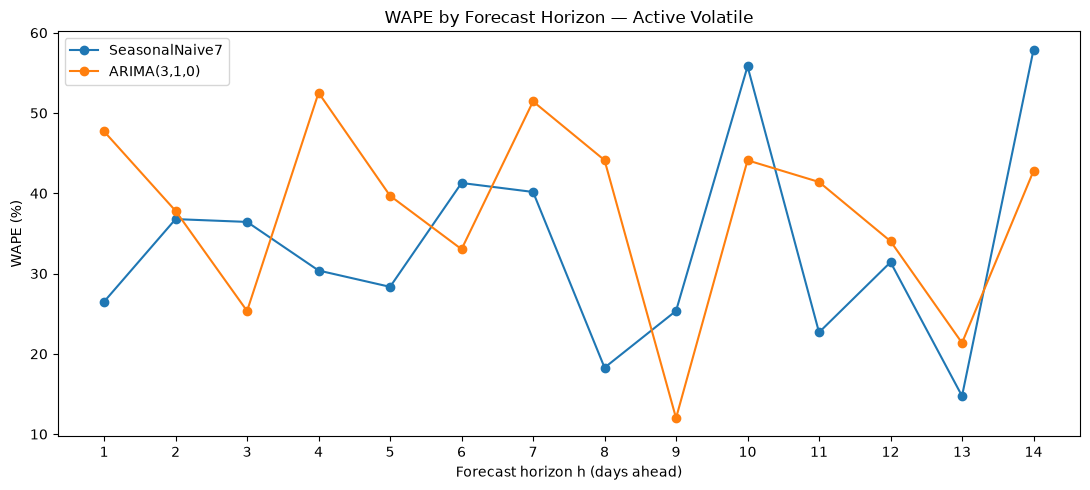

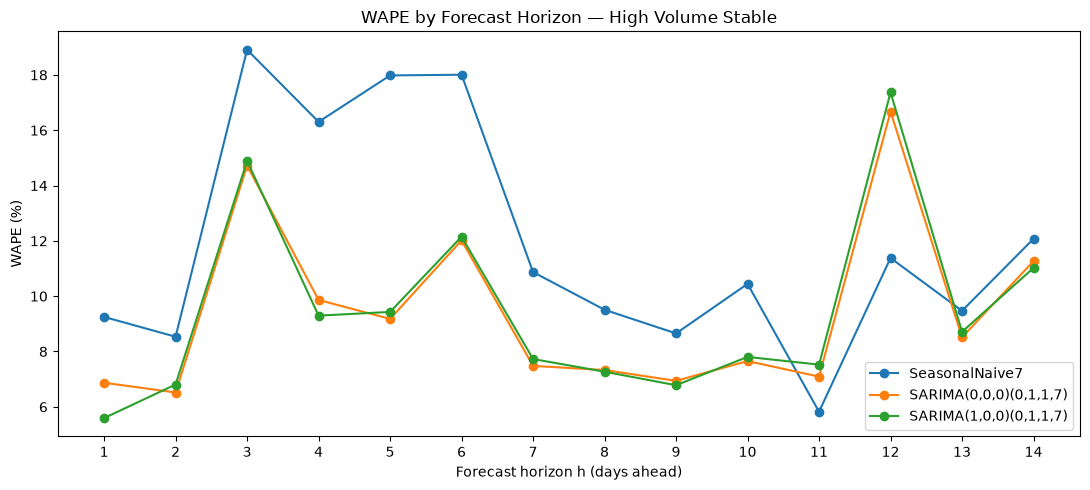

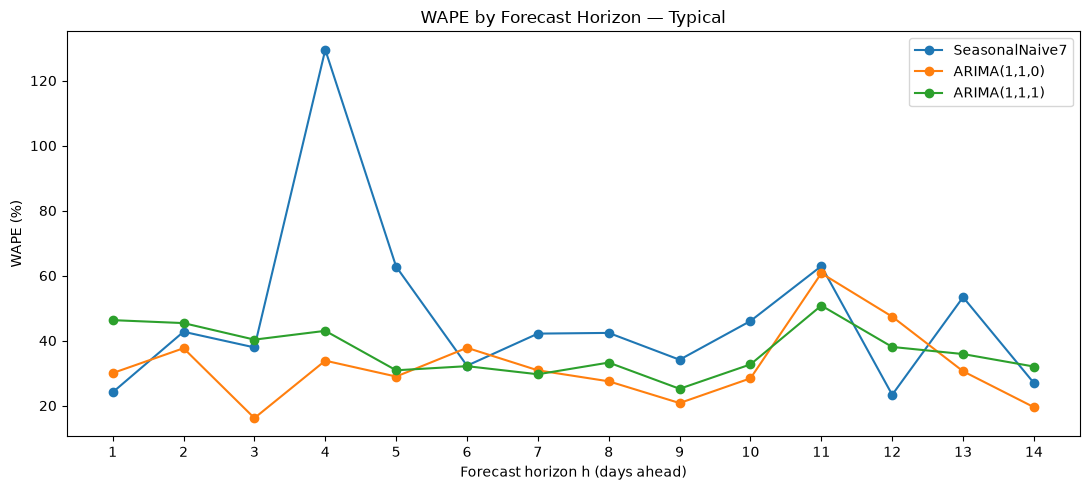

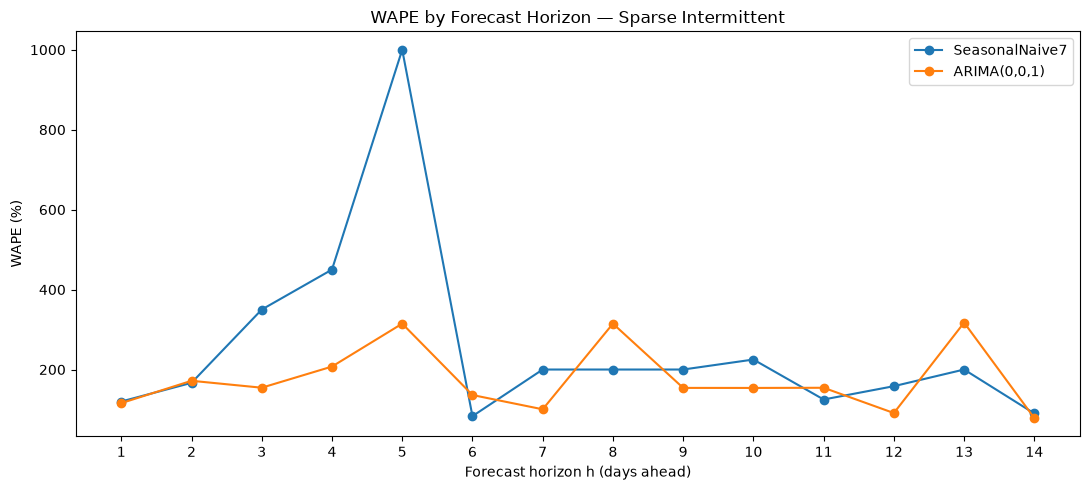

In [100]:
for archetype, models in HORIZON_MODEL_SHORTLIST.items():

    plt.figure(figsize=(11, 5))

    archetype_results = classical_horizon_summary[
        classical_horizon_summary["archetype"]
        == archetype
    ]

    for model_name in models:

        model_results = archetype_results[
            archetype_results["model"]
            == model_name
        ].sort_values("horizon")

        plt.plot(
            model_results["horizon"],
            100 * model_results["wape"],
            marker="o",
            label=model_name,
        )

    plt.xlabel("Forecast horizon h (days ahead)")
    plt.ylabel("WAPE (%)")
    plt.title(
        f"WAPE by Forecast Horizon — "
        f"{archetype.replace('_', ' ').title()}"
    )
    plt.xticks(range(1, FORECAST_HORIZON + 1))
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        DIAGNOSTICS_FIGURES_DIR
        / f"{archetype}_wape_by_horizon.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

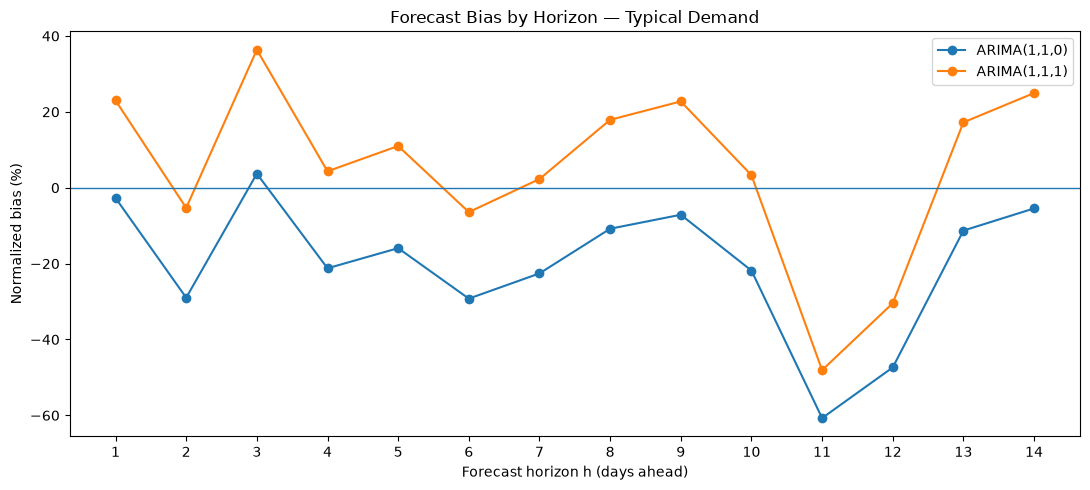

In [101]:
typical_horizon_results = classical_horizon_summary[
    (
        classical_horizon_summary["archetype"]
        == "typical"
    )
    & classical_horizon_summary["model"].isin(
        [
            "ARIMA(1,1,0)",
            "ARIMA(1,1,1)",
        ]
    )
]


plt.figure(figsize=(11, 5))

for model_name in [
    "ARIMA(1,1,0)",
    "ARIMA(1,1,1)",
]:

    model_results = typical_horizon_results[
        typical_horizon_results["model"]
        == model_name
    ].sort_values("horizon")

    plt.plot(
        model_results["horizon"],
        100 * model_results["bias"],
        marker="o",
        label=model_name,
    )


plt.axhline(
    0,
    linewidth=1,
)

plt.xlabel("Forecast horizon h (days ahead)")
plt.ylabel("Normalized bias (%)")
plt.title(
    "Forecast Bias by Horizon — Typical Demand"
)
plt.xticks(range(1, FORECAST_HORIZON + 1))
plt.legend()
plt.tight_layout()

plt.savefig(
    DIAGNOSTICS_FIGURES_DIR
    / "typical_bias_by_horizon.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

#### Bias Stability Across Forecast Horizons

Aggregate bias alone can hide materially different error patterns.

`ARIMA(1,1,0)` exhibits a systematic underforecasting tendency. Its aggregate
bias is approximately `-25.0%`, five of the six validation origins are
underforecast, and the mean absolute origin-level bias is approximately
`23.9%`. The underforecasting also becomes more pronounced in the second
forecast week.

This kind of directional error may be calibratable if its magnitude proves
stable when the calibration rule itself is estimated strictly from earlier
validation history.

`ARIMA(1,1,1)` has a much smaller aggregate bias (approximately `-1.1%`) and a
lower mean absolute origin-level bias (approximately `19.4%`), but it is not
uniformly unbiased. It overforecasts several horizons and underforecasts
others, so positive and negative errors partially offset in the aggregate.

A near-zero aggregate bias can therefore arise either from genuinely stable
calibration or from compensating directional errors. Model comparison should
consider aggregate bias together with bias stability across forecast origins,
lead-time buckets, and operational slices. Before preferring `ARIMA(1,1,1)`
solely for its aggregate bias, a leakage-safe calibration experiment for the
more systematically biased `ARIMA(1,1,0)` is warranted.

#### Separating Lead-Time Effects from Weekday Effects

All six backtest origins occur on the same weekday because they are spaced
exactly 14 days apart.

Consequently, each forecast horizon is associated with a fixed weekday:

- $h=1$ and $h=8$ correspond to the same weekday;
- $h=2$ and $h=9$ correspond to the same weekday;
- and so on.

Pointwise variation across adjacent horizons therefore mixes true lead-time
effects with weekday-specific demand difficulty.

However, horizons $1$–$7$ and $8$–$14$ contain exactly the same weekday
composition. Comparing forecast performance between the first and second
forecast weeks therefore provides a cleaner diagnostic of lead-time
degradation while controlling for weekday mix.

In [102]:
lead_time_week_forecasts = (
    horizon_forecasts
    .copy()
)

lead_time_week_forecasts[
    "forecast_week"
] = np.where(
    lead_time_week_forecasts["horizon"] <= 7,
    "Week 1 (h=1-7)",
    "Week 2 (h=8-14)",
)


lead_time_week_summary = (
    lead_time_week_forecasts
    .groupby(
        [
            "archetype",
            "model",
            "forecast_week",
        ]
    )
    .apply(
        summarize_backtest_group,
        include_groups=False,
    )
    .reset_index()
)


display(
    lead_time_week_summary
    .sort_values(
        [
            "archetype",
            "model",
            "forecast_week",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,forecast_week,mae,rmse,wape,bias,forecast_rows,clipped_forecasts
active_volatile,"ARIMA(3,1,0)",Week 1 (h=1-7),34.206549,46.491354,0.424283,0.039105,42.000000,0.000000
active_volatile,"ARIMA(3,1,0)",Week 2 (h=8-14),30.182427,40.917732,0.345944,-0.054689,42.000000,0.000000
active_volatile,SeasonalNaive7,Week 1 (h=1-7),27.137310,36.380207,0.336600,0.078984,42.000000,0.000000
active_volatile,SeasonalNaive7,Week 2 (h=8-14),28.194810,35.918268,0.323163,-0.002942,42.000000,0.000000
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",Week 1 (h=1-7),377.221761,523.408875,0.095989,0.002856,42.000000,0.000000
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",Week 2 (h=8-14),416.235515,568.040450,0.100243,-0.050871,42.000000,0.000000
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",Week 1 (h=1-7),372.998214,519.700677,0.094915,0.000986,42.000000,0.000000
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",Week 2 (h=8-14),425.372726,585.130505,0.102443,-0.051589,42.000000,0.000000
high_volume_stable,SeasonalNaive7,Week 1 (h=1-7),581.976190,741.583971,0.148092,0.027743,42.000000,0.000000
high_volume_stable,SeasonalNaive7,Week 2 (h=8-14),400.238095,579.125079,0.096390,-0.027317,42.000000,0.000000


In [103]:
lead_time_week_comparison = (
    lead_time_week_summary
    .pivot(
        index=[
            "archetype",
            "model",
        ],
        columns="forecast_week",
        values=[
            "wape",
            "mae",
            "rmse",
            "bias",
        ],
    )
)

lead_time_week_comparison.columns = [
    f"{metric}_{week}"
    for metric, week
    in lead_time_week_comparison.columns
]

lead_time_week_comparison = (
    lead_time_week_comparison
    .reset_index()
)

lead_time_week_comparison[
    "wape_change_week2_minus_week1"
] = (
    lead_time_week_comparison[
        "wape_Week 2 (h=8-14)"
    ]
    - lead_time_week_comparison[
        "wape_Week 1 (h=1-7)"
    ]
)


display(
    lead_time_week_comparison
    .sort_values(
        [
            "archetype",
            "model",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,wape_Week 1 (h=1-7),wape_Week 2 (h=8-14),mae_Week 1 (h=1-7),mae_Week 2 (h=8-14),rmse_Week 1 (h=1-7),rmse_Week 2 (h=8-14),bias_Week 1 (h=1-7),bias_Week 2 (h=8-14),wape_change_week2_minus_week1
active_volatile,"ARIMA(3,1,0)",0.424283,0.345944,34.206549,30.182427,46.491354,40.917732,0.039105,-0.054689,-0.078339
active_volatile,SeasonalNaive7,0.336600,0.323163,27.137310,28.194810,36.380207,35.918268,0.078984,-0.002942,-0.013437
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",0.095989,0.100243,377.221761,416.235515,523.408875,568.040450,0.002856,-0.050871,0.004253
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",0.094915,0.102443,372.998214,425.372726,519.700677,585.130505,0.000986,-0.051589,0.007529
high_volume_stable,SeasonalNaive7,0.148092,0.096390,581.976190,400.238095,741.583971,579.125079,0.027743,-0.027317,-0.051702
sparse_intermittent,"ARIMA(0,0,1)",1.438842,1.191766,0.822196,0.964763,1.204929,1.394476,-0.021100,-0.333093,-0.247077
sparse_intermittent,SeasonalNaive7,2.166667,1.470588,1.238095,1.190476,1.939563,1.864454,0.500000,0.058824,-0.696078
typical,"ARIMA(1,1,0)",0.315132,0.385070,10.159251,14.632677,14.111595,27.243006,-0.181922,-0.307538,0.069939
typical,"ARIMA(1,1,1)",0.380057,0.378004,12.252305,14.364165,14.680037,24.840871,0.075201,-0.084772,-0.002052
typical,SeasonalNaive7,0.536928,0.431704,17.309524,16.404762,27.771602,25.974805,0.133678,-0.038221,-0.105223


### Forecast-Horizon Diagnostics — Takeaway

Forecast performance is not uniform across the 14-day planning horizon.

Because the six development-validation origins are spaced exactly 14 days
apart, each individual horizon is associated with a fixed weekday. Pointwise
horizon-to-horizon variation therefore mixes lead-time effects with
weekday-specific demand behavior. Comparing Week 1 ($h=1$–$7$) with Week 2
($h=8$–$14$) reduces this weekday-composition confounding because both buckets
contain the same seven weekdays.

- **Active volatile demand:** the development validation does not show a simple
  monotonic deterioration with lead time. The seasonal-naive benchmark remains
  stronger overall than `ARIMA(3,1,0)`, reinforcing that a richer local
  autoregressive structure can fit historical dependence without producing
  better operational forecasts.

- **High-volume stable demand:** weekly seasonality remains the dominant useful
  structure. The horizon analysis compares the validation-winning
  `SARIMA(0,0,0)(0,1,1,7)` with the AR(1)-augmented specification preferred by
  in-sample diagnostics and with the weekly seasonal-naive benchmark. The goal
  is to determine whether the extra short-term AR component adds value at any
  particular lead-time range despite not improving aggregate validation WAPE.

- **Typical demand:** `ARIMA(1,1,0)` is materially more accurate in Week 1 but
  deteriorates in Week 2 and becomes more negatively biased. `ARIMA(1,1,1)`
  has worse Week-1 WAPE but much more stable WAPE across the two weeks and
  materially better directional balance. This reinforces the need to evaluate
  a leakage-safe bias-calibration strategy before choosing the final classical
  benchmark for this regime.

- **Sparse intermittent demand:** horizon-level WAPE remains unstable because
  the realized denominator is extremely small. Changes in WAPE can move in the
  opposite direction from MAE, RMSE, or bias, so no lead-time conclusion should
  be based on WAPE alone for this individual sparse series.

The analysis shows that aggregate 14-day performance can hide substantial
variation across lead times. Future global models should therefore be evaluated
both over the full planning horizon and by lead-time buckets, while using a
larger and more diverse set of forecast origins to reduce weekday and
calendar-regime confounding.

### 7.5 Exponential Smoothing / ETS Models

ARIMA/SARIMA and ETS represent temporal structure in fundamentally different
ways.

An ARIMA model describes a series through relationships between lagged values,
differences, and past innovations. In compact form:

$$
\phi(L)(1-L)^dY_t
=
c+\theta(L)\varepsilon_t
$$

where $L$ is the lag operator, $d$ is the non-seasonal differencing order,
$\phi(L)$ contains autoregressive coefficients, $\theta(L)$ contains
moving-average coefficients, and $\varepsilon_t$ is the new innovation at
time $t$.

SARIMA extends this representation with seasonal lag operators:

$$
\Phi(L^m)\phi(L)
(1-L)^d(1-L^m)^DY_t
=
c+
\Theta(L^m)\theta(L)\varepsilon_t
$$

where $m=7$ represents weekly seasonality in the daily Favorita data.

ETS instead represents the series through evolving latent states. Its notation
is:

$$
ETS(E,T,S)
$$

where $E$, $T$, and $S$ respectively describe the error, trend, and seasonal
components.

`A` denotes an additive component, `M` a multiplicative component, `N` the
absence of a component, and `Ad` a damped additive trend.

For example:

- `ETS(A,N,N)` models an adaptive local level;
- `ETS(A,N,A)` adds additive weekly seasonality;
- `ETS(A,A,A)` adds an additive trend;
- `ETS(A,Ad,A)` allows the trend contribution to decay with forecast horizon.

Multiplicative components are not considered in this benchmark because the
representative demand series contain zero observations. The experiment
therefore remains on the original sales scale and uses additive error and
seasonal specifications.

The candidate grid is deliberately small and archetype-specific:

- **High-volume stable:** compare weekly seasonality alone with additive and
  damped-trend extensions.
- **Typical:** test whether an evolving trend improves a weekly seasonal model.
- **Active volatile:** test whether adaptive level, weekly seasonality, or a
  damped trend can represent the observed dynamics.
- **Sparse intermittent:** retain only simple level and seasonal benchmarks
  because standard ETS is not designed specifically for intermittent demand.

Unlike SARIMAX, the ETS implementation used here requires a complete regular
daily training sequence. The four missing Christmas observations are therefore
filled inside each training window using the mean of the same weekday over the
four preceding weeks:

$$
\tilde{Y}_t =
\frac{
Y_{t-7}+Y_{t-14}+Y_{t-21}+Y_{t-28}
}{4}
$$

The imputation uses historical information only and is recomputed independently
inside every rolling-validation training window.m

In [104]:
def impute_past_seasonal_missing_values(
    series,
    season_length=7,
    lookback_seasons=4,
):
    """
    Fill isolated missing observations using only historical values from the
    same seasonal position.

    The function is point-in-time safe because no future observation is used.
    """
    completed = series.copy().astype(float)

    missing_dates = completed.index[
        completed.isna()
    ]

    for missing_date in missing_dates:

        historical_dates = [
            missing_date - pd.Timedelta(
                days=season_length * lag
            )
            for lag in range(
                1,
                lookback_seasons + 1,
            )
        ]

        historical_values = completed.reindex(
            historical_dates
        )

        if historical_values.isna().any():
            raise ValueError(
                "Insufficient historical seasonal values "
                f"to impute {missing_date}."
            )

        completed.loc[missing_date] = (
            historical_values.mean()
        )

    return completed

In [105]:
for archetype in selected_series["archetype"]:

    development_series = (
        original_regularized_series[archetype]
        .loc[:DEVELOPMENT_END_DATE]
    )

    completed_series = (
        impute_past_seasonal_missing_values(
            development_series
        )
    )

    assert completed_series.isna().sum() == 0

print(
    "ETS development series successfully completed:",
    len(selected_series),
)

ETS development series successfully completed: 4


In [106]:
from statsmodels.tsa.exponential_smoothing.ets import (
    ETSModel,
)


ets_model_candidates = {
    "high_volume_stable": [
        {
            "name": "ETS(A,N,A)",
            "error": "add",
            "trend": None,
            "damped_trend": False,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
        {
            "name": "ETS(A,A,A)",
            "error": "add",
            "trend": "add",
            "damped_trend": False,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
        {
            "name": "ETS(A,Ad,A)",
            "error": "add",
            "trend": "add",
            "damped_trend": True,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
    ],

    "typical": [
        {
            "name": "ETS(A,N,A)",
            "error": "add",
            "trend": None,
            "damped_trend": False,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
        {
            "name": "ETS(A,A,A)",
            "error": "add",
            "trend": "add",
            "damped_trend": False,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
        {
            "name": "ETS(A,Ad,A)",
            "error": "add",
            "trend": "add",
            "damped_trend": True,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
    ],

    "active_volatile": [
        {
            "name": "ETS(A,N,N)",
            "error": "add",
            "trend": None,
            "damped_trend": False,
            "seasonal": None,
            "seasonal_periods": None,
        },
        {
            "name": "ETS(A,N,A)",
            "error": "add",
            "trend": None,
            "damped_trend": False,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
        {
            "name": "ETS(A,Ad,A)",
            "error": "add",
            "trend": "add",
            "damped_trend": True,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
    ],

    "sparse_intermittent": [
        {
            "name": "ETS(A,N,N)",
            "error": "add",
            "trend": None,
            "damped_trend": False,
            "seasonal": None,
            "seasonal_periods": None,
        },
        {
            "name": "ETS(A,N,A)",
            "error": "add",
            "trend": None,
            "damped_trend": False,
            "seasonal": "add",
            "seasonal_periods": 7,
        },
    ],
}

#### 7.5.1 Full-Development Fit and Information Criteria

Before evaluating forecasting performance, each ETS candidate is fitted to the
complete development history available through August 1, 2017.

As with the ARIMA/SARIMA analysis, AIC and BIC are used only as in-sample
diagnostics:

$$
AIC = -2\log L + 2k
$$

$$
BIC = -2\log L + k\log n
$$

where:

- $L$ is the maximized likelihood of the fitted model;
- $k$ is the number of estimated model parameters;
- $n$ is the number of observations.

Lower values indicate a better trade-off between historical fit and model
complexity.

The comparison is made **between ETS specifications fitted to the same
archetype and preprocessing pipeline**. AIC/BIC are not used here to rank ETS
directly against the earlier SARIMA models because the two model families do
not use exactly the same treatment of the four missing Christmas observations.

The final cross-family comparison will therefore rely on the common
point-in-time rolling validation rather than information criteria.

In [107]:
def fit_ets_candidate(
    series,
    candidate,
):
    """
    Fit one ETS candidate to a complete regular daily series.
    """
    model = ETSModel(
        endog=series,
        error=candidate["error"],
        trend=candidate["trend"],
        damped_trend=candidate["damped_trend"],
        seasonal=candidate["seasonal"],
        seasonal_periods=candidate["seasonal_periods"],
        initialization_method="estimated",
    )

    result = model.fit(
        maxiter=1000,
        disp=False,
    )

    return result

In [108]:
ets_development_fits = {}
ets_fit_records = []

for archetype, candidates in ets_model_candidates.items():

    development_series = (
        original_regularized_series[archetype]
        .loc[:DEVELOPMENT_END_DATE]
        .asfreq("D")
    )

    ets_training_series = (
        impute_past_seasonal_missing_values(
            development_series
        )
    )

    assert ets_training_series.isna().sum() == 0

    ets_development_fits[archetype] = {}

    for candidate in candidates:

        result = fit_ets_candidate(
            series=ets_training_series,
            candidate=candidate,
        )

        ets_development_fits[
            archetype
        ][candidate["name"]] = result

        mle_retvals = getattr(
            result,
            "mle_retvals",
            {},
        )

        converged = mle_retvals.get(
            "converged",
            np.nan,
        )

        ets_fit_records.append(
            {
                "archetype": archetype,
                "model": candidate["name"],
                "aic": result.aic,
                "bic": result.bic,
                "aicc": getattr(
                    result,
                    "aicc",
                    np.nan,
                ),
                "log_likelihood": result.llf,
                "n_parameters": len(
                    result.params
                ),
                "converged": converged,
            }
        )


ets_fit_summary = pd.DataFrame(
    ets_fit_records
)

In [109]:
display(
    ets_fit_summary
    .sort_values(
        [
            "archetype",
            "aic",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,aic,bic,aicc,log_likelihood,n_parameters,converged
active_volatile,"ETS(A,N,A)",20123.129237,20182.781921,20123.288082,-10050.564619,10,True
active_volatile,"ETS(A,Ad,A)",20129.244516,20205.166114,20129.497681,-10050.622258,13,True
active_volatile,"ETS(A,N,N)",20150.507923,20166.776837,20150.522294,-10072.253962,2,True
high_volume_stable,"ETS(A,N,A)",26248.881308,26308.533992,26249.040153,-13113.440654,10,True
high_volume_stable,"ETS(A,Ad,A)",26254.892084,26330.813681,26255.145248,-13113.446042,13,True
high_volume_stable,"ETS(A,A,A)",26257.028266,26327.526893,26257.247543,-13115.514133,12,True
sparse_intermittent,"ETS(A,N,A)",5492.583310,5552.235994,5492.742155,-2735.291655,10,True
sparse_intermittent,"ETS(A,N,N)",5536.794783,5553.063697,5536.809154,-2765.397392,2,True
typical,"ETS(A,N,A)",14167.880274,14227.532958,14168.039119,-7072.940137,10,True
typical,"ETS(A,Ad,A)",14175.103210,14251.024807,14175.356374,-7073.551605,13,True


#### ETS Full-Development Fit — Takeaway

All ETS candidate specifications converge successfully.

The information criteria suggest that an adaptive level combined with weekly
seasonality is sufficient to describe much of the historical structure in the
dense representative series.

- **High-volume stable:** `ETS(A,N,A)` is preferred by both AIC and BIC.
  Adding either an additive or damped trend does not provide enough additional
  likelihood to justify the extra complexity.

- **Typical:** `ETS(A,N,A)` is also clearly preferred. The non-damped trend
  performs particularly poorly, consistent with a series whose evolving level
  does not follow a stable extrapolatable slope.

- **Active volatile:** AIC prefers `ETS(A,N,A)`, while BIC prefers the much
  simpler `ETS(A,N,N)`. Weekly seasonality improves historical fit, but BIC
  considers its additional parameters too costly. The damped-trend model adds
  complexity without materially improving likelihood.

- **Sparse intermittent:** additive weekly seasonality materially improves AIC
  relative to the simple-level model, while BIC is almost indifferent between
  the two. This does not establish that standard ETS is well suited to
  intermittent demand; out-of-sample forecasting remains the relevant test.

Importantly, the absence of an explicit trend component does not imply a fixed
level. In ETS, the latent level itself is updated recursively over time. A
separate trend state is only useful when a persistent local slope provides
additional predictive structure.

AIC/BIC are used here only to understand the ETS family. Cross-family model
selection will rely on the common rolling validation.

#### 7.5.2 Rolling 14-Day ETS Validation

Information criteria evaluate historical fit and complexity, but the business
objective is forecasting future demand.

All ETS candidates are therefore evaluated using exactly the same six
point-in-time validation origins used for the seasonal-naive and ARIMA/SARIMA
benchmarks.

At each forecast origin $T$:

1. only observations available through $T$ are retained;
2. missing Christmas observations inside that historical window are imputed
   using only earlier same-weekday observations;
3. the ETS model is re-estimated from scratch;
4. forecasts are generated for $T+1,\ldots,T+14$;
5. forecasts are evaluated against the realized demand.

The final August 2–15 temporal holdout remains excluded from this development
validation.

In [111]:
ets_backtest_records = []

for archetype, candidates in ets_model_candidates.items():

    full_series = (
        original_regularized_series[archetype]
        .loc[:DEVELOPMENT_END_DATE]
        .asfreq("D")
    )

    for origin in VALIDATION_ORIGINS:

        training_series = (
            full_series
            .loc[:origin]
        )

        ets_training_series = (
            impute_past_seasonal_missing_values(
                training_series
            )
        )

        forecast_index = pd.date_range(
            start=origin + pd.Timedelta(days=1),
            periods=FORECAST_HORIZON,
            freq="D",
        )

        actual = (
            full_series
            .reindex(forecast_index)
        )

        if actual.isna().any():
            raise ValueError(
                f"Missing validation targets for "
                f"{archetype} at origin {origin.date()}."
            )

        for candidate in candidates:

            result = fit_ets_candidate(
                series=ets_training_series,
                candidate=candidate,
            )

            forecast = pd.Series(
                result.forecast(
                    steps=FORECAST_HORIZON
                ),
                index=forecast_index,
                dtype=float,
            )

            raw_forecast = forecast.copy()

            # Demand cannot be negative.
            forecast = forecast.clip(lower=0)

            for horizon, target_date in enumerate(
                forecast_index,
                start=1,
            ):
                ets_backtest_records.append(
                    {
                        "archetype": archetype,
                        "model": candidate["name"],
                        "origin": origin,
                        "target_date": target_date,
                        "horizon": horizon,
                        "actual": actual.loc[
                            target_date
                        ],
                        "prediction": forecast.loc[
                            target_date
                        ],
                        "raw_prediction": raw_forecast.loc[
                            target_date
                        ],
                        "was_clipped": (
                            raw_forecast.loc[
                                target_date
                            ] < 0
                        ),
                    }
                )


ets_backtest_forecasts = pd.DataFrame(
    ets_backtest_records
)

In [112]:
expected_ets_forecasts = (
    sum(
        len(candidates)
        for candidates
        in ets_model_candidates.values()
    )
    * len(VALIDATION_ORIGINS)
    * FORECAST_HORIZON
)

print(
    "ETS forecast rows:",
    len(ets_backtest_forecasts),
)

print(
    "Expected rows:",
    expected_ets_forecasts,
)

print(
    "Negative raw forecasts:",
    int(
        (
            ets_backtest_forecasts[
                "raw_prediction"
            ] < 0
        ).sum()
    ),
)

print(
    "Clipped forecasts:",
    int(
        ets_backtest_forecasts[
            "was_clipped"
        ].sum()
    ),
)

assert (
    len(ets_backtest_forecasts)
    == expected_ets_forecasts
)

ETS forecast rows: 924
Expected rows: 924
Negative raw forecasts: 4
Clipped forecasts: 4


In [113]:
ets_backtest_summary = (
    ets_backtest_forecasts
    .groupby(
        [
            "archetype",
            "model",
        ]
    )
    .apply(
        summarize_backtest_group,
        include_groups=False,
    )
    .reset_index()
)


display(
    ets_backtest_summary
    .sort_values(
        [
            "archetype",
            "wape",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,mae,rmse,wape,bias,forecast_rows,clipped_forecasts
active_volatile,"ETS(A,N,N)",32.061192,45.681973,0.381980,-0.146915,84.000000,0.000000
active_volatile,"ETS(A,N,A)",34.803086,42.661528,0.414647,-0.039485,84.000000,2.000000
active_volatile,"ETS(A,Ad,A)",34.805468,42.664829,0.414676,-0.039456,84.000000,2.000000
high_volume_stable,"ETS(A,Ad,A)",400.869080,549.746308,0.099199,-0.012972,84.000000,0.000000
high_volume_stable,"ETS(A,N,A)",400.881647,549.754492,0.099202,-0.012964,84.000000,0.000000
high_volume_stable,"ETS(A,A,A)",401.969118,548.087577,0.099471,-0.008960,84.000000,0.000000
sparse_intermittent,"ETS(A,N,A)",1.040340,1.316408,1.506699,0.375745,84.000000,0.000000
sparse_intermittent,"ETS(A,N,N)",1.048394,1.319058,1.518364,0.387055,84.000000,0.000000
typical,"ETS(A,Ad,A)",13.819669,20.075861,0.393509,0.003212,84.000000,0.000000
typical,"ETS(A,N,A)",13.882746,20.023291,0.395305,0.003448,84.000000,0.000000


In [114]:
ets_backtest_by_origin = (
    ets_backtest_forecasts
    .groupby(
        [
            "archetype",
            "model",
            "origin",
        ]
    )
    .apply(
        summarize_backtest_group,
        include_groups=False,
    )
    .reset_index()
)


display(
    ets_backtest_by_origin
    .sort_values(
        [
            "archetype",
            "origin",
            "wape",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,origin,mae,rmse,wape,bias,forecast_rows,clipped_forecasts
active_volatile,"ETS(A,N,N)",2017-05-09 00:00:00,35.266929,57.194332,0.357690,-0.252439,14.000000,0.000000
active_volatile,"ETS(A,N,A)",2017-05-09 00:00:00,38.409828,50.995521,0.389566,-0.193612,14.000000,0.000000
active_volatile,"ETS(A,Ad,A)",2017-05-09 00:00:00,38.410649,50.994601,0.389575,-0.193581,14.000000,0.000000
active_volatile,"ETS(A,N,N)",2017-05-23 00:00:00,31.475534,42.753275,0.353439,0.119926,14.000000,0.000000
active_volatile,"ETS(A,N,A)",2017-05-23 00:00:00,36.705250,43.425973,0.412163,0.203301,14.000000,0.000000
active_volatile,"ETS(A,Ad,A)",2017-05-23 00:00:00,36.708730,43.430513,0.412202,0.203420,14.000000,0.000000
active_volatile,"ETS(A,N,A)",2017-06-06 00:00:00,36.872585,45.992549,0.464251,-0.350069,14.000000,2.000000
active_volatile,"ETS(A,Ad,A)",2017-06-06 00:00:00,36.876205,46.000506,0.464296,-0.350218,14.000000,2.000000
active_volatile,"ETS(A,N,N)",2017-06-06 00:00:00,38.825266,54.291082,0.488836,-0.445212,14.000000,0.000000
active_volatile,"ETS(A,N,N)",2017-06-20 00:00:00,25.808122,34.610631,0.337203,-0.297408,14.000000,0.000000


In [115]:
display(
    ets_backtest_forecasts.loc[
        ets_backtest_forecasts["was_clipped"],
        [
            "archetype",
            "model",
            "origin",
            "target_date",
            "horizon",
            "actual",
            "raw_prediction",
            "prediction",
        ],
    ]
    .sort_values(
        [
            "model",
            "target_date",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,origin,target_date,horizon,actual,raw_prediction,prediction
active_volatile,"ETS(A,Ad,A)",2017-06-06 00:00:00,2017-06-11 00:00:00,5,65.000000,-1.082847,0.000000
active_volatile,"ETS(A,Ad,A)",2017-06-06 00:00:00,2017-06-18 00:00:00,12,61.000000,-1.097286,0.000000
active_volatile,"ETS(A,N,A)",2017-06-06 00:00:00,2017-06-11 00:00:00,5,65.000000,-1.072930,0.000000
active_volatile,"ETS(A,N,A)",2017-06-06 00:00:00,2017-06-18 00:00:00,12,61.000000,-1.072930,0.000000


A small number of additive ETS forecasts were slightly negative
(approximately -1 unit) and were clipped to zero to enforce the
non-negativity of demand. The adjustment is economically negligible and
does not materially affect model ranking.

#### ETS Rolling Validation — Takeaway

Out-of-sample validation substantially refines the conclusions suggested by
the full-development ETS fits.

- **Active volatile demand:** the simple `ETS(A,N,N)` model clearly
  outperforms the seasonal ETS specifications, despite AIC favoring
  `ETS(A,N,A)`. Historical weekly seasonality therefore does not translate
  into improved 14-day forecasting performance for this volatile series.
  The seasonal ETS models also produce a small number of negative raw
  forecasts, which are clipped to zero to respect the non-negativity of demand.

- **High-volume stable demand:** all three ETS specifications perform almost
  identically. The tiny aggregate WAPE advantage of `ETS(A,Ad,A)` is not
  economically meaningful, while `ETS(A,N,A)` is simpler and was preferred
  by AIC/BIC. An explicit trend state therefore provides no convincing
  out-of-sample benefit.

- **Typical demand:** the damped-trend and no-trend seasonal ETS models again
  perform very similarly. ETS produces substantially better aggregate bias
  than the lowest-WAPE ARIMA candidate, but at the cost of higher WAPE.
  This reinforces the importance of evaluating accuracy and calibration
  jointly.

- **Sparse intermittent demand:** weekly seasonal ETS modestly improves over
  the simple-level ETS model, but both remain weaker than the low-order ARIMA
  benchmark. Extremely low realized demand also continues to make
  series-level WAPE unstable.

Across the representative series, ETS is competitive but does not produce a
clear cross-family winner. The results reinforce that model complexity and
in-sample fit are not reliable substitutes for point-in-time out-of-sample
validation.

In [116]:
classical_comparison = (
    classical_backtest_summary
    .assign(model_family="Seasonal Naive / ARIMA-SARIMA")
)

ets_comparison = (
    ets_backtest_summary
    .assign(model_family="ETS")
)

cross_family_validation_summary = pd.concat(
    [
        classical_comparison,
        ets_comparison,
    ],
    ignore_index=True,
)


display(
    cross_family_validation_summary
    .sort_values(
        [
            "archetype",
            "wape",
        ]
    )
    .style.hide(axis="index")
)

archetype,model,mae,rmse,wape,bias,forecast_rows,clipped_forecasts,model_family
active_volatile,SeasonalNaive7,27.666060,36.149975,0.329616,0.036404,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
active_volatile,"ETS(A,N,N)",32.061192,45.681973,0.381980,-0.146915,84.000000,0.000000,ETS
active_volatile,"ARIMA(3,1,0)",32.194488,43.793303,0.383568,-0.009643,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
active_volatile,"ARIMA(1,1,1)",32.564543,41.982296,0.387977,0.113812,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
active_volatile,"ARIMA(1,1,0)",33.183600,47.070601,0.395352,-0.167542,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
active_volatile,"ARIMA(2,1,0)",33.905850,47.793343,0.403957,-0.171900,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
active_volatile,"ETS(A,N,A)",34.803086,42.661528,0.414647,-0.039485,84.000000,2.000000,ETS
active_volatile,"ETS(A,Ad,A)",34.805468,42.664829,0.414676,-0.039456,84.000000,2.000000,ETS
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",396.728638,546.180741,0.098174,-0.024747,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
high_volume_stable,"SARIMA(1,0,0)(0,1,1,7)",399.185470,553.383458,0.098782,-0.026025,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA


In [117]:
cross_family_wape_winners = (
    cross_family_validation_summary
    .sort_values(
        [
            "archetype",
            "wape",
        ]
    )
    .groupby(
        "archetype",
        as_index=False,
    )
    .first()
)


display(
    cross_family_wape_winners
    .style.hide(axis="index")
)

archetype,model,mae,rmse,wape,bias,forecast_rows,clipped_forecasts,model_family
active_volatile,SeasonalNaive7,27.666060,36.149975,0.329616,0.036404,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",396.728638,546.180741,0.098174,-0.024747,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
sparse_intermittent,"ARIMA(0,0,1)",0.893479,1.303154,1.294004,-0.203992,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA
typical,"ARIMA(1,1,0)",12.395964,21.694682,0.352970,-0.249882,84.000000,0.000000,Seasonal Naive / ARIMA-SARIMA


In [118]:
typical_ets_bias_stability = (
    ets_backtest_by_origin[
        (
            ets_backtest_by_origin["archetype"]
            == "typical"
        )
        & (
            ets_backtest_by_origin["model"]
            == "ETS(A,N,A)"
        )
    ]
    .groupby("model")
    .agg(
        unweighted_mean_origin_wape=(
            "wape",
            "mean",
        ),
        std_origin_wape=(
            "wape",
            "std",
        ),
        mean_origin_bias=(
            "bias",
            "mean",
        ),
        mean_absolute_origin_bias=(
            "bias",
            lambda values: values.abs().mean(),
        ),
        maximum_absolute_origin_bias=(
            "bias",
            lambda values: values.abs().max(),
        ),
        underforecast_origin_rate=(
            "bias",
            lambda values: (values < 0).mean(),
        ),
    )
    .reset_index()
)


typical_bias_stability_cross_family = pd.concat(
    [
        typical_bias_stability,
        typical_ets_bias_stability,
    ],
    ignore_index=True,
)


display(
    typical_bias_stability_cross_family
    .style.hide(axis="index")
)

model,unweighted_mean_origin_wape,std_origin_wape,mean_origin_bias,mean_absolute_origin_bias,maximum_absolute_origin_bias,underforecast_origin_rate
"ARIMA(1,1,0)",0.341756,0.118621,-0.236979,0.239323,0.428020,0.833333
"ARIMA(1,1,1)",0.366509,0.119905,-0.005657,0.194084,0.279348,0.500000
"ETS(A,N,A)",0.383234,0.122056,0.007256,0.198671,0.317165,0.500000


#### Aggregate Bias vs. Bias Stability

Near-zero aggregate bias does not necessarily indicate stable calibration.

Both `ARIMA(1,1,1)` and `ETS(A,N,A)` alternate between material
underforecasts and overforecasts across validation origins, causing
directional errors to offset when aggregated.

By contrast, `ARIMA(1,1,0)` underforecasts in five of the six validation
windows. Its bias is larger, but substantially more directional.

This motivates testing whether the model's systematic level error can be
corrected using a strictly historical calibration factor.

### 7.6 Point-in-Time Forecast Calibration for Typical Demand

The lowest-WAPE model for the typical series, `ARIMA(1,1,0)`, exhibits a
strong and predominantly negative validation bias.

Unlike the near-zero aggregate bias of `ARIMA(1,1,1)` and `ETS(A,N,A)`,
which partly results from offsetting positive and negative errors,
`ARIMA(1,1,0)` underforecasts in five of the six validation windows.

This raises a practical question:

> Can a systematically biased but otherwise accurate forecasting model be
> improved by calibrating its forecast level?

A multiplicative calibration factor is estimated using only validation
forecasts available strictly before each current forecast origin:

$$
c_o
=
\frac{
\sum_{j<o}\sum_h Y_{j,h}
}{
\sum_{j<o}\sum_h \hat{Y}_{j,h}
}
$$

The calibrated forecast is:

$$
\hat{Y}^{cal}_{o,h}
=
c_o\hat{Y}_{o,h}
$$

This expanding procedure is point-in-time safe: the realized demand from the
current or future validation origin is never used to calibrate its own
forecast.

Because no prior validation forecast exists for the first origin, calibrated
and uncalibrated performance are compared over origins 2–6 only.

In [119]:
typical_arima_110 = (
    classical_backtest_forecasts[
        (
            classical_backtest_forecasts["archetype"]
            == "typical"
        )
        & (
            classical_backtest_forecasts["model"]
            == "ARIMA(1,1,0)"
        )
    ]
    .copy()
    .sort_values(
        [
            "origin",
            "horizon",
        ]
    )
)


calibrated_origin_frames = []
calibration_records = []

sorted_origins = sorted(
    typical_arima_110["origin"].unique()
)


for origin_idx, origin in enumerate(
    sorted_origins
):

    if origin_idx == 0:
        continue

    historical_rows = (
        typical_arima_110[
            typical_arima_110["origin"] < origin
        ]
    )

    current_rows = (
        typical_arima_110[
            typical_arima_110["origin"] == origin
        ]
        .copy()
    )

    calibration_factor = (
        historical_rows["actual"].sum()
        / historical_rows["prediction"].sum()
    )

    current_rows[
        "calibration_factor"
    ] = calibration_factor

    current_rows[
        "calibrated_prediction"
    ] = (
        current_rows["prediction"]
        * calibration_factor
    ).clip(lower=0)

    calibrated_origin_frames.append(
        current_rows
    )

    calibration_records.append(
        {
            "origin": origin,
            "historical_origins_used": origin_idx,
            "calibration_factor": calibration_factor,
        }
    )


typical_arima_110_calibrated = pd.concat(
    calibrated_origin_frames,
    ignore_index=True,
)

calibration_factor_history = pd.DataFrame(
    calibration_records
)

In [120]:
display(
    calibration_factor_history
    .style.hide(axis="index")
)

origin,historical_origins_used,calibration_factor
2017-05-23 00:00:00,1,1.384946
2017-06-06 00:00:00,2,1.365241
2017-06-20 00:00:00,3,1.497980
2017-07-04 00:00:00,4,1.486921
2017-07-18 00:00:00,5,1.410438


In [121]:
evaluation_origins = sorted_origins[1:]

raw_comparison_rows = (
    typical_arima_110[
        typical_arima_110[
            "origin"
        ].isin(evaluation_origins)
    ]
)


raw_metrics = compute_forecast_metrics(
    actual=raw_comparison_rows["actual"],
    prediction=raw_comparison_rows[
        "prediction"
    ],
)

calibrated_metrics = (
    compute_forecast_metrics(
        actual=typical_arima_110_calibrated[
            "actual"
        ],
        prediction=typical_arima_110_calibrated[
            "calibrated_prediction"
        ],
    )
)


calibration_comparison = pd.DataFrame(
    [
        {
            "model": "ARIMA(1,1,0) Raw",
            **raw_metrics,
        },
        {
            "model": "ARIMA(1,1,0) Expanding-Calibrated",
            **calibrated_metrics,
        },
    ]
)


display(
    calibration_comparison
    .style.hide(axis="index")
)

model,mae,rmse,wape,bias
"ARIMA(1,1,0) Raw",12.894951,23.040762,0.355933,-0.245300
"ARIMA(1,1,0) Expanding-Calibrated",14.787986,21.926593,0.408186,0.082044


In [122]:
typical_competitor_frames = []


for source_df, model_name in [
    (
        classical_backtest_forecasts,
        "ARIMA(1,1,1)",
    ),
    (
        ets_backtest_forecasts,
        "ETS(A,N,A)",
    ),
]:

    model_rows = (
        source_df[
            (
                source_df["archetype"]
                == "typical"
            )
            & (
                source_df["model"]
                == model_name
            )
            & source_df[
                "origin"
            ].isin(evaluation_origins)
        ]
    )

    metrics = compute_forecast_metrics(
        actual=model_rows["actual"],
        prediction=model_rows["prediction"],
    )

    typical_competitor_frames.append(
        {
            "model": model_name,
            **metrics,
        }
    )


typical_calibration_cross_family = pd.concat(
    [
        calibration_comparison,
        pd.DataFrame(
            typical_competitor_frames
        ),
    ],
    ignore_index=True,
)


display(
    typical_calibration_cross_family
    .sort_values("wape")
    .style.hide(axis="index")
)

model,mae,rmse,wape,bias
"ARIMA(1,1,0) Raw",12.894951,23.040762,0.355933,-0.245300
"ARIMA(1,1,1)",14.110184,21.718492,0.389477,0.020465
"ETS(A,N,A)",14.674339,21.262183,0.405049,0.036918
"ARIMA(1,1,0) Expanding-Calibrated",14.787986,21.926593,0.408186,0.082044


#### Calibration Experiment — Takeaway

`ARIMA(1,1,0)` exhibits a genuinely directional forecasting error: it
underforecasts in five of the six rolling-validation windows, and the
historically estimated multiplicative calibration factors remain relatively
stable.

However, directional bias does not imply that a global multiplicative
correction will improve forecast accuracy.

The expanding point-in-time calibration substantially reduces aggregate bias,
but worsens MAE and WAPE. At the same time, RMSE improves slightly.

This pattern suggests that scaling forecasts upward reduces some of the
largest underforecast errors, while making a larger number of previously
reasonable predictions less accurate.

The calibration factor used here is designed to correct aggregate volume bias:

$$
c =
\frac{\sum Y}{\sum \hat{Y}}
$$

It is not the factor that directly minimizes WAPE.

Consequently, the calibrated `ARIMA(1,1,0)` is not retained. The experiment
also illustrates an important operational distinction: systematic bias may be
easier to diagnose than alternating bias, but it is not necessarily easy to
correct without sacrificing point-level forecast accuracy.

For the typical-demand series, model selection therefore remains a trade-off
between the lower-WAPE but strongly underforecasting `ARIMA(1,1,0)` and the
better-balanced `ARIMA(1,1,1)`.

In [123]:
classical_benchmark_decisions = pd.DataFrame(
    [
        {
            "archetype": "active_volatile",
            "wape_leader": "SeasonalNaive7",
            "operational_status": "Selected benchmark",
            "alternative": None,
            "reason": (
                "Lowest WAPE, MAE, and RMSE with low aggregate bias."
            ),
        },
        {
            "archetype": "high_volume_stable",
            "wape_leader": "SARIMA(0,0,0)(0,1,1,7)",
            "operational_status": "Selected benchmark",
            "alternative": "ETS(A,N,A)",
            "reason": (
                "Best validation WAPE; ETS is nearly tied but does "
                "not improve cross-family performance."
            ),
        },
        {
            "archetype": "sparse_intermittent",
            "wape_leader": "ARIMA(0,0,1)",
            "operational_status": "Selected provisional benchmark",
            "alternative": None,
            "reason": (
                "Best validation performance among tested classical "
                "models, although series-level WAPE remains unstable "
                "for intermittent demand."
            ),
        },
        {
            "archetype": "typical",
            "wape_leader": "ARIMA(1,1,0)",
            "operational_status": "Unresolved accuracy-bias trade-off",
            "alternative": "ARIMA(1,1,1)",
            "reason": (
                "ARIMA(1,1,0) minimizes WAPE and MAE but has strong "
                "negative bias; ARIMA(1,1,1) sacrifices some WAPE "
                "for substantially better bias and RMSE. Neither "
                "dominates without a business-defined bias tolerance."
            ),
        },
    ]
)

display(
    classical_benchmark_decisions
    .style.hide(axis="index")
)

archetype,wape_leader,operational_status,alternative,reason
active_volatile,SeasonalNaive7,Selected benchmark,nan,"Lowest WAPE, MAE, and RMSE with low aggregate bias."
high_volume_stable,"SARIMA(0,0,0)(0,1,1,7)",Selected benchmark,"ETS(A,N,A)",Best validation WAPE; ETS is nearly tied but does not improve cross-family performance.
sparse_intermittent,"ARIMA(0,0,1)",Selected provisional benchmark,nan,"Best validation performance among tested classical models, although series-level WAPE remains unstable for intermittent demand."
typical,"ARIMA(1,1,0)",Unresolved accuracy-bias trade-off,"ARIMA(1,1,1)","ARIMA(1,1,0) minimizes WAPE and MAE but has strong negative bias; ARIMA(1,1,1) sacrifices some WAPE for substantially better bias and RMSE. Neither dominates without a business-defined bias tolerance."


## 8. Session Conclusions and Implications for Global Forecasting

The representative-series experiments show that no single classical
forecasting structure dominates across all retail demand regimes.

### Classical benchmark conclusions

- **Active volatile demand:** the weekly seasonal-naive benchmark outperforms
  both ARIMA and ETS alternatives on WAPE, MAE, and RMSE. Additional temporal
  structure does not automatically translate into better out-of-sample
  forecasts.

- **High-volume stable demand:** seasonal SARIMA provides the strongest
  validation performance, with ETS producing very similar results. Persistent
  weekly structure is highly predictive for this regime.

- **Sparse intermittent demand:** a low-order ARIMA model provides the best
  tested classical forecast, but individual-series WAPE remains unstable
  because realized demand volumes are extremely small. Intermittent-demand
  evaluation therefore requires complementary metrics and potentially
  specialized occurrence/magnitude modeling.

- **Typical demand:** model selection remains an explicit accuracy-calibration
  trade-off. `ARIMA(1,1,0)` achieves the lowest WAPE and MAE but materially
  underforecasts demand, while `ARIMA(1,1,1)` sacrifices some absolute-error
  accuracy for substantially better bias and RMSE. A point-in-time
  multiplicative calibration experiment reduces the directional bias of
  `ARIMA(1,1,0)` but worsens WAPE, so the calibration layer is not retained.

  Neither ARIMA specification strictly dominates the other. The final
  operational choice would require a business-defined tolerance for forecast
  bias or an explicit cost function reflecting the relative consequences of
  underforecasting and overforecasting.

### Modeling lessons

The experiments provide several design requirements for the subsequent global
forecasting model.

**1. Strong simple baselines must be preserved.**

The seasonal-naive model remains the strongest benchmark for one representative
regime. Every more complex model must therefore demonstrate incremental
out-of-sample value rather than being preferred because of additional
statistical sophistication.

**2. Recent and seasonal demand information are genuinely predictive, but
their usefulness varies by regime.**

The classical experiments support exposing point-in-time-safe lags such as
$lag_1$, $lag_2$, $lag_3$, $lag_7$, and $lag_{14}$ to the global model, while
allowing the model to determine when each signal is useful.

**3. Demand regimes evolve over time.**

Variation across forecast origins suggests that rolling level, volatility,
recent growth, zero share, positive-demand rate, and related behavioral
features may help the global model adapt to changing local conditions.

**4. Forecast accuracy must be evaluated jointly with directional bias.**

A near-zero aggregate bias can result from compensating over- and
underforecasts, while a systematically biased model may achieve lower WAPE.
Evaluation must therefore include both aggregate accuracy and bias diagnostics
across origins, lead times, and behavioral slices.

**5. Lead time matters.**

Forecast performance can differ substantially between the first and second
week of the 14-day planning horizon. Global-model evaluation should therefore
report both full-horizon performance and lead-time-specific diagnostics.

**6. Sparse demand requires separate attention.**

Portfolio-level WAPE can hide poor behavior on intermittent-demand series, and
series-level WAPE becomes unstable when realized demand approaches zero.
Grouped WAPE, MAE, bias, and eventually occurrence/magnitude diagnostics should
complement the primary metric.

### Transition to the global model

The classical models are used as interpretable diagnostic benchmarks rather
than as the intended production architecture across all 1,782 series.

The next stage therefore moves to a global forecasting model that can share
statistical strength across store-family combinations while using
point-in-time-safe temporal, calendar, and behavioral features.

All model-development comparisons will continue to use the shared rolling
validation framework. The August 2–15 period remains reserved for final
temporal evaluation after model and feature decisions are frozen.